# Trabalho Final de Processamento Digital de Imagens

## Detecção de Placas Veiculares Utilizando MobileNet V1 e Detector por Grade

Este notebook apresenta a implementação de um sistema para detecção de placas veiculares utilizando a arquitetura MobileNet V1 como extratora de características.

Inicialmente, foi desenvolvida uma abordagem baseada em regressão direta, na qual a rede neural estimava diretamente as coordenadas da bounding box da placa por meio de uma camada de saída com quatro neurônios, representando:

```text
[cx, cy, w, h]
```

Durante os experimentos observou-se que essa estratégia apresentava limitações para generalização em imagens externas ao conjunto de treinamento. Em diversos casos, o modelo tendia a prever bounding boxes próximas à posição média das placas observadas durante o treinamento, reduzindo a capacidade de localização em cenários mais variados.

Com o objetivo de preservar informações espaciais da imagem e melhorar a capacidade de localização da placa, foi desenvolvida uma segunda abordagem baseada em detecção por grade (Grid Detector), inspirada em detectores do tipo YOLO.

Nessa arquitetura, a MobileNet V1 continua sendo utilizada como extratora de características, porém a saída da rede passa a ser uma grade espacial. Cada célula da grade prevê:

```text
[confiança, cx_local, cy_local, w, h]
```

onde:

* **confiança** indica a probabilidade de existência de uma placa na célula;
* **cx_local** e **cy_local** representam a posição relativa do centro da placa dentro da célula;
* **w** e **h** representam a largura e altura normalizadas da bounding box.

Essa estratégia permite que o modelo aprenda simultaneamente **onde a placa está localizada** e **quais são suas dimensões**, reduzindo o viés de posicionamento observado na regressão direta.

Além da etapa de detecção, foi implementado um módulo de pós-processamento responsável pelo recorte da região de interesse (ROI) da placa e pela segmentação dos caracteres através de técnicas clássicas de processamento de imagens, permitindo a extração visual dos caracteres presentes na placa detectada.

Ao longo do notebook são apresentados o carregamento e preparação das bases de dados, o treinamento da MobileNet V1 com detector por grade, a avaliação quantitativa do modelo e os resultados obtidos em imagens de validação e em imagens externas.


## 1. Instalação e Configuração Inicial

Os principais parâmetros da arquitetura são definidos pelas variáveis:

```python
IMG_SIZE
MOBILENET_ALPHA
```

Nos experimentos realizados, os melhores resultados foram obtidos utilizando:

```python
IMG_SIZE = 224
MOBILENET_ALPHA = 0.5
```

onde:

* **IMG_SIZE** define a resolução de entrada da MobileNet V1;
* **MOBILENET_ALPHA** controla a largura da rede, permitindo reduzir o número de parâmetros e o custo computacional.

A arquitetura proposta utiliza a MobileNet V1 como extratora de características e um detector baseado em grade espacial para localizar a placa na imagem.

A dimensão da grade é determinada automaticamente pela resolução espacial produzida pela MobileNet V1 após as camadas convolucionais. Para os tamanhos de entrada avaliados neste trabalho, obtém-se aproximadamente:

```text
IMG_SIZE = 128 → grade 4 × 4
IMG_SIZE = 224 → grade 7 × 7
IMG_SIZE = 256 → grade 8 × 8
```

Cada célula da grade é responsável por prever a presença de uma placa e estimar sua posição local dentro da célula correspondente.

A utilização do detector por grade foi motivada pelos resultados obtidos com a abordagem inicial baseada em regressão direta das coordenadas da bounding box. Nessa abordagem observou-se uma tendência do modelo em prever placas próximas à posição média observada durante o treinamento, dificultando a generalização para imagens externas. A representação espacial por grade reduziu esse efeito, permitindo ao modelo aprender simultaneamente a localização e as dimensões da placa.


In [ ]:
### INSTALAÇÕES E CONFIGURAÇÃO INICIAL

!pip -q install roboflow albumentations

from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import time
import gc
import zipfile
import random
import shutil
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.layers import Conv2D, BatchNormalization, Flatten
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import backend as K
from tensorflow.keras.utils import Sequence

import albumentations as A


### CONFIGURAÇÕES DO PROJETO


IMG_SIZE = 224 # opções: 128, 160, 224, 256
MOBILENET_ALPHA = 0.5 # opções: 0.25, 0.5

def alpha_token():
    return str(MOBILENET_ALPHA).replace(".", "p")

def nome_experimento(base):
    return f"{base}_{IMG_SIZE}_alpha_{alpha_token()}"

EXPERIMENTO_B1 = nome_experimento("base1_corrigida")
EXPERIMENTO_B2 = nome_experimento("base2_corrigida")
EXPERIMENTO_MIX = nome_experimento("base1_base2_corrigidas_mix")

PROJECT_PATH = '/content/drive/MyDrive/PDI_Embarcados'
os.makedirs(PROJECT_PATH, exist_ok=True)

CACHE_DIR = os.path.join(PROJECT_PATH, f'cache_{IMG_SIZE}')
MODELS_DIR = os.path.join(PROJECT_PATH, f'modelos_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}')
RESULTS_DIR = os.path.join(PROJECT_PATH, f'resultados_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}')
ESP32_DIR = os.path.join(PROJECT_PATH, f'esp32_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}')
FIGURES_DIR = os.path.join(PROJECT_PATH, f'figuras_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}')
CHOSEN_MODEL_DIR = os.path.join(PROJECT_PATH, f'modelo_escolhido_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}')

for pasta in [CACHE_DIR, MODELS_DIR, RESULTS_DIR, ESP32_DIR, FIGURES_DIR, CHOSEN_MODEL_DIR]:
    os.makedirs(pasta, exist_ok=True)


DATASET_CACHE_NPZ = os.path.join(CACHE_DIR, f'dataset_{IMG_SIZE}_base1_base2.npz')
DATASET_METADATA_CSV = os.path.join(CACHE_DIR, f'dataset_{IMG_SIZE}_metadados.csv')

TRAIN_RESULTS_CSV = os.path.join(RESULTS_DIR, f'resultados_treinamento_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}.csv')
EVAL_RESULTS_CSV = os.path.join(RESULTS_DIR, f'resultados_avaliacao_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}.csv')

CHOSEN_MODEL_PATH = os.path.join(CHOSEN_MODEL_DIR, f'modelo_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_escolhido.keras')
CHOSEN_MODEL_CSV = os.path.join(CHOSEN_MODEL_DIR, f'modelo_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_escolhido_metricas.csv')
CHOSEN_MODEL_JSON = os.path.join(CHOSEN_MODEL_DIR, f'modelo_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_escolhido_info.json')

TFLITE_FLOAT32_PATH = os.path.join(ESP32_DIR, f'modelo_placas_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_float32.tflite')
TFLITE_DYNAMIC_PATH = os.path.join(ESP32_DIR, f'modelo_placas_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_dynamic.tflite')
TFLITE_INT8_PATH = os.path.join(ESP32_DIR, f'modelo_placas_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_int8.tflite')
HEADER_INT8_PATH = os.path.join(ESP32_DIR, f'modelo_placas_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}_int8.h')
ESP32_RESULTS_CSV = os.path.join(ESP32_DIR, f'resumo_modelos_esp32_{IMG_SIZE}_alpha_{str(MOBILENET_ALPHA).replace(".", "p")}.csv')

FORCE_REDOWNLOAD_DATA = False
FORCE_RECREATE_CACHE = False
FORCE_RETRAIN = True

NUM_EXECUCOES = 5
EPOCHS_BASE = 20
EPOCHS_AUG = 60

# ajuste automático de batch conforme resolução
if IMG_SIZE <= 128:
    BATCH_SIZE_AUG = 8
elif IMG_SIZE <= 224:
    BATCH_SIZE_AUG = 4
else:
    BATCH_SIZE_AUG = 2

BATCH_SIZE_BASE = max(4, BATCH_SIZE_AUG * 2)

print("IMG_SIZE:", IMG_SIZE)
print("MOBILENET_ALPHA:", MOBILENET_ALPHA)
print("CACHE_DIR:", CACHE_DIR)
print("MODELS_DIR:", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("CHOSEN_MODEL_PATH:", CHOSEN_MODEL_PATH)
print("TensorFlow:", tf.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.3/260.3 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 108.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
httpx2 2.4.0 requires idna>=3.18, but you have idna 3.7 which is incompatible.
Mounted at /content/drive
IMG_SIZE: 224
MOBILENET_ALPHA: 0.5
CACHE_DIR: /content/drive/MyDrive/PDI_Embarcados/cache_224
MODELS_DIR: /content/drive/MyDrive/PDI_Embarcados/modelos_224_alpha_0p5
RESULTS_DIR: /content/drive/MyDrive/PDI_Embarcados/resultados_224_alpha_0p5
CHOSEN_MODEL_PATH: /content/drive/MyDrive/PDI_Embarcados/modelo_escolhido_224_alpha_0

## 2. Funções Principais do Projeto

Esta seção reúne as funções auxiliares utilizadas ao longo do desenvolvimento do sistema, incluindo:

* download e organização automática dos datasets;
* armazenamento em cache para reduzir tempo de carregamento;
* leitura e validação dos arquivos de anotação;
* conversão entre diferentes formatos de bounding box;
* métricas de avaliação (IoU, Recall e F1-Score);
* visualização de resultados;
* segmentação da região da placa após a detecção.

Durante a etapa de análise dos datasets foi identificado que diferentes bases utilizavam formatos distintos de anotação. Em particular, uma das bases exportava as placas utilizando o formato **Oriented Bounding Box (OBB)**, representado por um conjunto de vértices do polígono ao invés das coordenadas convencionais da bounding box.

Para garantir compatibilidade entre as bases e permitir o treinamento de um único modelo, foi implementada uma rotina de leitura robusta capaz de identificar automaticamente o formato presente em cada arquivo de anotação.

Quando uma anotação é encontrada no formato OBB, seus vértices são convertidos para uma bounding box retangular convencional no formato:

```text
[cx, cy, w, h]
```

onde:

* **cx**: coordenada horizontal do centro;
* **cy**: coordenada vertical do centro;
* **w**: largura normalizada;
* **h**: altura normalizada.

In [ ]:

### 1. FUNÇÕES PRINCIPAIS DO PROJETO




def get_roboflow_api_key():
    """
    Obtém a API key do Roboflow.
    Primeiro tenta usar Secrets do Colab; se não encontrar, pede via input.
    """
    try:
        from google.colab import userdata
        api_key = userdata.get("ROBOFLOW_API_KEY")
        if api_key:
            return api_key
    except Exception:
        pass

    api_key = input("Cole sua ROBOFLOW_API_KEY: ").strip()
    if not api_key:
        raise ValueError("ROBOFLOW_API_KEY não informada.")
    return api_key


def garantir_dataset_extraido(dataset_location):
    """
    Garante que o dataset baixado pelo Roboflow esteja extraído.
    Em alguns casos, o Roboflow deixa apenas roboflow.zip na pasta.
    """
    zip_path = os.path.join(dataset_location, "roboflow.zip")

    if os.path.exists(zip_path):
        print(f"roboflow.zip encontrado em {dataset_location}. Extraindo...")
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(dataset_location)

    return dataset_location


def baixar_bases_roboflow():
    """
    Baixa as duas bases em formato YOLOv8.
    Só deve ser chamado quando o cache local ainda não existe.
    """
    from roboflow import Roboflow

    api_key = get_roboflow_api_key()
    rf = Roboflow(api_key=api_key)

    print("Baixando Base 1...")
    project1 = rf.workspace("placa-de-carro-hlsmd").project("placa-de-carro-ccmlc")
    dataset1 = project1.version(1).download("yolov8")

    print("Baixando Base 2...")
    project2 = rf.workspace("maju").project("placa-ckbbs")
    dataset2 = project2.version(1).download("yolov8")

    base1_path = garantir_dataset_extraido(dataset1.location)
    base2_path = garantir_dataset_extraido(dataset2.location)

    return base1_path, base2_path


def encontrar_imagens(caminho_base, pasta):
    """
    Encontra imagens em estruturas comuns do Roboflow YOLO.
    """
    padroes = [
        f"{caminho_base}/{pasta}/images/*.jpg",
        f"{caminho_base}/{pasta}/images/*.jpeg",
        f"{caminho_base}/{pasta}/images/*.png",
        f"{caminho_base}/{pasta}/*.jpg",
        f"{caminho_base}/{pasta}/*.jpeg",
        f"{caminho_base}/{pasta}/*.png",
    ]

    caminhos = []
    for p in padroes:
        caminhos.extend(glob.glob(p))

    return sorted(list(set(caminhos)))


def encontrar_label_correspondente(img_path):
    """
    Encontra o arquivo .txt correspondente à imagem no formato YOLO.
    """
    nome_base = os.path.splitext(os.path.basename(img_path))[0]
    candidatos = []

    if "/images/" in img_path:
        candidatos.append(img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt")

    candidatos.append(os.path.join(os.path.dirname(img_path), nome_base + ".txt"))

    pasta_img = os.path.dirname(img_path)
    pasta_pai = os.path.dirname(pasta_img)
    candidatos.append(os.path.join(pasta_pai, "labels", nome_base + ".txt"))

    for c in candidatos:
        if os.path.exists(c):
            return c

    return None


def poligono_para_bbox_yolo(valores):
    """
    Converte label poligonal/OBB do tipo:
    classe x1 y1 x2 y2 x3 y3 x4 y4 ...

    para bbox YOLO padrão:
    [cx, cy, w, h]
    """
    coords = list(map(float, valores[1:]))

    xs = coords[0::2]
    ys = coords[1::2]

    x_min = min(xs)
    x_max = max(xs)
    y_min = min(ys)
    y_max = max(ys)

    cx = (x_min + x_max) / 2.0
    cy = (y_min + y_max) / 2.0
    w = x_max - x_min
    h = y_max - y_min

    bbox = np.array([cx, cy, w, h], dtype=np.float32)
    bbox = np.clip(bbox, 0.0, 1.0)

    return bbox


def ler_bbox_yolo_robusta(linha):
    """
    Lê uma linha de label YOLO.

    Aceita:
    - YOLO bbox padrão: classe cx cy w h
    - YOLO OBB/polígono: classe x1 y1 x2 y2 x3 y3 ...

    Retorna:
    - classe
    - bbox [cx, cy, w, h]
    - formato_detectado
    """
    valores = linha.split()

    if len(valores) < 5:
        return None, None, "invalido"

    classe = int(float(valores[0]))

    # Caso 1: YOLO bbox padrão
    if len(valores) == 5:
        bbox = np.array([
            float(valores[1]),
            float(valores[2]),
            float(valores[3]),
            float(valores[4])
        ], dtype=np.float32)

        bbox = np.clip(bbox, 0.0, 1.0)
        return classe, bbox, "bbox_yolo"

    # Caso 2: OBB / polígono
    # Exemplo: classe x1 y1 x2 y2 x3 y3 x4 y4 x1 y1
    if len(valores) > 5:
        bbox = poligono_para_bbox_yolo(valores)
        return classe, bbox, "poligono_obb_convertido"

    return None, None, "invalido"


def preparar_dados_yolo_128(caminho_base, nome_base, pasta='train', limite=None):
    """
    Carrega imagens e labels YOLO, aplica pré-processamento 128x128 e retorna:
    - X: imagens normalizadas em [-1, 1], shape (N,128,128,3)
    - y: bboxes YOLO normalizadas [cx, cy, w, h], shape (N,4)
    - registros: metadados para salvar em CSV
    """
    imagens = []
    coordenadas = []
    registros = []

    caminhos_img = encontrar_imagens(caminho_base, pasta)
    if limite is not None:
        caminhos_img = caminhos_img[:limite]

    print(f"{nome_base} / {pasta}: {len(caminhos_img)} imagens encontradas.")

    sem_label = 0
    labels_invalidos = 0

    for img_path in caminhos_img:
        label_path = encontrar_label_correspondente(img_path)
        if label_path is None:
            sem_label += 1
            continue

        img = cv2.imread(img_path)
        if img is None:
            continue

        h_original, w_original = img.shape[:2]

        with open(label_path, "r") as f:
            linhas = [l.strip() for l in f.readlines() if l.strip()]

        if len(linhas) == 0:
            labels_invalidos += 1
            continue
        classe, bbox, formato_label = ler_bbox_yolo_robusta(linhas[0])

        if bbox is None:
            labels_invalidos += 1
            continue

        # Pré-processamento para o modelo
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
        img_norm = (img_resized.astype(np.float32) / 127.5) - 1.0

        imagens.append(img_norm)
        coordenadas.append(bbox)

        registros.append({
            "base": nome_base,
            "split": pasta,
            "image_path": img_path,
            "label_path": label_path,
            "classe": classe,

            "cx": bbox[0],
            "cy": bbox[1],
            "w": bbox[2],
            "h": bbox[3],

            "original_w": w_original,
            "original_h": h_original,

            "img_size_modelo": IMG_SIZE,

            "formato_label": formato_label,
            "qtd_valores_label": len(linhas[0].split())
        })
    if len(imagens) == 0:
        print(f"Aviso: nenhuma amostra válida carregada para {nome_base}/{pasta}.")
        return (
            np.empty((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.float32),
            np.empty((0, 4), dtype=np.float32),
            registros
        )

    X = np.stack(imagens).astype(np.float32)
    y = np.array(coordenadas, dtype=np.float32)

    print(f"  Amostras válidas: {len(X)} | sem label: {sem_label} | labels inválidos: {labels_invalidos}")
    print(f"  X: {X.shape} | y: {y.shape}")

    return X, y, registros


def criar_ou_carregar_dataset():
    """
    Carrega X/y do cache do Drive, se existir.
    Se não existir, baixa as bases, extrai e cria o cache.
    """
    if os.path.exists(DATASET_CACHE_NPZ) and not FORCE_RECREATE_CACHE:
        print("Carregando dataset do cache:")
        print(DATASET_CACHE_NPZ)

        data = np.load(DATASET_CACHE_NPZ)

        X_train_b1 = data["X_train_b1"]
        y_train_b1 = data["y_train_b1"]
        X_val_b1 = data["X_val_b1"]
        y_val_b1 = data["y_val_b1"]

        X_train_b2 = data["X_train_b2"]
        y_train_b2 = data["y_train_b2"]
        X_val_b2 = data["X_val_b2"]
        y_val_b2 = data["y_val_b2"]

        print("Dataset carregado.")
        print("Base 1 treino:", X_train_b1.shape, y_train_b1.shape)
        print("Base 1 validação:", X_val_b1.shape, y_val_b1.shape)
        print("Base 2 treino:", X_train_b2.shape, y_train_b2.shape)
        print("Base 2 validação:", X_val_b2.shape, y_val_b2.shape)

        return X_train_b1, y_train_b1, X_val_b1, y_val_b1, X_train_b2, y_train_b2, X_val_b2, y_val_b2

    print("Cache não encontrado ou recriação forçada.")
    base1_path, base2_path = baixar_bases_roboflow()

    todos_registros = []

    X_train_b1, y_train_b1, reg = preparar_dados_yolo_128(base1_path, "base1_professor", "train", limite=350)
    todos_registros.extend(reg)

    X_val_b1, y_val_b1, reg = preparar_dados_yolo_128(base1_path, "base1_professor", "valid", limite=60)
    todos_registros.extend(reg)

    X_train_b2, y_train_b2, reg = preparar_dados_yolo_128(base2_path, "base2_maju", "train", limite=200)
    todos_registros.extend(reg)

    X_val_b2, y_val_b2, reg_valid = preparar_dados_yolo_128(base2_path, "base2_maju", "valid", limite=50)
    if len(X_val_b2) == 0:
        print("Split valid vazio. Tentando split test para validação da Base 2.")
        X_val_b2, y_val_b2, reg_valid = preparar_dados_yolo_128(base2_path, "base2_maju", "test", limite=50)
    todos_registros.extend(reg_valid)

    np.savez_compressed(
        DATASET_CACHE_NPZ,
        X_train_b1=X_train_b1,
        y_train_b1=y_train_b1,
        X_val_b1=X_val_b1,
        y_val_b1=y_val_b1,
        X_train_b2=X_train_b2,
        y_train_b2=y_train_b2,
        X_val_b2=X_val_b2,
        y_val_b2=y_val_b2
    )

    pd.DataFrame(todos_registros).to_csv(DATASET_METADATA_CSV, index=False)

    print("Cache salvo em:", DATASET_CACHE_NPZ)
    print("Metadados/labels salvos em:", DATASET_METADATA_CSV)

    return X_train_b1, y_train_b1, X_val_b1, y_val_b1, X_train_b2, y_train_b2, X_val_b2, y_val_b2


def pos_processar_bbox(bbox):
    """
    Garante que a bbox prevista está dentro de limites válidos.
    Entrada/saída: [cx, cy, w, h] normalizado.
    """
    bbox = np.array(bbox, dtype=np.float32).copy()
    bbox = np.nan_to_num(bbox, nan=0.0, posinf=1.0, neginf=0.0)

    bbox[0] = np.clip(bbox[0], 0.0, 1.0)
    bbox[1] = np.clip(bbox[1], 0.0, 1.0)
    bbox[2] = np.clip(bbox[2], 0.01, 1.0)
    bbox[3] = np.clip(bbox[3], 0.01, 1.0)

    return bbox


def yolo_to_xyxy_norm(box):
    """
    Converte [cx,cy,w,h] normalizado para [x1,y1,x2,y2] normalizado.
    """
    box = pos_processar_bbox(box)
    cx, cy, w, h = box

    x1 = cx - w / 2
    y1 = cy - h / 2
    x2 = cx + w / 2
    y2 = cy + h / 2

    return np.array([
        np.clip(x1, 0.0, 1.0),
        np.clip(y1, 0.0, 1.0),
        np.clip(x2, 0.0, 1.0),
        np.clip(y2, 0.0, 1.0)
    ], dtype=np.float32)


def bbox_yolo_para_pixel(box, img_w, img_h):
    """
    Converte [cx,cy,w,h] normalizado para coordenadas em pixels.
    """
    x1, y1, x2, y2 = yolo_to_xyxy_norm(box)

    x1 = int(x1 * img_w)
    y1 = int(y1 * img_h)
    x2 = int(x2 * img_w)
    y2 = int(y2 * img_h)

    x1 = max(0, min(x1, img_w - 2))
    y1 = max(0, min(y1, img_h - 2))
    x2 = max(x1 + 1, min(x2, img_w - 1))
    y2 = max(y1 + 1, min(y2, img_h - 1))

    return x1, y1, x2, y2


def calcular_iou_yolo(box_real, box_pred):
    """
    Calcula IoU entre duas bboxes YOLO normalizadas.
    """
    a = yolo_to_xyxy_norm(box_real)
    b = yolo_to_xyxy_norm(box_pred)

    xA = max(a[0], b[0])
    yA = max(a[1], b[1])
    xB = min(a[2], b[2])
    yB = min(a[3], b[3])

    inter = max(0, xB - xA) * max(0, yB - yA)
    areaA = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    areaB = max(0, b[2] - b[0]) * max(0, b[3] - b[1])

    union = areaA + areaB - inter
    if union <= 0:
        return 0.0

    return float(inter / union)


def avaliar_modelo_bbox(modelo, X_val, y_val, limiar_iou=0.5, nome_modelo="modelo"):
    """
    Avalia modelo por IoU, Recall@0.5, F1@0.5 e tempo de inferência.
    """
    ious = []
    acertos = 0
    tempos_inf = []
    tempos_pos = []

    for i in range(len(X_val)):
        img = X_val[i]
        real = y_val[i]

        t0 = time.time()
        pred = modelo.predict(np.expand_dims(img, axis=0), verbose=0)[0]
        t1 = time.time()

        pred = pos_processar_bbox(pred)
        t2 = time.time()

        iou = calcular_iou_yolo(real, pred)
        ious.append(iou)

        if iou >= limiar_iou:
            acertos += 1

        tempos_inf.append(t1 - t0)
        tempos_pos.append(t2 - t1)

    total = len(X_val)
    recall = acertos / total if total else 0.0
    precisao_simplificada = acertos / total if total else 0.0
    f1 = 0.0 if (precisao_simplificada + recall) == 0 else 2 * precisao_simplificada * recall / (precisao_simplificada + recall)

    return {
        "modelo": nome_modelo,
        "n_validacao": total,
        "iou_medio": float(np.mean(ious)) if ious else 0.0,
        "iou_desvio": float(np.std(ious)) if ious else 0.0,
        "acuracia_iou_05": float(recall),
        "recall_05": float(recall),
        "f1_05": float(f1),
        "tempo_inferencia_ms": float(np.mean(tempos_inf) * 1000) if tempos_inf else 0.0,
        "tempo_pos_ms": float(np.mean(tempos_pos) * 1000) if tempos_pos else 0.0
    }


def salvar_linha_csv(caminho_csv, linha):
    """
    Adiciona uma linha a um CSV, criando o arquivo se necessário.
    """
    df_linha = pd.DataFrame([linha])

    if os.path.exists(caminho_csv):
        df_existente = pd.read_csv(caminho_csv)
        df_final = pd.concat([df_existente, df_linha], ignore_index=True)
    else:
        df_final = df_linha

    df_final.to_csv(caminho_csv, index=False)


class GeradorAugmentationOnline(Sequence):
    """
    Data augmentation online para não armazenar X_train_aug inteiro na RAM.
    """
    def __init__(self, X, y, batch_size=8, shuffle=True):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.float32)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.prob_gray = 0.4
        self.indices = np.arange(len(X))

        self.transformacoes = self.transformacoes = A.Compose(
          [
              A.ShiftScaleRotate(
                  shift_limit=0.25,
                  scale_limit=0.12,
                  rotate_limit=8,
                  border_mode=cv2.BORDER_CONSTANT,
                  p=0.6
              ),

              A.Perspective(
                  scale=(0.02, 0.06),
                  p=0.3
              ),

              A.RandomBrightnessContrast(
                  brightness_limit=0.35,
                  contrast_limit=0.35,
                  p=0.7
              ),

              A.RandomGamma(
                  gamma_limit=(70, 140),
                  p=0.4
              ),

              A.CLAHE(
                  clip_limit=4.0,
                  tile_grid_size=(8, 8),
                  p=0.3
              ),

              A.RandomShadow(
                  p=0.25
              ),

              A.MotionBlur(
                  blur_limit=3,
                  p=0.25
              ),

              A.GaussianBlur(
                  blur_limit=(3, 5),
                  p=0.2
              ),

              A.GaussNoise(
                  p=0.25
              ),
          ],
          bbox_params=A.BboxParams(
              format="yolo",
              label_fields=["class_labels"],
              min_visibility=0.05
          )
      )

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]

        batch_X = []
        batch_y = []

        for i in batch_idx:
            img = self.X[i]
            bbox = self.y[i]

            img_uint8 = ((img + 1.0) * 127.5).clip(0, 255).astype(np.uint8)
            # Simula inferência em grayscale da ESP32
            if np.random.rand() < self.prob_gray:
                gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
                img_uint8 = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

            try:
                aug = self.transformacoes(
                    image=img_uint8,
                    bboxes=[bbox.tolist()],
                    class_labels=[0]
                )

                img_aug = aug["image"]

                if len(aug["bboxes"]) > 0:
                    bbox_aug = aug["bboxes"][0]
                else:
                    img_aug = img_uint8
                    bbox_aug = bbox

            except Exception:
                img_aug = img_uint8
                bbox_aug = bbox

            img_aug = (img_aug.astype(np.float32) / 127.5) - 1.0
            bbox_aug = np.array(bbox_aug, dtype=np.float32)
            bbox_aug = np.clip(bbox_aug, 0.0, 1.0)

            batch_X.append(img_aug)
            batch_y.append(bbox_aug)

        return np.array(batch_X, dtype=np.float32), np.array(batch_y, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

def smooth_l1(x, beta=0.05):
    abs_x = tf.abs(x)
    return tf.where(
        abs_x < beta,
        0.5 * tf.square(x) / beta,
        abs_x - 0.5 * beta
    )


def bbox_loss_centro_tamanho(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-4, 1.0)

    erro_centro = y_true[..., 0:2] - y_pred[..., 0:2]   # cx, cy
    erro_tamanho = y_true[..., 2:4] - y_pred[..., 2:4]  # w, h

    loss_centro = tf.reduce_mean(smooth_l1(erro_centro))
    loss_tamanho = tf.reduce_mean(smooth_l1(erro_tamanho))

    # Penaliza tamanho relativo usando log.
    # Isso ajuda quando a placa é pequena e o modelo prevê caixas grandes.
    log_true = tf.math.log(tf.clip_by_value(y_true[..., 2:4], 1e-4, 1.0))
    log_pred = tf.math.log(tf.clip_by_value(y_pred[..., 2:4], 1e-4, 1.0))
    loss_tamanho_relativo = tf.reduce_mean(smooth_l1(log_true - log_pred))

    return 4.0 * loss_centro + 3.0 * loss_tamanho + 2.0 * loss_tamanho_relativo

def bbox_loss_centro_pesado(y_true, y_pred):
    """
    Loss para bounding box com peso maior no centro da caixa.
    Ajuda quando o modelo erra principalmente cx e cy.
    """
    y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)

    erro_centro = y_true[..., 0:2] - y_pred[..., 0:2]   # cx, cy
    erro_tamanho = y_true[..., 2:4] - y_pred[..., 2:4]  # w, h

    loss_centro = tf.reduce_mean(smooth_l1(erro_centro))
    loss_tamanho = tf.reduce_mean(smooth_l1(erro_tamanho))

    return 5.0 * loss_centro + 1.0 * loss_tamanho


def treinar_ou_carregar_modelos(
    X_train,
    y_train,
    X_val,
    y_val,
    experimento=None,
    num_execucoes=5,
    epochs=60,
    batch_size=8,
    usar_augmentation=True,
    force_retrain=False
):
    """
    Treina ou carrega modelos MobileNet com IMG_SIZE e MOBILENET_ALPHA configuráveis.
    Registra métricas de treinamento e avaliação em CSV.
    """
    if experimento is None:
        experimento = nome_experimento()

    modelos = []
    resultados = []

    for execucao in range(1, num_execucoes + 1):
        nome_modelo = (
            f"mobilenet_{IMG_SIZE}_alpha_{alpha_token()}_"
            f"{experimento}_exec_{execucao}"
        )

        caminho_modelo = os.path.join(MODELS_DIR, nome_modelo + ".keras")

        if os.path.exists(caminho_modelo) and not force_retrain:
            print(f"[Execução {execucao}] Modelo já existe. Carregando sem retreinar:")
            print(caminho_modelo)

            model = load_model(caminho_modelo, compile=False)

            metricas_eval = avaliar_modelo_bbox(
                model,
                X_val,
                y_val,
                nome_modelo=nome_modelo
            )

            linha = {
                "timestamp": pd.Timestamp.now().isoformat(),
                "experimento": experimento,
                "execucao": execucao,
                "status": "carregado_do_drive",
                "img_size": IMG_SIZE,
                "mobilenet_alpha": MOBILENET_ALPHA,
                "epochs_solicitadas": epochs,
                "epochs_treinadas": 0,
                "batch_size": batch_size,
                "augmentation_online": usar_augmentation,
                "tempo_treinamento_s": 0.0,
                "loss_final": np.nan,
                "val_loss_final": np.nan,
                "loss_min": np.nan,
                "val_loss_min": np.nan,
                **metricas_eval,
                "modelo_path": caminho_modelo
            }

            salvar_linha_csv(
                EVAL_RESULTS_CSV,
                {
                    **metricas_eval,
                    "timestamp": pd.Timestamp.now().isoformat(),
                    "experimento": experimento,
                    "execucao": execucao,
                    "status": "carregado_do_drive",
                    "img_size": IMG_SIZE,
                    "mobilenet_alpha": MOBILENET_ALPHA,
                    "modelo_path": caminho_modelo
                }
            )

            modelos.append(model)
            resultados.append(linha)
            continue

        print(f"\n[Execução {execucao}] Treinando modelo {IMG_SIZE}x{IMG_SIZE}, alpha={MOBILENET_ALPHA}...")

        K.clear_session()
        gc.collect()

        model = build_mobilenet_detector()

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
            loss=bbox_loss_centro_tamanho,
            metrics=["mae"]
        )

        callbacks = [
            ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=4,
                min_lr=1e-6,
                verbose=1
            ),
            EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True,
                verbose=1
            )
        ]

        if usar_augmentation:
            train_data = GeradorAugmentationOnline(
                X_train,
                y_train,
                batch_size=batch_size,
                shuffle=True
            )
        else:
            train_data = (X_train, y_train)

        inicio = time.time()

        if usar_augmentation:
            history = model.fit(
                train_data,
                epochs=epochs,
                validation_data=(X_val, y_val),
                callbacks=callbacks,
                verbose=1
            )
        else:
            history = model.fit(
                x=X_train,
                y=y_train,
                epochs=epochs,
                batch_size=batch_size,
                validation_data=(X_val, y_val),
                callbacks=callbacks,
                verbose=1
            )

        fim = time.time()
        tempo_total = fim - inicio

        model.save(caminho_modelo)

        metricas_eval = avaliar_modelo_bbox(
            model,
            X_val,
            y_val,
            nome_modelo=nome_modelo
        )

        linha = {
            "timestamp": pd.Timestamp.now().isoformat(),
            "experimento": experimento,
            "execucao": execucao,
            "status": "treinado",
            "img_size": IMG_SIZE,
            "mobilenet_alpha": MOBILENET_ALPHA,
            "epochs_solicitadas": epochs,
            "epochs_treinadas": len(history.history["loss"]),
            "batch_size": batch_size,
            "augmentation_online": usar_augmentation,
            "tempo_treinamento_s": float(tempo_total),
            "loss_final": float(history.history["loss"][-1]),
            "val_loss_final": float(history.history["val_loss"][-1]),
            "loss_min": float(np.min(history.history["loss"])),
            "val_loss_min": float(np.min(history.history["val_loss"])),
            **metricas_eval,
            "modelo_path": caminho_modelo
        }

        salvar_linha_csv(TRAIN_RESULTS_CSV, linha)

        salvar_linha_csv(
            EVAL_RESULTS_CSV,
            {
                **metricas_eval,
                "timestamp": pd.Timestamp.now().isoformat(),
                "experimento": experimento,
                "execucao": execucao,
                "status": "treinado",
                "img_size": IMG_SIZE,
                "mobilenet_alpha": MOBILENET_ALPHA,
                "modelo_path": caminho_modelo
            }
        )

        modelos.append(model)
        resultados.append(linha)

        print(f"Modelo salvo em: {caminho_modelo}")
        print(f"Val loss mínimo: {linha['val_loss_min']:.6f} | IoU médio: {linha['iou_medio']:.4f}")

    return modelos, pd.DataFrame(resultados)

def escolher_melhor_modelo_por_csv(experimento="base2_aug_online"):
    """
    Escolhe o melhor modelo salvo.

    Critério:
    1. Maior IoU médio.
    2. Em caso de empate, menor val_loss_min real obtido no treinamento.

    A função é robusta para o caso em que o modelo foi apenas carregado
    do Drive posteriormente, gerando linhas com val_loss_min = NaN.
    """
    if not os.path.exists(TRAIN_RESULTS_CSV):
        raise FileNotFoundError(f"CSV de resultados não encontrado: {TRAIN_RESULTS_CSV}")

    df = pd.read_csv(TRAIN_RESULTS_CSV)
    df = df[df["experimento"] == experimento].copy()

    if len(df) == 0:
        raise ValueError(f"Nenhum resultado encontrado para experimento {experimento}")

    # Garante tipos numéricos
    for col in ["iou_medio", "recall_05", "f1_05", "val_loss_min"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Última avaliação de cada execução: pode ser treinado ou carregado do Drive
    df_ultimas = (
        df.sort_values("timestamp")
          .groupby("execucao", as_index=False)
          .tail(1)
          .copy()
    )

    # Último val_loss_min válido de cada execução, vindo de um treino real
    df_val_loss = (
        df.dropna(subset=["val_loss_min"])
          .sort_values("timestamp")
          .groupby("execucao", as_index=False)
          .tail(1)[["execucao", "val_loss_min"]]
          .rename(columns={"val_loss_min": "val_loss_min_real"})
    )

    # Junta o val_loss real às últimas avaliações
    df_ultimas = df_ultimas.merge(df_val_loss, on="execucao", how="left")

    # Se não houver val_loss real, usa valor alto para não favorecer
    df_ultimas["val_loss_rank"] = df_ultimas["val_loss_min_real"].fillna(999999)

    # Escolha final: maior IoU, empate por menor val_loss
    df_ultimas = df_ultimas.sort_values(
        ["iou_medio", "val_loss_rank"],
        ascending=[False, True]
    )

    melhor = df_ultimas.iloc[0]
    modelo_path = melhor["modelo_path"]

    if not os.path.exists(modelo_path):
        raise FileNotFoundError(f"Modelo escolhido não encontrado: {modelo_path}")

    print("Melhor modelo escolhido:")
    colunas_mostrar = [
        "experimento",
        "execucao",
        "status",
        "iou_medio",
        "recall_05",
        "f1_05",
        "val_loss_min_real",
        "modelo_path"
    ]

    colunas_mostrar = [c for c in colunas_mostrar if c in melhor.index]
    print(melhor[colunas_mostrar])

    modelo = load_model(modelo_path,     custom_objects={
        "bbox_loss_centro_tamanho": bbox_loss_centro_tamanho,
        "smooth_l1": smooth_l1
    })

    return modelo, modelo_path, melhor


def segmentar_roi_placa_otsu(img_rgb, x1, y1, x2, y2):
    """
    Segmentação real por máscara binária dentro da ROI da placa.
    Usa CLAHE + Otsu + morfologia.
    """
    h, w = img_rgb.shape[:2]

    x1 = max(0, min(x1, w - 2))
    y1 = max(0, min(y1, h - 2))
    x2 = max(x1 + 1, min(x2, w - 1))
    y2 = max(y1 + 1, min(y2, h - 1))

    roi = img_rgb[y1:y2, x1:x2].copy()

    if roi.size == 0:
        return roi, np.zeros((10, 10), dtype=np.uint8), roi

    gray = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    gray_eq = clahe.apply(gray)

    blur = cv2.GaussianBlur(gray_eq, (3, 3), 0)

    _, mask1 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask2 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    prop1 = np.mean(mask1 == 255)
    prop2 = np.mean(mask2 == 255)
    mask = mask1 if abs(prop1 - 0.5) < abs(prop2 - 0.5) else mask2

    kernel = np.ones((2, 2), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    roi_segmentada = cv2.bitwise_and(roi, roi, mask=mask)

    return roi, mask, roi_segmentada


def demonstrar_pos_processamento(
    modelo,
    X_val,
    y_val,
    num_imagens=5,
    usar_bbox_real_quando_falhar=False,
    limiar_falha_iou=0.2,
    indices=None
):
    """
    Teste visual do modelo
    """
    total = len(X_val)

    if indices is None:
        num_imagens = min(num_imagens, total)
        indices = random.sample(range(total), num_imagens)

    for idx in indices:
        img = X_val[idx]
        bbox_real = y_val[idx]

        pred = modelo.predict(np.expand_dims(img, axis=0), verbose=0)[0]
        pred = pos_processar_bbox(pred)

        iou = calcular_iou_yolo(bbox_real, pred)

        img_vis = ((img + 1.0) * 127.5).clip(0, 255).astype(np.uint8)
        img_h, img_w = img_vis.shape[:2]

        x1r, y1r, x2r, y2r = bbox_yolo_para_pixel(bbox_real, img_w, img_h)
        x1p, y1p, x2p, y2p = bbox_yolo_para_pixel(pred, img_w, img_h)

        img_com_caixas = img_vis.copy()
        cv2.rectangle(img_com_caixas, (x1r, y1r), (x2r, y2r), (0, 255, 0), 2)      # real = verde
        cv2.rectangle(img_com_caixas, (x1p, y1p), (x2p, y2p), (255, 0, 0), 2)      # prevista = vermelho

        if usar_bbox_real_quando_falhar and iou < limiar_falha_iou:
            x1s, y1s, x2s, y2s = x1r, y1r, x2r, y2r
            origem = "bbox real"
        else:
            x1s, y1s, x2s, y2s = x1p, y1p, x2p, y2p
            origem = "bbox prevista"

        roi, mascara, roi_segmentada = segmentar_roi_placa_otsu(img_vis, x1s, y1s, x2s, y2s)

        plt.figure(figsize=(18, 4))

        plt.subplot(1, 5, 1)
        plt.imshow(img_vis)
        plt.title("Imagem original")
        plt.axis("off")

        plt.subplot(1, 5, 2)
        plt.imshow(img_com_caixas)
        plt.title(f"Real x Prevista\nIoU={iou:.3f}")
        plt.axis("off")

        plt.subplot(1, 5, 3)
        plt.imshow(roi)
        plt.title(f"ROI usada\n{origem}")
        plt.axis("off")

        plt.subplot(1, 5, 4)
        plt.imshow(mascara, cmap="gray")
        plt.title("Máscara Otsu")
        plt.axis("off")

        plt.subplot(1, 5, 5)
        plt.imshow(roi_segmentada)
        plt.title("Placa segmentada")
        plt.axis("off")

        plt.tight_layout()
        plt.show()


def testar_imagem_externa(modelo, caminho_imagem):
    """
    Testa uma imagem externa sem label.
    Mostra bbox prevista e segmentação.
    """
    img_bgr = cv2.imread(caminho_imagem)
    if img_bgr is None:
        raise FileNotFoundError(f"Imagem não encontrada: {caminho_imagem}")

    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    img_rgb = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_norm = (img_resized.astype(np.float32) / 127.5) - 1.0

    pred = modelo.predict(np.expand_dims(img_norm, axis=0), verbose=0)[0]
    pred = pos_processar_bbox(pred)

    img_vis = ((img_norm + 1.0) * 127.5).clip(0, 255).astype(np.uint8)
    h, w = img_vis.shape[:2]

    x1p, y1p, x2p, y2p = bbox_yolo_para_pixel(pred, w, h)
    img_caixa = img_vis.copy()
    cv2.rectangle(img_caixa, (x1p, y1p), (x2p, y2p), (255, 0, 0), 2)

    roi, mascara, roi_segmentada = segmentar_roi_placa_otsu(img_vis, x1p, y1p, x2p, y2p)

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(img_vis)
    plt.title("Imagem 128x128")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(img_caixa)
    plt.title("BBox prevista")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(mascara, cmap="gray")
    plt.title("Máscara")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(roi_segmentada)
    plt.title("Segmentação")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("BBox prevista [cx, cy, w, h]:", pred)
def yolo_to_xyxy_tf(box):
    cx = box[..., 0]
    cy = box[..., 1]
    w  = box[..., 2]
    h  = box[..., 3]

    x1 = cx - w / 2.0
    y1 = cy - h / 2.0
    x2 = cx + w / 2.0
    y2 = cy + h / 2.0

    return x1, y1, x2, y2


def iou_loss_yolo(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)

    x1_t, y1_t, x2_t, y2_t = yolo_to_xyxy_tf(y_true)
    x1_p, y1_p, x2_p, y2_p = yolo_to_xyxy_tf(y_pred)

    xA = tf.maximum(x1_t, x1_p)
    yA = tf.maximum(y1_t, y1_p)
    xB = tf.minimum(x2_t, x2_p)
    yB = tf.minimum(y2_t, y2_p)

    inter = tf.maximum(0.0, xB - xA) * tf.maximum(0.0, yB - yA)

    area_true = tf.maximum(0.0, x2_t - x1_t) * tf.maximum(0.0, y2_t - y1_t)
    area_pred = tf.maximum(0.0, x2_p - x1_p) * tf.maximum(0.0, y2_p - y1_p)

    union = area_true + area_pred - inter + 1e-7
    iou = inter / union

    return 1.0 - tf.reduce_mean(iou)


def bbox_loss_combinada(y_true, y_pred):
    mse = tf.reduce_mean(tf.square(y_true - y_pred))
    iou_l = iou_loss_yolo(y_true, y_pred)

    return 0.3 * mse + 0.7 * iou_l

## 3. Carregamento do Dataset

Nesta etapa são carregadas as bases de dados utilizadas no treinamento e validação do detector.

O parâmetro `FORCE_RECREATE_CACHE` controla a reconstrução dos arquivos de cache gerados durante o pré-processamento. Quando ativado, todas as imagens e anotações são processadas novamente. Quando desativado, os dados previamente armazenados são reutilizados, reduzindo significativamente o tempo de execução.


In [ ]:
# Use True se você quiser recriar o cache do zero.
# Use False para carregar o cache existente do Drive.
FORCE_RECREATE_CACHE = False

In [ ]:

### 2. CARREGAR OU CRIAR DATASET


(
    X_train_b1, y_train_b1,
    X_val_b1, y_val_b1,
    X_train_b2, y_train_b2,
    X_val_b2, y_val_b2
) = criar_ou_carregar_dataset()

print("\nResumo final dos dados:")
print("Base 1 treino:", X_train_b1.shape, y_train_b1.shape, X_train_b1.dtype, y_train_b1.dtype)
print("Base 1 validação:", X_val_b1.shape, y_val_b1.shape, X_val_b1.dtype, y_val_b1.dtype)
print("Base 2 treino:", X_train_b2.shape, y_train_b2.shape, X_train_b2.dtype, y_train_b2.dtype)
print("Base 2 validação:", X_val_b2.shape, y_val_b2.shape, X_val_b2.dtype, y_val_b2.dtype)

print("\nArquivos salvos:")
print("Cache NPZ:", DATASET_CACHE_NPZ)
print("CSV de metadados:", DATASET_METADATA_CSV)

Carregando dataset do cache:
/content/drive/MyDrive/PDI_Embarcados/cache_224/dataset_224_base1_base2.npz
Dataset carregado.
Base 1 treino: (350, 224, 224, 3) (350, 4)
Base 1 validação: (60, 224, 224, 3) (60, 4)
Base 2 treino: (200, 224, 224, 3) (200, 4)
Base 2 validação: (12, 224, 224, 3) (12, 4)

Resumo final dos dados:
Base 1 treino: (350, 224, 224, 3) (350, 4) float32 float32
Base 1 validação: (60, 224, 224, 3) (60, 4) float32 float32
Base 2 treino: (200, 224, 224, 3) (200, 4) float32 float32
Base 2 validação: (12, 224, 224, 3) (12, 4) float32 float32

Arquivos salvos:
Cache NPZ: /content/drive/MyDrive/PDI_Embarcados/cache_224/dataset_224_base1_base2.npz
CSV de metadados: /content/drive/MyDrive/PDI_Embarcados/cache_224/dataset_224_metadados.csv


## 4. Construção do Dataset de Treinamento

Nesta etapa é realizado o carregamento e a combinação das bases de dados utilizadas no treinamento do detector.

Para aumentar a diversidade do conjunto de treinamento, são utilizadas amostras provenientes de diferentes bases de placas veiculares, abrangendo variações de posicionamento, iluminação, enquadramento e condições de captura.

Opcionalmente, podem ser aplicadas estratégias de balanceamento entre as bases, permitindo ajustar a representatividade de determinados grupos de imagens durante o treinamento.


In [ ]:
### 4. CRIAR DATASET COMBINADO COM PONDERAÇÃO DA BASE 2

print("Criando dataset combinado ponderado...")
print("X_train_b1:", X_train_b1.shape)
print("X_train_b2:", X_train_b2.shape)
print("X_val_b1:", X_val_b1.shape)
print("X_val_b2:", X_val_b2.shape)

assert X_train_b1.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), f"X_train_b1 shape errado: {X_train_b1.shape}"
assert X_train_b2.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), f"X_train_b2 shape errado: {X_train_b2.shape}"
assert X_val_b1.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), f"X_val_b1 shape errado: {X_val_b1.shape}"
assert X_val_b2.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), f"X_val_b2 shape errado: {X_val_b2.shape}"

# Peso geral da Base 2
PESO_BASE2 = 2

# Exemplos difíceis da Base 2: placas altas ou deslocadas lateralmente
mask_b2_dificil = (
    (y_train_b2[:, 0] < 0.45) |
    (y_train_b2[:, 0] > 0.65) |
    (y_train_b2[:, 1] < 0.55)
)
X_train_b2_dificil = X_train_b2[mask_b2_dificil]
y_train_b2_dificil = y_train_b2[mask_b2_dificil]

PESO_B2_DIFICIL = 2

X_train_mix = np.concatenate(
    [X_train_b1] +
    [X_train_b2] * PESO_BASE2 +
    [X_train_b2_dificil] * PESO_B2_DIFICIL,
    axis=0
)

y_train_mix = np.concatenate(
    [y_train_b1] +
    [y_train_b2] * PESO_BASE2 +
    [y_train_b2_dificil] * PESO_B2_DIFICIL,
    axis=0
)

# Validação não deve ser duplicada/ponderada
X_val_mix = np.concatenate([X_val_b1, X_val_b2], axis=0)
y_val_mix = np.concatenate([y_val_b1, y_val_b2], axis=0)

# Embaralha o treino
indices = np.arange(len(X_train_mix))
np.random.shuffle(indices)
X_train_mix = X_train_mix[indices]
y_train_mix = y_train_mix[indices]

print("\nDataset combinado criado:")
print("Base 1 treino:", len(X_train_b1))
print("Base 2 treino original:", len(X_train_b2))
print("Base 2 ponderada:", len(X_train_b2) * PESO_BASE2)
print("Base 2 difícil:", len(X_train_b2_dificil), "x", PESO_B2_DIFICIL)
print("Total treino mix:", len(X_train_mix))
print("Validação mix:", len(X_val_mix))
print("X_train_mix:", X_train_mix.shape, X_train_mix.dtype)
print("y_train_mix:", y_train_mix.shape, y_train_mix.dtype)


Criando dataset combinado ponderado...
X_train_b1: (350, 224, 224, 3)
X_train_b2: (200, 224, 224, 3)
X_val_b1: (60, 224, 224, 3)
X_val_b2: (12, 224, 224, 3)

Dataset combinado criado:
Base 1 treino: 350
Base 2 treino original: 200
Base 2 ponderada: 400
Base 2 difícil: 111 x 2
Total treino mix: 972
Validação mix: 72
X_train_mix: (972, 224, 224, 3) float32
y_train_mix: (972, 4) float32


## 5. MobileNet V1 com Detector por Grade

Esta seção apresenta a arquitetura utilizada para a detecção das placas veiculares.

O modelo emprega a MobileNet V1 como extratora de características e uma camada de saída espacial responsável pela localização da placa na imagem. Em vez de produzir diretamente uma única bounding box, a rede gera um mapa de saída com dimensões:

```text
G × G × 5
```

onde cada célula da grade prevê:

```text
[confiança, cx_local, cy_local, w, h]
```

sendo:

* **confiança**: probabilidade de existência de uma placa na célula;
* **cx_local** e **cy_local**: posição relativa do centro da placa dentro da célula;
* **w** e **h**: largura e altura normalizadas da bounding box.

Durante o treinamento, a responsabilidade pela detecção é atribuída à célula que contém o centro da placa anotada. Durante a inferência, a célula com maior valor de confiança é selecionada para reconstrução da bounding box global da placa.

Essa representação preserva informações espaciais ao longo da rede e permite estimar simultaneamente a posição e as dimensões da placa na imagem.


In [ ]:
### 5. GRID DETECTOR — MobileNet V1 + saída espacial GxGx5


GRID_MODELS_DIR = os.path.join(PROJECT_PATH, f"modelos_grid_{IMG_SIZE}_alpha_{alpha_token()}")
GRID_RESULTS_DIR = os.path.join(PROJECT_PATH, f"resultados_grid_{IMG_SIZE}_alpha_{alpha_token()}")
GRID_ESP32_DIR = os.path.join(PROJECT_PATH, f"esp32_grid_{IMG_SIZE}_alpha_{alpha_token()}")

for pasta in [GRID_MODELS_DIR, GRID_RESULTS_DIR, GRID_ESP32_DIR]:
    os.makedirs(pasta, exist_ok=True)

GRID_TRAIN_RESULTS_CSV = os.path.join(GRID_RESULTS_DIR, "grid_train_results.csv")
GRID_EVAL_RESULTS_CSV = os.path.join(GRID_RESULTS_DIR, "grid_eval_results.csv")

LIMIAR_CONF = 0.0  # durante testes externos, usa sempre a célula de maior confiança


def build_mobilenet_v1_grid_detector():
    """
    MobileNet V1 + head espacial para detecção por grade.

    Saída: (G, G, 5), onde G depende do IMG_SIZE:
      - 128 -> 4x4
      - 224 -> 7x7
      - 256 -> 8x8

    Canais da saída:
      [conf, cx_local, cy_local, w, h]
    """
    input_tensor = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="entrada_imagem")

    base_model = tf.keras.applications.MobileNet(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        alpha=MOBILENET_ALPHA,
        include_top=False,
        weights="imagenet",
        input_tensor=input_tensor
    )

    # Fase 1: começa congelada; depois fazemos fine-tuning
    base_model.trainable = False

    x = base_model.output

    x = Conv2D(256, 3, padding="same", activation="relu", name="grid_head_conv1")(x)
    x = BatchNormalization(name="grid_head_bn1")(x)
    x = Dropout(0.25, name="grid_head_drop1")(x)

    x = Conv2D(128, 3, padding="same", activation="relu", name="grid_head_conv2")(x)
    x = BatchNormalization(name="grid_head_bn2")(x)

    output = Conv2D(5, 1, activation="sigmoid", name="grid_output")(x)

    model = Model(inputs=input_tensor, outputs=output, name="mobilenet_v1_grid_detector")

    print("Modelo MobileNet V1 Grid Detector criado")
    print("Entrada:", model.input_shape)
    print("Saída:", model.output_shape)
    print("Grid real:", model.output_shape[1], "x", model.output_shape[2])

    return model, base_model


def bbox_yolo_para_grade(bbox, grid_size):
    """
    Converte bbox YOLO global [cx, cy, w, h] para tensor (G, G, 5):
    [conf, cx_local, cy_local, w, h].
    """
    target = np.zeros((grid_size, grid_size, 5), dtype=np.float32)

    cx, cy, w, h = bbox
    cx = np.clip(cx, 0.0, 0.999999)
    cy = np.clip(cy, 0.0, 0.999999)
    w = np.clip(w, 0.01, 1.0)
    h = np.clip(h, 0.01, 1.0)

    col = int(cx * grid_size)
    row = int(cy * grid_size)

    cx_local = cx * grid_size - col
    cy_local = cy * grid_size - row

    target[row, col, 0] = 1.0
    target[row, col, 1] = cx_local
    target[row, col, 2] = cy_local
    target[row, col, 3] = w
    target[row, col, 4] = h

    return target


def converter_yolo_para_grade(y, grid_size):
    return np.array([bbox_yolo_para_grade(b, grid_size) for b in y], dtype=np.float32)


def smooth_l1_grid(x, beta=0.05):
    abs_x = tf.abs(x)
    return tf.where(abs_x < beta, 0.5 * tf.square(x) / beta, abs_x - 0.5 * beta)


def reconstruir_bbox_global_tf(y):
    """
    Converte tensor de grade [conf, cx_local, cy_local, w, h]
    para bbox global [cx, cy, w, h] em cada célula.
    """
    G = tf.shape(y)[1]
    Gf = tf.cast(G, tf.float32)

    cols = tf.reshape(tf.range(G, dtype=tf.float32), (1, 1, G, 1))
    rows = tf.reshape(tf.range(G, dtype=tf.float32), (1, G, 1, 1))

    cx_local = y[..., 1:2]
    cy_local = y[..., 2:3]
    w = y[..., 3:4]
    h = y[..., 4:5]

    cx = (cols + cx_local) / Gf
    cy = (rows + cy_local) / Gf

    return tf.concat([cx, cy, w, h], axis=-1)


def giou_loss_global_tf(box_true, box_pred):
    """
    GIoU loss para bboxes globais [cx, cy, w, h].
    Retorna shape (batch, G, G, 1).
    """
    def to_corners(b):
        cx = b[..., 0:1]
        cy = b[..., 1:2]
        w  = b[..., 2:3]
        h  = b[..., 3:4]
        x1 = cx - w / 2.0
        y1 = cy - h / 2.0
        x2 = cx + w / 2.0
        y2 = cy + h / 2.0
        return x1, y1, x2, y2

    ax1, ay1, ax2, ay2 = to_corners(box_true)
    bx1, by1, bx2, by2 = to_corners(box_pred)

    inter_x1 = tf.maximum(ax1, bx1)
    inter_y1 = tf.maximum(ay1, by1)
    inter_x2 = tf.minimum(ax2, bx2)
    inter_y2 = tf.minimum(ay2, by2)

    inter = tf.maximum(inter_x2 - inter_x1, 0.0) * tf.maximum(inter_y2 - inter_y1, 0.0)

    area_a = tf.maximum(ax2 - ax1, 0.0) * tf.maximum(ay2 - ay1, 0.0)
    area_b = tf.maximum(bx2 - bx1, 0.0) * tf.maximum(by2 - by1, 0.0)
    union = area_a + area_b - inter + 1e-6

    iou = inter / union

    enc_x1 = tf.minimum(ax1, bx1)
    enc_y1 = tf.minimum(ay1, by1)
    enc_x2 = tf.maximum(ax2, bx2)
    enc_y2 = tf.maximum(ay2, by2)

    enc_area = tf.maximum(enc_x2 - enc_x1, 0.0) * tf.maximum(enc_y2 - enc_y1, 0.0) + 1e-6
    giou = iou - (enc_area - union) / enc_area

    return 1.0 - giou


def grid_detector_loss(y_true, y_pred):
    """
    Loss espacial do detector.

    Componentes:
    - confiança nas células com objeto;
    - confiança nas células sem objeto;
    - erro local [tx, ty, w, h] apenas na célula positiva;
    - GIoU global reconstruído dentro da própria loss.
    """
    conf_true = y_true[..., 0:1]
    conf_pred = tf.clip_by_value(y_pred[..., 0:1], 1e-6, 1.0 - 1e-6)

    obj_mask = conf_true
    noobj_mask = 1.0 - conf_true

    eps = 1e-6
    num_obj = tf.reduce_sum(obj_mask) + eps
    num_noobj = tf.reduce_sum(noobj_mask) + eps

    erro_conf = tf.square(conf_true - conf_pred)
    loss_obj = tf.reduce_sum(obj_mask * erro_conf) / num_obj
    loss_noobj = tf.reduce_sum(noobj_mask * erro_conf) / num_noobj

    bbox_true = y_true[..., 1:5]
    bbox_pred = y_pred[..., 1:5]

    erro_bbox = tf.reduce_sum(smooth_l1_grid(bbox_true - bbox_pred), axis=-1, keepdims=True)
    loss_bbox = tf.reduce_sum(obj_mask * erro_bbox) / num_obj

    box_true_global = reconstruir_bbox_global_tf(y_true)
    box_pred_global = reconstruir_bbox_global_tf(y_pred)
    giou = giou_loss_global_tf(box_true_global, box_pred_global)
    loss_giou = tf.reduce_sum(obj_mask * giou) / num_obj

    total = (
        2.0 * loss_obj +
        0.25 * loss_noobj +
        8.0 * loss_bbox +
        3.0 * loss_giou
    )

    return total


def grade_para_bbox_global(pred_grid, limiar_conf=LIMIAR_CONF):
    """
    Converte saída GxGx5 para bbox YOLO global [cx, cy, w, h].
    Usa a célula com maior confiança.
    """
    grid_size = pred_grid.shape[0]
    confs = pred_grid[..., 0]
    row, col = np.unravel_index(np.argmax(confs), confs.shape)
    conf_max = float(confs[row, col])

    if conf_max < limiar_conf:
        return None, conf_max, (row, col)

    cx_local = float(pred_grid[row, col, 1])
    cy_local = float(pred_grid[row, col, 2])
    w = float(pred_grid[row, col, 3])
    h = float(pred_grid[row, col, 4])

    cx = (col + cx_local) / grid_size
    cy = (row + cy_local) / grid_size

    bbox = np.array([
        np.clip(cx, 0.0, 1.0),
        np.clip(cy, 0.0, 1.0),
        np.clip(w, 0.01, 1.0),
        np.clip(h, 0.01, 1.0),
    ], dtype=np.float32)

    return bbox, conf_max, (row, col)


## 6. Augmentation para o Detector por Grade

Nesta etapa são aplicadas técnicas de aumento de dados (data augmentation) para ampliar a diversidade das amostras utilizadas durante o treinamento.

As transformações são aplicadas simultaneamente à imagem e às respectivas anotações da bounding box, garantindo a consistência entre os dados de entrada e os rótulos utilizados pelo detector.

Entre as transformações empregadas estão variações geométricas e fotométricas, permitindo simular diferentes condições de captura, como alterações de iluminação, contraste, enquadramento e posicionamento da placa.

Após a aplicação das transformações, as bounding boxes são convertidas para a representação em grade utilizada pelo detector.

Além disso, parte das amostras é convertida para escala de cinza e replicada em três canais (*gray3*), simulando o cenário de inferência previsto para o sistema embarcado e aumentando a robustez do modelo a diferentes formatos de entrada.


In [ ]:

### 6. GERADOR COM AUGMENTATION PARA O GRID DETECTOR


class GeradorGridAugmentationOnline(Sequence):
    """
    Data augmentation online para o detector por grade.
    Recebe y em formato YOLO [cx, cy, w, h] e devolve y em formato grade.
    """
    def __init__(self, X, y_yolo, batch_size=8, grid_size=7, shuffle=True, prob_gray=0.35):
        self.X = X.astype(np.float32)
        self.y_yolo = y_yolo.astype(np.float32)
        self.batch_size = batch_size
        self.grid_size = grid_size
        self.shuffle = shuffle
        self.prob_gray = prob_gray
        self.indices = np.arange(len(X))

        self.transformacoes = A.Compose(
            [
                A.ShiftScaleRotate(
                    shift_limit=0.20,
                    scale_limit=0.15,
                    rotate_limit=8,
                    border_mode=cv2.BORDER_CONSTANT,
                    p=0.75
                ),
                A.Perspective(
                    scale=(0.02, 0.06),
                    p=0.25
                ),
                A.RandomBrightnessContrast(
                    brightness_limit=0.30,
                    contrast_limit=0.30,
                    p=0.60
                ),
                A.RandomGamma(
                    gamma_limit=(70, 140),
                    p=0.35
                ),
                A.CLAHE(
                    clip_limit=4.0,
                    tile_grid_size=(8, 8),
                    p=0.25
                ),
                A.MotionBlur(
                    blur_limit=3,
                    p=0.20
                ),
                A.GaussianBlur(
                    blur_limit=(3, 5),
                    p=0.15
                ),
                A.GaussNoise(
                    p=0.20
                ),
            ],
            bbox_params=A.BboxParams(
                format="yolo",
                label_fields=["class_labels"],
                min_visibility=0.05
            )
        )

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]

        batch_X = []
        batch_Y_grid = []

        for i in batch_idx:
            img = self.X[i]
            bbox = self.y_yolo[i]

            img_uint8 = ((img + 1.0) * 127.5).clip(0, 255).astype(np.uint8)

            # Simula entrada grayscale replicada em 3 canais em parte das amostras
            if np.random.rand() < self.prob_gray:
                gray = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
                img_uint8 = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

            try:
                aug = self.transformacoes(
                    image=img_uint8,
                    bboxes=[bbox.tolist()],
                    class_labels=[0]
                )
                img_aug = aug["image"]

                if len(aug["bboxes"]) > 0:
                    bbox_aug = np.array(aug["bboxes"][0], dtype=np.float32)
                else:
                    img_aug = img_uint8
                    bbox_aug = bbox

            except Exception:
                img_aug = img_uint8
                bbox_aug = bbox

            bbox_aug = np.clip(bbox_aug, 0.0, 1.0)
            img_aug_norm = (img_aug.astype(np.float32) / 127.5) - 1.0
            y_grid = bbox_yolo_para_grade(bbox_aug, self.grid_size)

            batch_X.append(img_aug_norm)
            batch_Y_grid.append(y_grid)

        return np.array(batch_X, dtype=np.float32), np.array(batch_Y_grid, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


## 7. Treinamento, Avaliação e Seleção do Modelo

O treinamento do detector é realizado em duas etapas. Inicialmente, apenas as camadas do detector são treinadas, mantendo os pesos da MobileNet V1 congelados. Em seguida, é executada uma etapa de *fine-tuning*, na qual toda a rede é ajustada utilizando uma taxa de aprendizado reduzida.

Após o treinamento, os modelos são avaliados por meio de métricas de detecção, incluindo IoU (*Intersection over Union*) e Recall, calculadas sobre os conjuntos de validação.

Para reduzir a influência da inicialização aleatória dos pesos e aumentar a confiabilidade dos resultados, são realizadas múltiplas execuções independentes do treinamento. Ao final, o modelo com melhor desempenho global é selecionado para as etapas de teste, segmentação e conversão para execução embarcada.


In [ ]:
### 7. TREINAMENTO, AVALIAÇÃO E SELEÇÃO DO GRID DETECTOR


EXPERIMENTO_GRID = nome_experimento("grid_mix_b2_ponderada")
NUM_EXECUCOES_GRID = 5
EPOCHS_GRID_FASE1 = 12
EPOCHS_GRID_FASE2 = 50
BATCH_SIZE_GRID = 8
USAR_AUGMENTATION_GRID = True


def salvar_linha_csv_grid(caminho_csv, linha):
    df_linha = pd.DataFrame([linha])
    if os.path.exists(caminho_csv):
        df_old = pd.read_csv(caminho_csv)
        df_new = pd.concat([df_old, df_linha], ignore_index=True)
    else:
        df_new = df_linha
    df_new.to_csv(caminho_csv, index=False)


def avaliar_modelo_grid(modelo, X_val, y_val_original, limiar_conf=LIMIAR_CONF, limiar_iou=0.5, nome_modelo="grid"):
    ious = []
    acertos = 0
    sem_detec = 0
    tempos = []
    confs = []

    for i in range(len(X_val)):
        t0 = time.time()
        pred_grid = modelo.predict(X_val[i:i+1], verbose=0)[0]
        tempos.append(time.time() - t0)

        pred_bbox, conf, celula = grade_para_bbox_global(pred_grid, limiar_conf=limiar_conf)
        confs.append(conf)

        if pred_bbox is None:
            ious.append(0.0)
            sem_detec += 1
            continue

        iou = calcular_iou_yolo(y_val_original[i], pred_bbox)
        ious.append(iou)
        if iou >= limiar_iou:
            acertos += 1

    total = len(X_val)
    recall = acertos / total if total else 0.0

    return {
        "modelo": nome_modelo,
        "n_validacao": total,
        "iou_medio": float(np.mean(ious)) if ious else 0.0,
        "iou_desvio": float(np.std(ious)) if ious else 0.0,
        "acuracia_iou_05": float(recall),
        "recall_05": float(recall),
        "f1_05": float(recall),
        "sem_deteccao": int(sem_detec),
        "conf_media": float(np.mean(confs)) if confs else 0.0,
        "tempo_inferencia_ms": float(np.mean(tempos) * 1000) if tempos else 0.0,
    }


def treinar_grid_detector_execucoes(
    X_train,
    y_train_yolo,
    X_val,
    y_val_yolo,
    experimento=EXPERIMENTO_GRID,
    num_execucoes=NUM_EXECUCOES_GRID,
    epochs_fase1=EPOCHS_GRID_FASE1,
    epochs_fase2=EPOCHS_GRID_FASE2,
    batch_size=BATCH_SIZE_GRID,
    usar_augmentation=USAR_AUGMENTATION_GRID,
    force_retrain=False
):
    resultados = []

    for execucao in range(1, num_execucoes + 1):
        print("\n" + "=" * 70)
        print(f"GRID DETECTOR — Execução {execucao}/{num_execucoes}")
        print("=" * 70)

        K.clear_session()
        gc.collect()

        modelo, base_model = build_mobilenet_v1_grid_detector()
        grid_real = modelo.output_shape[1]

        nome_modelo = f"grid_mobilenet_{IMG_SIZE}_alpha_{alpha_token()}_{experimento}_exec_{execucao}"
        caminho_modelo = os.path.join(GRID_MODELS_DIR, nome_modelo + ".keras")

        if os.path.exists(caminho_modelo) and not force_retrain:
            print("Modelo já existe. Carregando:", caminho_modelo)
            modelo = load_model(caminho_modelo, compile=False)
        else:
            y_val_grid = converter_yolo_para_grade(y_val_yolo, grid_real)

            if usar_augmentation:
                train_data = GeradorGridAugmentationOnline(
                    X_train,
                    y_train_yolo,
                    batch_size=batch_size,
                    grid_size=grid_real,
                    shuffle=True,
                    prob_gray=0.35
                )
                val_data = (X_val, y_val_grid)
            else:
                y_train_grid = converter_yolo_para_grade(y_train_yolo, grid_real)
                train_data = (X_train, y_train_grid)
                val_data = (X_val, y_val_grid)

            # -----------------------------
            # FASE 1 — treina apenas o head
            # -----------------------------
            print("\nFASE 1 — MobileNet congelada")
            base_model.trainable = False
            modelo.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                loss=grid_detector_loss
            )

            callbacks_fase1 = [
                EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
                ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1)
            ]

            inicio = time.time()
            if usar_augmentation:
                hist1 = modelo.fit(
                    train_data,
                    validation_data=val_data,
                    epochs=epochs_fase1,
                    callbacks=callbacks_fase1,
                    verbose=1
                )
            else:
                hist1 = modelo.fit(
                    x=train_data[0],
                    y=train_data[1],
                    validation_data=val_data,
                    epochs=epochs_fase1,
                    batch_size=batch_size,
                    callbacks=callbacks_fase1,
                    verbose=1
                )

            # -----------------------------
            # FASE 2 — fine-tuning completo
            # -----------------------------
            print("\nFASE 2 — fine-tuning completo")
            base_model.trainable = True
            modelo.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
                loss=grid_detector_loss
            )

            callbacks_fase2 = [
                EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
                ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-7, verbose=1)
            ]

            if usar_augmentation:
                hist2 = modelo.fit(
                    train_data,
                    validation_data=val_data,
                    epochs=epochs_fase2,
                    callbacks=callbacks_fase2,
                    verbose=1
                )
            else:
                hist2 = modelo.fit(
                    x=train_data[0],
                    y=train_data[1],
                    validation_data=val_data,
                    epochs=epochs_fase2,
                    batch_size=batch_size,
                    callbacks=callbacks_fase2,
                    verbose=1
                )

            tempo_treinamento = time.time() - inicio
            modelo.save(caminho_modelo)
            print("Modelo salvo em:", caminho_modelo)

        # Avaliação em B1, B2 e Mix
        m_b1 = avaliar_modelo_grid(modelo, X_val_b1, y_val_b1, nome_modelo=nome_modelo + "_b1")
        m_b2 = avaliar_modelo_grid(modelo, X_val_b2, y_val_b2, nome_modelo=nome_modelo + "_b2")
        m_mix = avaliar_modelo_grid(modelo, X_val_mix, y_val_mix, nome_modelo=nome_modelo + "_mix")

        score_balanceado = (m_b1["iou_medio"] + m_b2["iou_medio"]) / 2.0

        linha = {
            "timestamp": pd.Timestamp.now().isoformat(),
            "experimento": experimento,
            "execucao": execucao,
            "img_size": IMG_SIZE,
            "mobilenet_alpha": MOBILENET_ALPHA,
            "grid_size": int(modelo.output_shape[1]),
            "modelo_path": caminho_modelo,
            "augmentation": usar_augmentation,
            "epochs_fase1": epochs_fase1,
            "epochs_fase2": epochs_fase2,
            "batch_size": batch_size,
            "iou_b1": m_b1["iou_medio"],
            "recall_b1": m_b1["recall_05"],
            "iou_b2": m_b2["iou_medio"],
            "recall_b2": m_b2["recall_05"],
            "iou_mix": m_mix["iou_medio"],
            "recall_mix": m_mix["recall_05"],
            "score_balanceado": score_balanceado,
        }

        resultados.append(linha)
        salvar_linha_csv_grid(GRID_TRAIN_RESULTS_CSV, linha)

        print("\nResumo da execução:")
        print(pd.Series(linha))

    df_resultados = pd.DataFrame(resultados)
    display(df_resultados.sort_values("score_balanceado", ascending=False))
    return df_resultados


def carregar_melhor_grid(df_resultados=None, experimento=EXPERIMENTO_GRID):
    if df_resultados is None:
        df = pd.read_csv(GRID_TRAIN_RESULTS_CSV)
        df = df[df["experimento"] == experimento].copy()
    else:
        df = df_resultados.copy()

    if len(df) == 0:
        raise ValueError("Nenhum resultado encontrado para o experimento grid.")

    melhor = df.sort_values("score_balanceado", ascending=False).iloc[0]
    modelo_path = melhor["modelo_path"]
    modelo = load_model(modelo_path, compile=False)

    print("Melhor modelo grid:")
    print(melhor)

    return modelo, modelo_path, melhor


## 8. Execução do Treinamento

Nesta etapa são realizadas as execuções de treinamento do detector por grade utilizando os parâmetros definidos anteriormente.

Para fins de validação rápida da implementação, podem ser utilizadas configurações reduzidas de épocas e número de execuções. Já para a obtenção dos resultados finais, recomenda-se a realização de múltiplas execuções independentes, permitindo uma avaliação mais robusta do desempenho do modelo e reduzindo a influência da inicialização aleatória dos pesos.

Ao final do processo, são registradas as métricas de cada execução e selecionado o modelo com melhor desempenho para as etapas subsequentes de avaliação, segmentação e conversão para execução embarcada.


In [ ]:
### 8. RODAR TREINAMENTO DO GRID DETECTOR


FORCE_RETRAIN_GRID = False

# Para teste rápido:
#NUM_EXECUCOES_GRID = 1
#EPOCHS_GRID_FASE1 = 5
#EPOCHS_GRID_FASE2 = 15

df_grid = treinar_grid_detector_execucoes(
    X_train=X_train_mix,
    y_train_yolo=y_train_mix,
    X_val=X_val_mix,
    y_val_yolo=y_val_mix,
    experimento=EXPERIMENTO_GRID,
    num_execucoes=NUM_EXECUCOES_GRID,
    epochs_fase1=EPOCHS_GRID_FASE1,
    epochs_fase2=EPOCHS_GRID_FASE2,
    batch_size=BATCH_SIZE_GRID,
    usar_augmentation=USAR_AUGMENTATION_GRID,
    force_retrain=FORCE_RETRAIN_GRID
)



GRID DETECTOR — Execução 1/5
5577668/5577668 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Modelo MobileNet V1 Grid Detector criado
Entrada: (None, 224, 224, 3)
Saída: (None, 7, 7, 5)
Grid real: 7 x 7
Modelo já existe. Carregando: /content/drive/MyDrive/PDI_Embarcados/modelos_grid_224_alpha_0p5/grid_mobilenet_224_alpha_0p5_grid_mix_b2_ponderada_224_alpha_0p5_exec_1.keras

Resumo da execução:
timestamp                                  2026-06-29T14:25:03.059739
experimento                       grid_mix_b2_ponderada_224_alpha_0p5
execucao                                                            1
img_size                                                          224
mobilenet_alpha                                                   0.5
grid_size                                                           7
modelo_path         /content/drive/MyDrive/PDI_Embarcados/modelos_...
augmentation                                                     True
epochs_fase1                                             

,timestamp,experimento,execucao,img_size,mobilenet_alpha,grid_size,modelo_path,augmentation,epochs_fase1,epochs_fase2,batch_size,iou_b1,recall_b1,iou_b2,recall_b2,iou_mix,recall_mix,score_balanceado
4,2026-06-29T14:26:27.456629,grid_mix_b2_ponderada_224_alpha_0p5,5,224,0.5,7,/content/drive/MyDrive/PDI_Embarcados/modelos_...,True,12,50,8,0.766513,0.983333,0.584685,0.750000,0.736209,0.944444,0.675599
3,2026-06-29T14:26:05.431427,grid_mix_b2_ponderada_224_alpha_0p5,4,224,0.5,7,/content/drive/MyDrive/PDI_Embarcados/modelos_...,True,12,50,8,0.770435,0.983333,0.554975,0.666667,0.734525,0.930556,0.662705
0,2026-06-29T14:25:03.059739,grid_mix_b2_ponderada_224_alpha_0p5,1,224,0.5,7,/content/drive/MyDrive/PDI_Embarcados/modelos_...,True,12,50,8,0.764664,0.950000,0.551543,0.750000,0.729143,0.916667,0.658103
2,2026-06-29T14:25:44.320743,grid_mix_b2_ponderada_224_alpha_0p5,3,224,0.5,7,/content/drive/MyDrive/PDI_Embarcados/modelos_...,True,12,50,8,0.771114,0.966667,0.528847,0.583333,0.730736,0.902778,0.649981
1,2026-06-29T14:25:24.308499,grid_mix_b2_ponderada_224_alpha_0p5,2,224,0.5,7,/content/drive/MyDrive/PDI_Embarcados/modelos_...,True,12,50,8,0.768442,0.983333,0.493241,0.583333,0.722575,0.916667,0.630841


### Exibição do ranking final e salvamento do melhor modelo encontrado
Nesta etapa, os modelos treinados são comparados a partir das métricas obtidas em cada execução. Em seguida, o melhor modelo encontrado é selecionado e salvo para uso posterior na etapa de inferência ou conversão para TFLite.

In [ ]:
# LIMPAR RESULTADOS DUPLICADOS E EXIBIR RANKING FINAL


df_grid_resultados = pd.read_csv(GRID_TRAIN_RESULTS_CSV)

df_exp = df_grid_resultados[
    df_grid_resultados["experimento"] == EXPERIMENTO_GRID
].copy()

# Se existir timestamp, mantém o registro mais recente de cada execução
if "timestamp" in df_exp.columns:
    df_exp = df_exp.sort_values("timestamp")

df_exp_limpo = df_exp.drop_duplicates(
    subset=["experimento", "execucao", "modelo_path"],
    keep="last"
)

df_exp_limpo = df_exp_limpo.sort_values(
    "score_balanceado",
    ascending=False
).reset_index(drop=True)

display(df_exp_limpo[[
    "execucao",
    "iou_b1",
    "recall_b1",
    "iou_b2",
    "recall_b2",
    "iou_mix",
    "recall_mix",
    "score_balanceado",
    "modelo_path"
]])

,execucao,iou_b1,recall_b1,iou_b2,recall_b2,iou_mix,recall_mix,score_balanceado,modelo_path
0,5,0.766513,0.983333,0.584685,0.750000,0.736209,0.944444,0.675599,/content/drive/MyDrive/PDI_Embarcados/modelos_...
1,4,0.770435,0.983333,0.554975,0.666667,0.734525,0.930556,0.662705,/content/drive/MyDrive/PDI_Embarcados/modelos_...
2,1,0.764664,0.950000,0.551543,0.750000,0.729143,0.916667,0.658103,/content/drive/MyDrive/PDI_Embarcados/modelos_...
3,3,0.771114,0.966667,0.528847,0.583333,0.730736,0.902778,0.649981,/content/drive/MyDrive/PDI_Embarcados/modelos_...
4,2,0.768442,0.983333,0.493241,0.583333,0.722575,0.916667,0.630841,/content/drive/MyDrive/PDI_Embarcados/modelos_...


In [ ]:
# CARREGAR MELHOR MODELO GRID

modelo_grid, GRID_MODEL_PATH, melhor_grid = carregar_melhor_grid(df_grid, EXPERIMENTO_GRID)

print("Melhor modelo carregado:")
print(CAMINHO_MELHOR_GRID)
print(melhor_linha)

NameError: name 'carregar_melhor_grid' is not defined

In [ ]:
# SALVAR CÓPIA DO MELHOR MODELO COMO MODELO FINAL

CAMINHO_MODELO_FINAL = os.path.join(
    PROJECT_PATH,
    f"modelo_final_grid_{IMG_SIZE}_alpha_{alpha_token()}.keras"
)

modelo_grid.save(CAMINHO_MODELO_FINAL)

print("Modelo final salvo em:")
print(CAMINHO_MODELO_FINAL)

Modelo final salvo em:
/content/drive/MyDrive/PDI_Embarcados/modelo_final_grid_224_alpha_0p5.keras


###Carregar Modelo Treinado

Esta etapa permite carregar diretamente do Google Drive o modelo selecionado ao final do processo de treinamento.

O modelo carregado corresponde à execução que apresentou o melhor desempenho segundo os critérios de avaliação definidos anteriormente. A partir dele são realizadas as etapas de teste em imagens externas, segmentação da região da placa e conversão para formatos compatíveis com sistemas embarcados.

O carregamento direto do modelo evita a necessidade de repetir o treinamento completo, reduzindo significativamente o tempo de execução do notebook durante os experimentos e validações finais.

In [ ]:
# CARREGAR MODELO FINAL GRID DIRETO DO DRIVE


CAMINHO_MODELO_FINAL = os.path.join(
    PROJECT_PATH,
    f"modelo_final_grid_{IMG_SIZE}_alpha_{alpha_token()}.keras"
)

modelo_grid = load_model(
    CAMINHO_MODELO_FINAL,
    compile=False
)

print("Modelo final carregado com sucesso:")
print(CAMINHO_MODELO_FINAL)
print(modelo_grid.input_shape)
print(modelo_grid.output_shape)

Modelo final carregado com sucesso:
/content/drive/MyDrive/PDI_Embarcados/modelo_final_grid_224_alpha_0p5.keras
(None, 224, 224, 3)
(None, 7, 7, 5)


## 9. Visualização e Teste em Imagens Externas

Esta etapa permite avaliar qualitativamente o desempenho do detector em imagens que não fazem parte dos conjuntos de treinamento e validação.

Para cada imagem analisada, são exibidos a bounding box prevista pelo modelo e o mapa de confiança produzido pela grade de detecção. O mapa de confiança representa a probabilidade estimada de existência de uma placa em cada célula da grade, permitindo visualizar quais regiões da imagem receberam maior atenção do detector.

A análise visual complementa as métricas quantitativas de avaliação, auxiliando na identificação de acertos, erros de localização e possíveis dificuldades de generalização do modelo em cenários não observados durante o treinamento.


In [ ]:
### 9. VISUALIZAÇÃO E TESTE EXTERNO DO GRID DETECTOR


def preprocessar_imagem_externa_grid(caminho_imagem, modo_cor="rgb"):
    img_bgr = cv2.imread(caminho_imagem)
    if img_bgr is None:
        raise FileNotFoundError(f"Imagem não encontrada: {caminho_imagem}")

    img_rgb_original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    if modo_cor == "rgb":
        img_rgb = img_rgb_original
    elif modo_cor == "gray3":
        img_gray = cv2.cvtColor(img_rgb_original, cv2.COLOR_RGB2GRAY)
        img_rgb = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)
    else:
        raise ValueError("modo_cor deve ser 'rgb' ou 'gray3'")

    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_norm = (img_resized.astype(np.float32) / 127.5) - 1.0
    return img_norm, img_resized


def testar_imagem_grid(modelo, caminho_imagem, bbox_real=None, modo_cor="rgb", limiar_conf=LIMIAR_CONF):
    img_norm, img_vis = preprocessar_imagem_externa_grid(caminho_imagem, modo_cor=modo_cor)

    pred_grid = modelo.predict(np.expand_dims(img_norm, axis=0), verbose=0)[0]
    pred_bbox, conf, celula = grade_para_bbox_global(pred_grid, limiar_conf=limiar_conf)
    conf_map = pred_grid[..., 0]

    img_pred = img_vis.copy()
    titulo_pred = f"BBox prevista\nconf={conf:.3f}, célula={celula}"

    if pred_bbox is not None:
        h, w = img_pred.shape[:2]
        x1, y1, x2, y2 = bbox_yolo_para_pixel(pred_bbox, w, h)
        cv2.rectangle(img_pred, (x1, y1), (x2, y2), (255, 0, 0), 2)
        if bbox_real is not None:
            iou = calcular_iou_yolo(bbox_real, pred_bbox)
            titulo_pred += f"\nIoU={iou:.3f}"

    img_real = img_vis.copy()
    if bbox_real is not None:
        h, w = img_real.shape[:2]
        x1, y1, x2, y2 = bbox_yolo_para_pixel(bbox_real, w, h)
        cv2.rectangle(img_real, (x1, y1), (x2, y2), (0, 255, 0), 2)

    plt.figure(figsize=(16, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_real)
    plt.title(f"Imagem {IMG_SIZE}x{IMG_SIZE}\nmodo={modo_cor}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(img_pred)
    plt.title(titulo_pred)
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(conf_map, cmap="hot", vmin=0, vmax=1, interpolation="nearest")
    plt.title("Mapa de confiança da grade")
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Modo:", modo_cor)
    print("Confiança máxima:", conf)
    print("Célula escolhida:", celula)
    print("BBox prevista [cx, cy, w, h]:", pred_bbox)

    return pred_bbox, conf, pred_grid


# Exemplo de uso:
# CAMINHO_IMAGEM_TESTE = "/content/images.jpg"
# testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_TESTE, modo_cor="rgb")
# testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_TESTE, modo_cor="gray3")


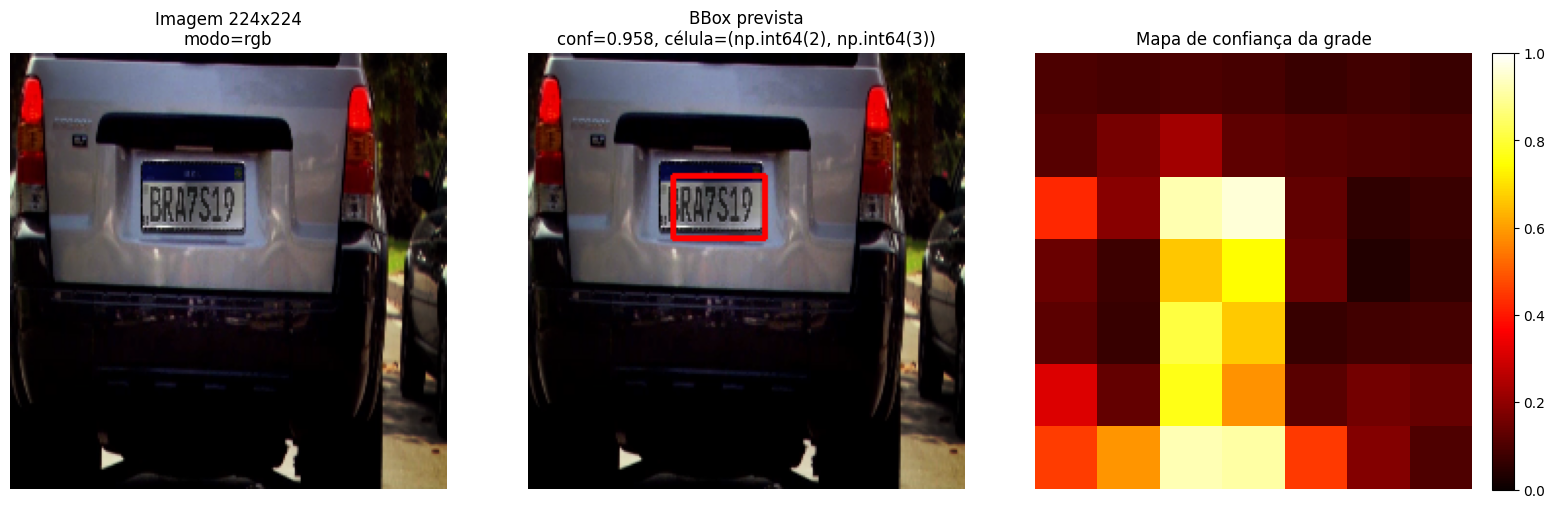

Modo: rgb
Confiança máxima: 0.957778811454773
Célula escolhida: (np.int64(2), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.43738768 0.3557394  0.21252747 0.14469521]


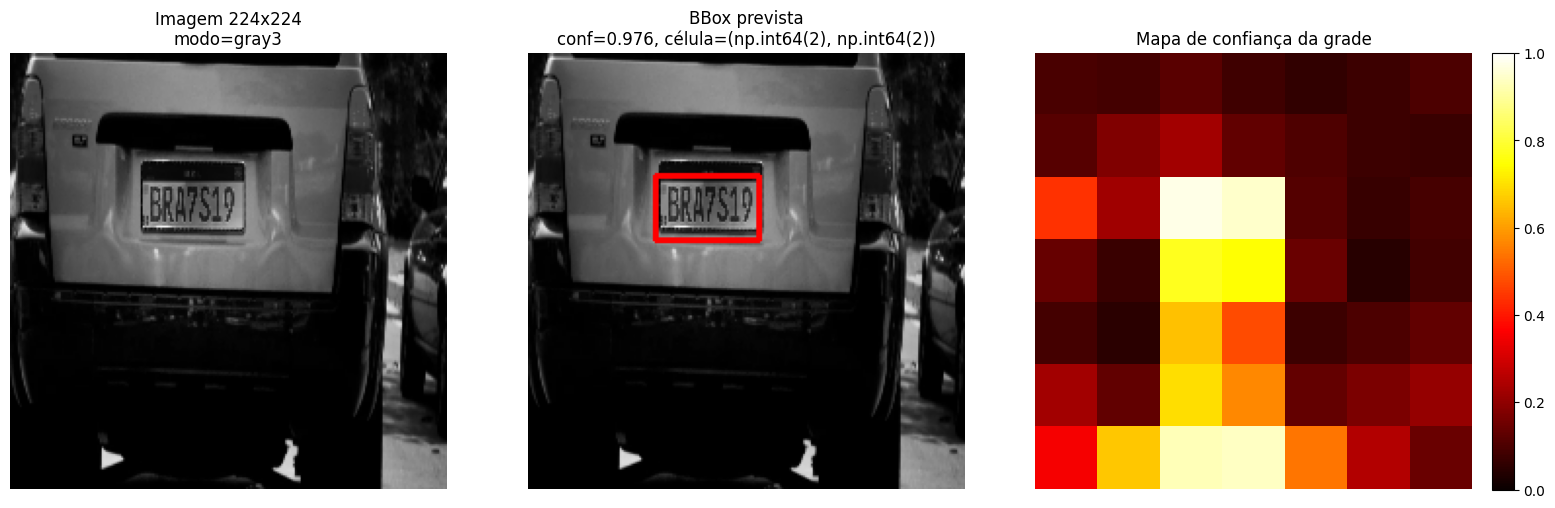

Modo: gray3
Confiança máxima: 0.9755482077598572
Célula escolhida: (np.int64(2), np.int64(2))
BBox prevista [cx, cy, w, h]: [0.4107242  0.357447   0.23242801 0.14573708]


(array([0.4107242 , 0.357447  , 0.23242801, 0.14573708], dtype=float32),
 0.9755482077598572,
 array([[[0.09563223, 0.6129633 , 0.5257742 , 0.19421236, 0.15242599],
         [0.0886948 , 0.5255382 , 0.656942  , 0.26822948, 0.2288032 ],
         [0.11902445, 0.7447738 , 0.7468541 , 0.3299201 , 0.22730462],
         [0.08011694, 0.27404028, 0.819642  , 0.41325626, 0.38124737],
         [0.05920104, 0.63898724, 0.58333814, 0.5247529 , 0.5734356 ],
         [0.07559828, 0.80106056, 0.5222333 , 0.5700654 , 0.61956024],
         [0.09820906, 0.6819429 , 0.6235761 , 0.40976223, 0.48095736]],
 
        [[0.11702771, 0.66713995, 0.7326529 , 0.15041605, 0.10629923],
         [0.17776288, 0.6444312 , 0.89034885, 0.24430002, 0.15244398],
         [0.22670527, 0.84233576, 0.9516341 , 0.28986874, 0.12803623],
         [0.12917288, 0.05654882, 0.962187  , 0.48104838, 0.1934849 ],
         [0.10390012, 0.2498825 , 0.82029516, 0.57354385, 0.26473325],
         [0.07507069, 0.6483364 , 0.49983412, 0.738

In [ ]:
CAMINHO_IMAGEM_TESTE = "/content/large.png"
testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_TESTE, modo_cor="rgb")
testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_TESTE, modo_cor="gray3")

## 10.Segmentação da Região da Placa

Após a detecção da placa pelo modelo, é realizada uma etapa de pós-processamento para segmentação da região de interesse (ROI).

Inicialmente, a bounding box prevista é utilizada para recortar a área correspondente à placa. Em seguida, técnicas clássicas de processamento digital de imagens são aplicadas para destacar os caracteres presentes na placa. Entre as operações empregadas estão ajustes de contraste, transformações morfológicas e limiarização adaptativa.

O objetivo dessa etapa é separar os caracteres do fundo da placa, produzindo uma representação binária que facilite análises posteriores, como reconhecimento óptico de caracteres (OCR).

Embora a segmentação não faça parte da arquitetura da rede neural, ela complementa o processo de detecção ao permitir uma visualização mais clara dos caracteres presentes na região identificada pelo detector.

In [ ]:
### 10.SEGMENTAÇÃO - CARACTERES DA PLACA
def expandir_bbox_pixel(x1, y1, x2, y2, img_w, img_h, padding=0.06):
    """
    Expande levemente a bbox para incluir bordas da placa.
    """
    bw = x2 - x1
    bh = y2 - y1

    pad_x = int(bw * padding)
    pad_y = int(bh * padding)

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(img_w - 1, x2 + pad_x)
    y2 = min(img_h - 1, y2 + pad_y)

    return x1, y1, x2, y2


def segmentar_roi_placa_otsu(
    img_rgb,
    bbox_yolo,
    padding=0.06,
    escala=4
):
    """
    Segmenta a ROI da placa destacando principalmente os caracteres.

    Estratégia:
      1. Recorta a placa usando a bbox;
      2. Aumenta a ROI para melhorar a segmentação visual;
      3. Converte para cinza;
      4. Aplica CLAHE;
      5. Usa BlackHat para destacar regiões escuras sobre fundo claro;
      6. Aplica threshold adaptativo;
      7. Remove bordas externas da placa;
      8. Filtra componentes pequenos ou muito grandes.

    Retorna o mesmo formato usado pela função de visualização:
      roi, mascara, segmentada, bbox_pixel
    """

    img_h, img_w = img_rgb.shape[:2]

    x1, y1, x2, y2 = bbox_yolo_para_pixel(
        bbox_yolo,
        img_w,
        img_h
    )

    x1, y1, x2, y2 = expandir_bbox_pixel(
        x1, y1, x2, y2,
        img_w, img_h,
        padding=padding
    )

    roi = img_rgb[y1:y2, x1:x2].copy()

    if roi.size == 0:
        mask_vazia = np.zeros((10, 10), dtype=np.uint8)
        return {
            "roi": roi,
            "mascara": mask_vazia,
            "segmentada": roi,
            "bbox_pixel": (x1, y1, x2, y2)
        }

    # --------------------------------------------------------
    # 1. Aumentar ROI para melhorar a visualização/segmentação
    # --------------------------------------------------------
    h_roi, w_roi = roi.shape[:2]

    roi_up = cv2.resize(
        roi,
        (w_roi * escala, h_roi * escala),
        interpolation=cv2.INTER_CUBIC
    )

    gray = cv2.cvtColor(roi_up, cv2.COLOR_RGB2GRAY)

    # --------------------------------------------------------
    # 2. Melhorar contraste local
    # --------------------------------------------------------
    clahe = cv2.createCLAHE(
        clipLimit=2.5,
        tileGridSize=(4, 4)
    )
    gray_eq = clahe.apply(gray)

    # Suavização preservando bordas
    gray_eq = cv2.bilateralFilter(gray_eq, d=5, sigmaColor=50, sigmaSpace=50)

    # --------------------------------------------------------
    # 3. BlackHat: realça caracteres escuros em fundo claro
    # --------------------------------------------------------
    h, w = gray_eq.shape[:2]

    kernel_w = max(9, w // 6)
    kernel_h = max(3, h // 4)

    kernel_blackhat = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (kernel_w, kernel_h)
    )

    blackhat = cv2.morphologyEx(
        gray_eq,
        cv2.MORPH_BLACKHAT,
        kernel_blackhat
    )

    # --------------------------------------------------------
    # 4. Threshold adaptativo + Otsu no BlackHat
    # --------------------------------------------------------
    _, mask_otsu = cv2.threshold(
        blackhat,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    mask_adapt = cv2.adaptiveThreshold(
        gray_eq,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        21,
        7
    )

    # Combina as duas máscaras
    mask = cv2.bitwise_or(mask_otsu, mask_adapt)

    # --------------------------------------------------------
    # 5. Remover bordas externas da placa
    # --------------------------------------------------------
    margem_x = int(0.04 * w)
    margem_y = int(0.16 * h)

    mask[:margem_y, :] = 0
    mask[h - margem_y:, :] = 0
    mask[:, :margem_x] = 0
    mask[:, w - margem_x:] = 0

    # --------------------------------------------------------
    # 6. Morfologia leve
    # --------------------------------------------------------
    kernel_open = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)

    # --------------------------------------------------------
    # 7. Filtrar componentes conectados
    # --------------------------------------------------------
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )

    mask_filtrada = np.zeros_like(mask)

    area_total = h * w

    for i in range(1, num_labels):
        x, y, ww, hh, area = stats[i]

        area_frac = area / area_total
        altura_frac = hh / h
        largura_frac = ww / w

        toca_borda = (
            x <= 1 or y <= 1 or
            x + ww >= w - 1 or
            y + hh >= h - 1
        )

        # Remove sujeira muito pequena, bordas grandes e faixas horizontais
        if toca_borda:
            continue

        if area_frac < 0.001:
            continue

        if area_frac > 0.20:
            continue

        if altura_frac < 0.12:
            continue

        if largura_frac > 0.45:
            continue

        mask_filtrada[labels == i] = 255

    # Caso a filtragem fique agressiva demais, usa a máscara anterior
    if np.sum(mask_filtrada > 0) < 0.01 * area_total:
        mask_filtrada = mask

    # --------------------------------------------------------
    # 8. Aplicar máscara
    # --------------------------------------------------------
    segmentada = cv2.bitwise_and(
        roi_up,
        roi_up,
        mask=mask_filtrada
    )

    return {
        "roi": roi_up,
        "mascara": mask_filtrada,
        "segmentada": segmentada,
        "bbox_pixel": (x1, y1, x2, y2)
    }

In [ ]:
# ============================================================
# 10.1 TESTE DO DETECTOR COM SEGMENTAÇÃO
# Usa a função segmentar_roi_placa_otsu() definida acima
# ============================================================

def testar_imagem_grid_com_segmentacao(
    modelo,
    img_path_ou_array,
    bbox_real=None,
    modo_cor="gray3",
    limiar_conf=0.0,
    padding_segmentacao=0.06
):
    """
    Executa o detector por grade em uma imagem e aplica segmentação
    na região da placa detectada.

    Exibe:
      1. Imagem de entrada;
      2. BBox prevista;
      3. Mapa de confiança da grade;
      4. ROI da placa;
      5. Máscara segmentada;
      6. Placa segmentada.
    """

    # --------------------------------------------------------
    # 1. Carregar imagem
    # --------------------------------------------------------
    if isinstance(img_path_ou_array, str):
        img_bgr = cv2.imread(img_path_ou_array)

        if img_bgr is None:
            raise FileNotFoundError(f"Imagem não encontrada: {img_path_ou_array}")

        img_rgb_original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    else:
        img_rgb_original = img_path_ou_array.copy()

    # --------------------------------------------------------
    # 2. Definir modo de cor
    # --------------------------------------------------------
    if modo_cor == "rgb":
        img_rgb = img_rgb_original

    elif modo_cor == "gray3":
        img_gray = cv2.cvtColor(img_rgb_original, cv2.COLOR_RGB2GRAY)
        img_rgb = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)

    else:
        raise ValueError("modo_cor deve ser 'rgb' ou 'gray3'.")

    # --------------------------------------------------------
    # 3. Pré-processamento para o modelo
    # --------------------------------------------------------
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_norm = (img_resized.astype(np.float32) / 127.5) - 1.0

    # --------------------------------------------------------
    # 4. Inferência do modelo grid
    # --------------------------------------------------------
    pred_grid = modelo.predict(
        np.expand_dims(img_norm, axis=0),
        verbose=0
    )[0]

    # Usa sua função original:
    # retorna bbox, confiança e célula escolhida
    pred_bbox, conf, celula = grade_para_bbox_global(
        pred_grid,
        limiar_conf=limiar_conf
    )

    conf_map = pred_grid[..., 0]

    # --------------------------------------------------------
    # 5. Desenhar bbox
    # --------------------------------------------------------
    img_bbox = img_resized.copy()

    if bbox_real is not None:
        h_img, w_img = img_bbox.shape[:2]

        x1r, y1r, x2r, y2r = bbox_yolo_para_pixel(
            bbox_real,
            w_img,
            h_img
        )

        cv2.rectangle(
            img_bbox,
            (x1r, y1r),
            (x2r, y2r),
            (0, 255, 0),
            2
        )

        cv2.putText(
            img_bbox,
            "real",
            (x1r, max(y1r - 6, 12)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (0, 255, 0),
            1
        )

    if pred_bbox is not None:
        h_img, w_img = img_bbox.shape[:2]

        x1p, y1p, x2p, y2p = bbox_yolo_para_pixel(
            pred_bbox,
            w_img,
            h_img
        )

        cv2.rectangle(
            img_bbox,
            (x1p, y1p),
            (x2p, y2p),
            (255, 0, 0),
            2
        )

        cv2.putText(
            img_bbox,
            f"pred conf={conf:.2f}",
            (x1p, max(y1p - 6, 12)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (255, 0, 0),
            1
        )

    # --------------------------------------------------------
    # 6. Segmentação da ROI
    # --------------------------------------------------------
    if pred_bbox is not None:
        seg = segmentar_roi_placa_otsu(
            img_resized,
            pred_bbox,
            padding=padding_segmentacao
        )

        roi = seg["roi"]
        mascara = seg["mascara"]
        segmentada = seg["segmentada"]

    else:
        roi = np.zeros((20, 20, 3), dtype=np.uint8)
        mascara = np.zeros((20, 20), dtype=np.uint8)
        segmentada = np.zeros((20, 20, 3), dtype=np.uint8)

    # --------------------------------------------------------
    # 7. Visualização
    # --------------------------------------------------------
    plt.figure(figsize=(22, 4))

    plt.subplot(1, 6, 1)
    plt.imshow(img_resized)
    plt.title(f"Imagem {IMG_SIZE}x{IMG_SIZE}\nmodo={modo_cor}")
    plt.axis("off")

    plt.subplot(1, 6, 2)
    plt.imshow(img_bbox)

    titulo_bbox = f"BBox prevista\nconf={conf:.3f} | célula={celula}"

    if bbox_real is not None and pred_bbox is not None:
        iou = calcular_iou_yolo(bbox_real, pred_bbox)
        titulo_bbox += f"\nIoU={iou:.3f}"

    plt.title(titulo_bbox)
    plt.axis("off")

    plt.subplot(1, 6, 3)
    plt.imshow(conf_map, cmap="hot", vmin=0, vmax=1)
    plt.title("Mapa de confiança")
    plt.axis("off")
    plt.colorbar(fraction=0.046, pad=0.04)

    plt.subplot(1, 6, 4)
    plt.imshow(roi)
    plt.title("ROI da placa")
    plt.axis("off")

    plt.subplot(1, 6, 5)
    plt.imshow(mascara, cmap="gray")
    plt.title("Máscara")
    plt.axis("off")

    plt.subplot(1, 6, 6)
    plt.imshow(segmentada)
    plt.title("Placa segmentada")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 8. Informações no console
    # --------------------------------------------------------
    print("Modo:", modo_cor)
    print("Confiança máxima:", conf)
    print("Célula escolhida:", celula)

    if pred_bbox is not None:
        print("BBox prevista [cx, cy, w, h]:", pred_bbox)
    else:
        print("Nenhuma detecção encontrada.")

    return {
        "bbox": pred_bbox,
        "conf": conf,
        "celula": celula,
        "conf_map": conf_map,
        "roi": roi,
        "mascara": mascara,
        "segmentada": segmentada
    }


print("Função testar_imagem_grid_com_segmentacao carregada com sucesso.")

Função testar_imagem_grid_com_segmentacao carregada com sucesso.


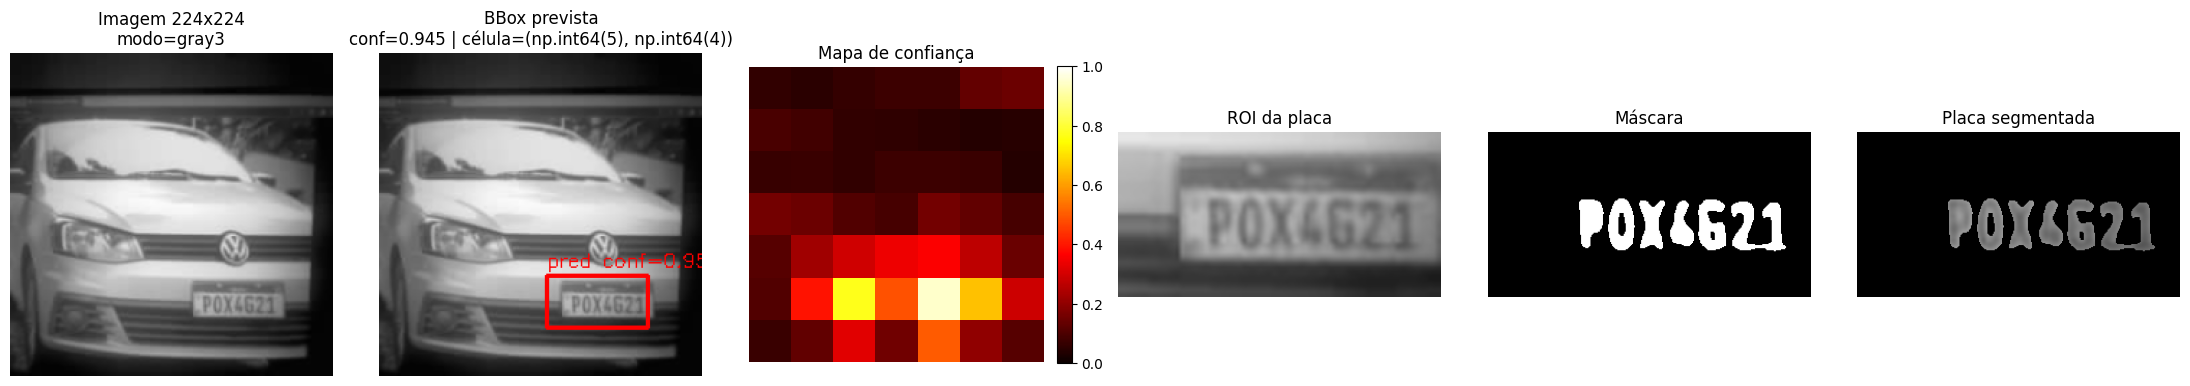

Modo: gray3
Confiança máxima: 0.9454657435417175
Célula escolhida: (np.int64(5), np.int64(4))
BBox prevista [cx, cy, w, h]: [0.67583853 0.7713953  0.31007057 0.16157196]


In [ ]:
CAMINHO_IMAGEM_EXTERNA = "/content/teste2.jpeg"

resultado_seg = testar_imagem_grid_com_segmentacao(
    modelo_grid,
    CAMINHO_IMAGEM_EXTERNA,
    modo_cor="gray3",
    limiar_conf=0.0,
    padding_segmentacao=0.06
)

In [ ]:
import inspect
print(inspect.signature(segmentar_roi_placa_otsu))

(img_rgb, bbox_yolo, padding=0.06, escala=4)


In [ ]:
# SALVAR RESULTADOS DA SEGMENTAÇÃO


import os
import cv2

SEG_DIR = os.path.join(PROJECT_PATH, "resultados_segmentacao")
os.makedirs(SEG_DIR, exist_ok=True)

nome_base = "teste_externo_04"

roi = resultado_seg["roi"]
mascara = resultado_seg["mascara"]
segmentada = resultado_seg["segmentada"]

cv2.imwrite(
    os.path.join(SEG_DIR, f"{nome_base}_roi.png"),
    cv2.cvtColor(roi, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    os.path.join(SEG_DIR, f"{nome_base}_mascara.png"),
    mascara
)

cv2.imwrite(
    os.path.join(SEG_DIR, f"{nome_base}_segmentada.png"),
    cv2.cvtColor(segmentada, cv2.COLOR_RGB2BGR)
)

print("Resultados de segmentação salvos em:")
print(SEG_DIR)

Resultados de segmentação salvos em:
/content/drive/MyDrive/PDI_Embarcados/resultados_segmentacao


## 11. Avaliação em Amostras de Validação e Imagens Externas

Esta etapa reúne os testes qualitativos realizados com imagens dos conjuntos de validação e com imagens externas não utilizadas durante o treinamento.

O objetivo é verificar a capacidade de localização da placa em diferentes cenários e analisar o comportamento espacial do detector. Para cada imagem são exibidos a bounding box prevista e o mapa de confiança gerado pela grade de detecção.

O mapa de confiança permite identificar quais regiões da imagem receberam maior ativação do modelo. Em uma detecção correta, espera-se que as maiores ativações estejam concentradas próximas à região da placa, indicando que o detector aprendeu adequadamente a localização do objeto.

A avaliação visual complementa as métricas quantitativas de desempenho, permitindo analisar a qualidade da localização da bounding box, a robustez do modelo em imagens externas e a capacidade de generalização para diferentes condições de captura.

In [ ]:

# ============================================================
# 11. TESTES VISUAIS
# ============================================================

# Testar algumas amostras da validação mix com bbox real conhecida
for idx in [0, min(5, len(X_val_mix)-1), min(10, len(X_val_mix)-1)]:
    img_uint8 = ((X_val_mix[idx] + 1.0) * 127.5).clip(0, 255).astype(np.uint8)

    # salva temporariamente para reutilizar a função de imagem externa
    temp_path = f"/content/temp_grid_val_{idx}.jpg"
    cv2.imwrite(temp_path, cv2.cvtColor(img_uint8, cv2.COLOR_RGB2BGR))

    testar_imagem_grid(
        modelo_grid,
        temp_path,
        bbox_real=y_val_mix[idx],
        modo_cor="rgb"
    )

# Teste em imagem externa:
# CAMINHO_IMAGEM_EXTERNA = "/content/images.jpg"
# testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_EXTERNA, modo_cor="rgb")
# testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_EXTERNA, modo_cor="gray3")


NameError: name 'testar_imagem_grid' is not defined

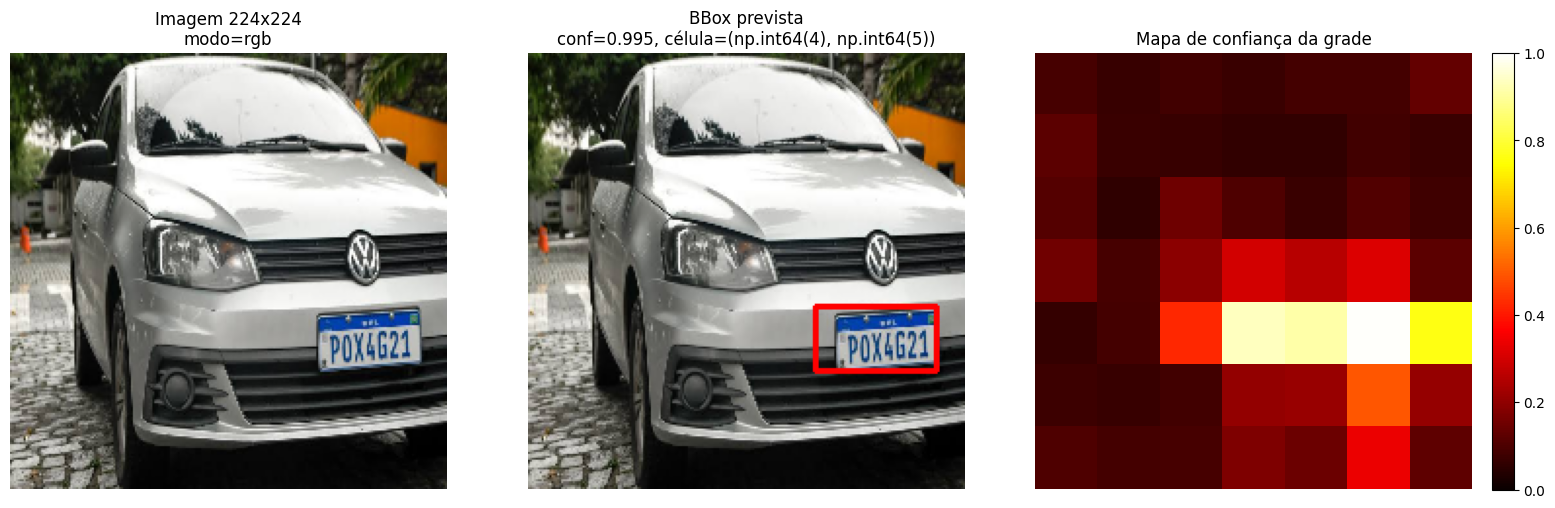

Modo: rgb
Confiança máxima: 0.9951485395431519
Célula escolhida: (np.int64(4), np.int64(5))
BBox prevista [cx, cy, w, h]: [0.7969951  0.65509117 0.27324504 0.14562622]


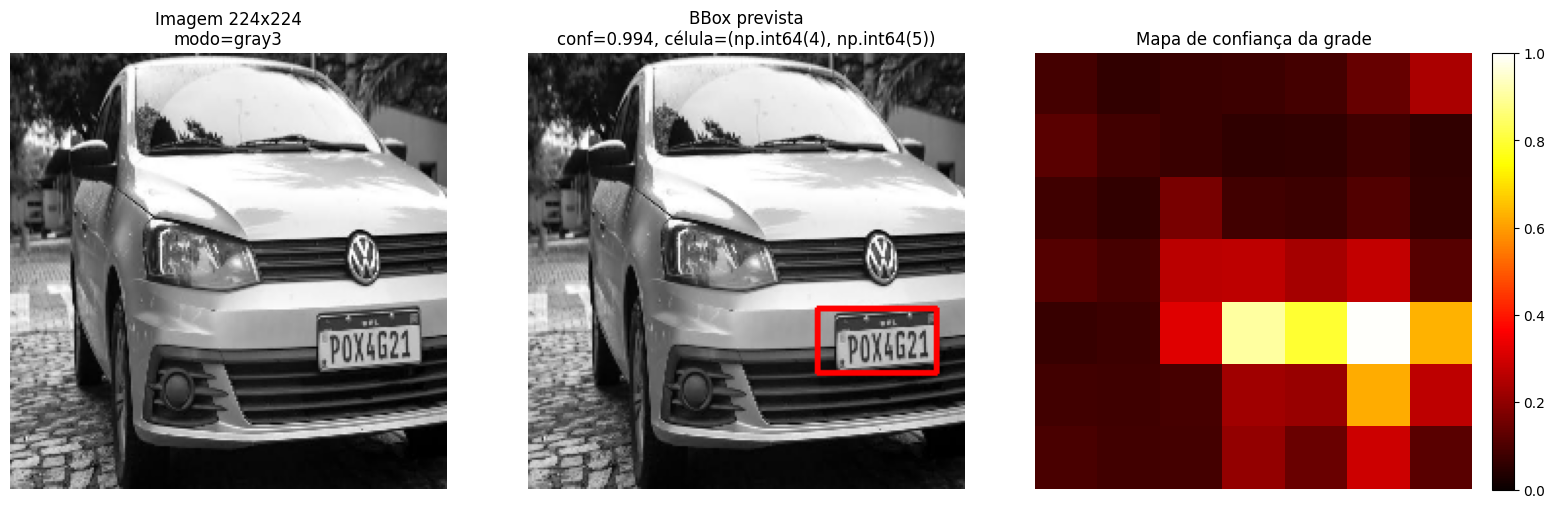

Modo: gray3
Confiança máxima: 0.9940086603164673
Célula escolhida: (np.int64(4), np.int64(5))
BBox prevista [cx, cy, w, h]: [0.79897213 0.66205263 0.2693881  0.14733787]


(array([0.79897213, 0.66205263, 0.2693881 , 0.14733787], dtype=float32),
 0.9940086603164673,
 array([[[0.08860609, 0.07759744, 0.2846389 , 0.89006215, 0.9213905 ],
         [0.06182305, 0.15440767, 0.11506282, 0.90964246, 0.9837067 ],
         [0.07181497, 0.472074  , 0.1435922 , 0.7346779 , 0.9672598 ],
         [0.07798562, 0.54788125, 0.13016723, 0.628639  , 0.91975117],
         [0.0869149 , 0.6862565 , 0.13211553, 0.48486122, 0.76430464],
         [0.13742727, 0.65986526, 0.25226468, 0.38110495, 0.49074847],
         [0.24107991, 0.568454  , 0.4971511 , 0.2084754 , 0.1965368 ]],
 
        [[0.11748978, 0.12259642, 0.4948598 , 0.52057105, 0.72475946],
         [0.0853475 , 0.5716146 , 0.26192495, 0.37287083, 0.7327771 ],
         [0.07295953, 0.72522205, 0.3761855 , 0.21976382, 0.34512264],
         [0.05652057, 0.5731278 , 0.3541048 , 0.18030517, 0.23603366],
         [0.05950391, 0.74211866, 0.30247992, 0.1597199 , 0.21011211],
         [0.07964255, 0.5268842 , 0.29601738, 0.170

In [ ]:
# Teste em imagem externa:
CAMINHO_IMAGEM_EXTERNA = "/content/images.jpg"
testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_EXTERNA, modo_cor="rgb")
testar_imagem_grid(modelo_grid, CAMINHO_IMAGEM_EXTERNA, modo_cor="gray3")


Teste visual 1/20 | índice = 6


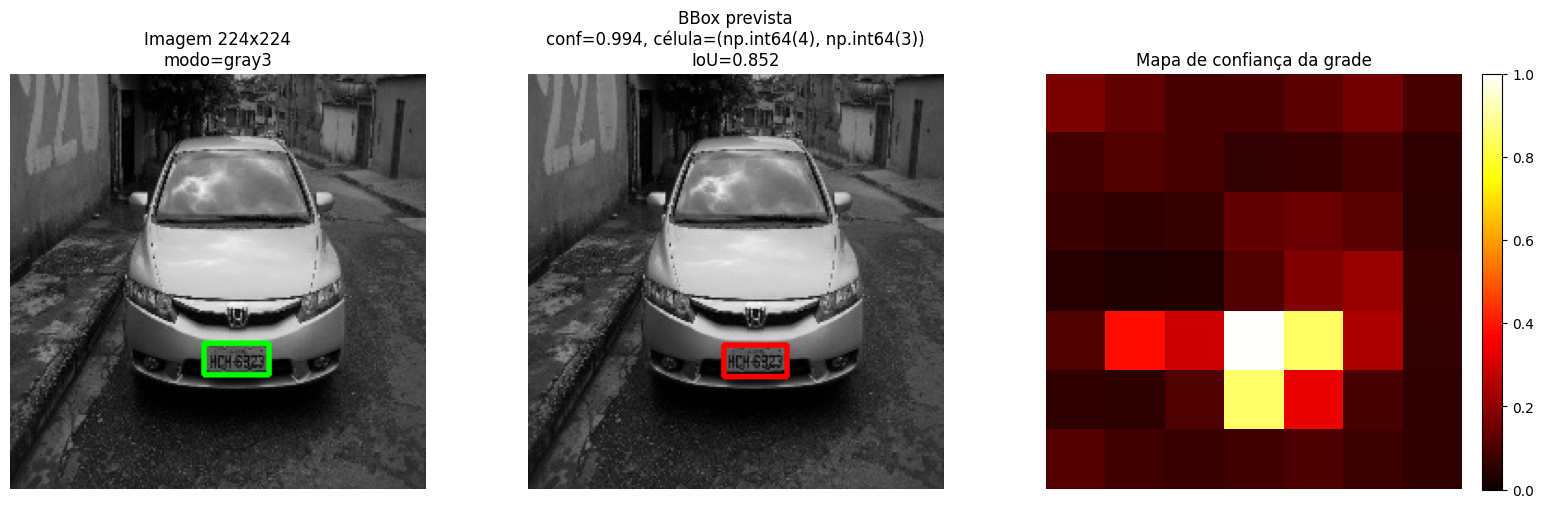

Modo: gray3
Confiança máxima: 0.9940025210380554
Célula escolhida: (np.int64(4), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.5462907  0.69191176 0.1493635  0.07571892]
Teste visual 2/20 | índice = 67


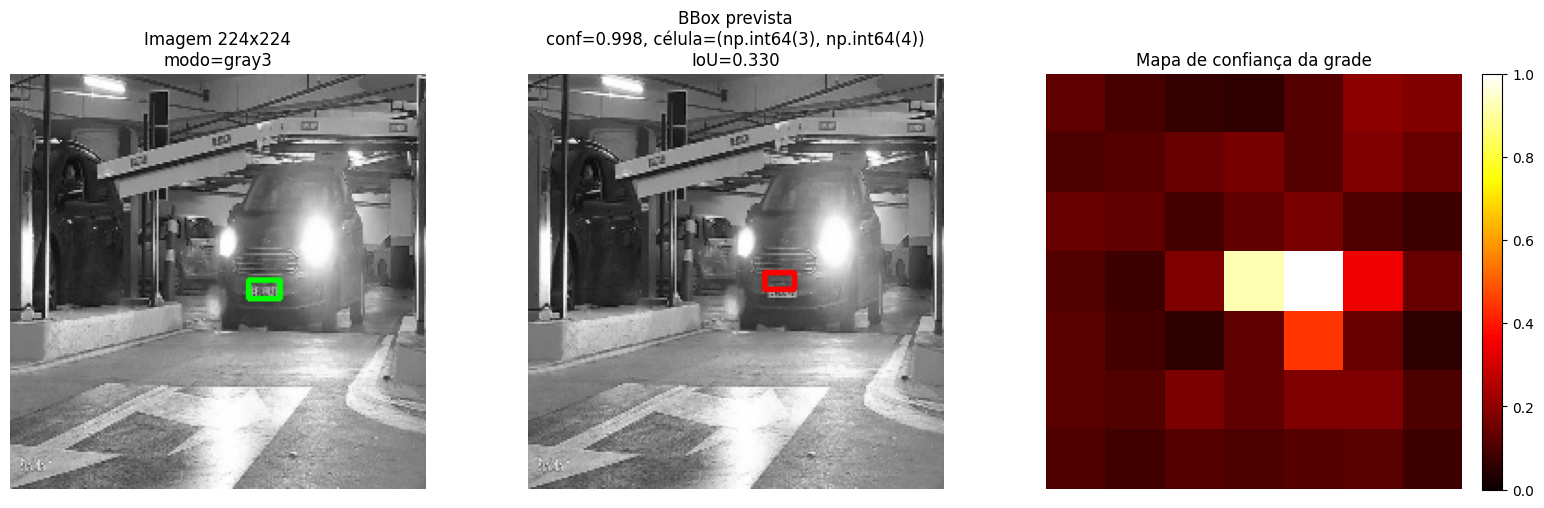

Modo: gray3
Confiança máxima: 0.9978585839271545
Célula escolhida: (np.int64(3), np.int64(4))
BBox prevista [cx, cy, w, h]: [0.60646605 0.4999531  0.07068434 0.04405558]
Teste visual 3/20 | índice = 63


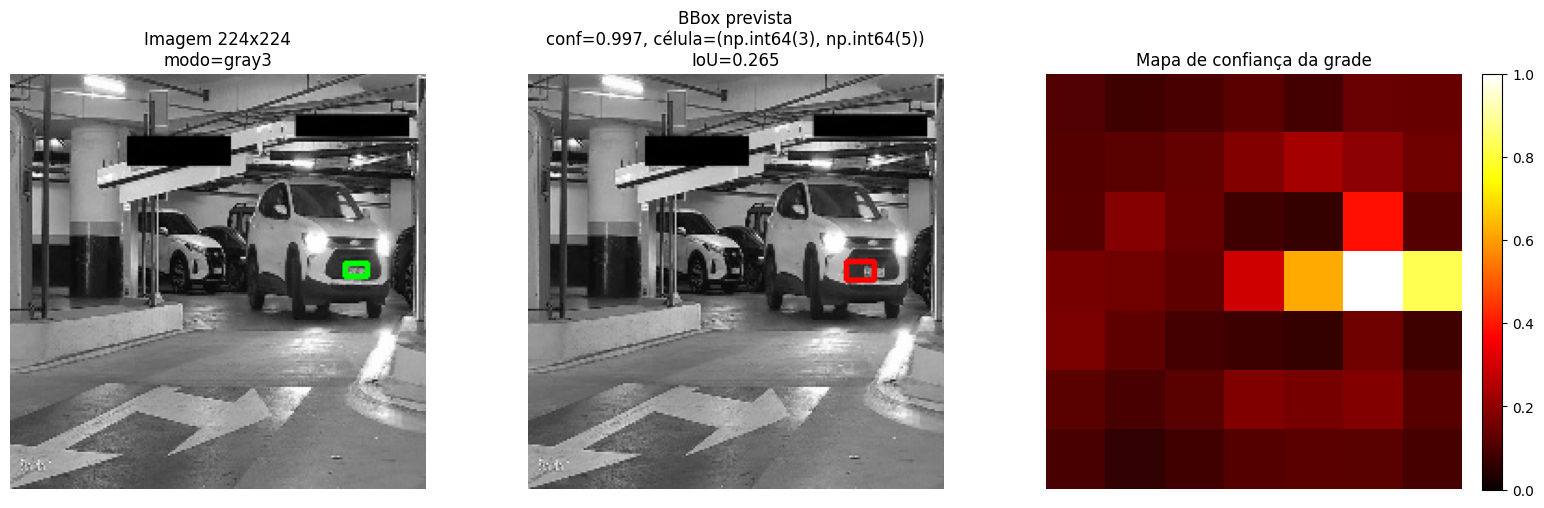

Modo: gray3
Confiança máxima: 0.9974623918533325
Célula escolhida: (np.int64(3), np.int64(5))
BBox prevista [cx, cy, w, h]: [0.80064887 0.47484568 0.06772095 0.04553703]
Teste visual 4/20 | índice = 42


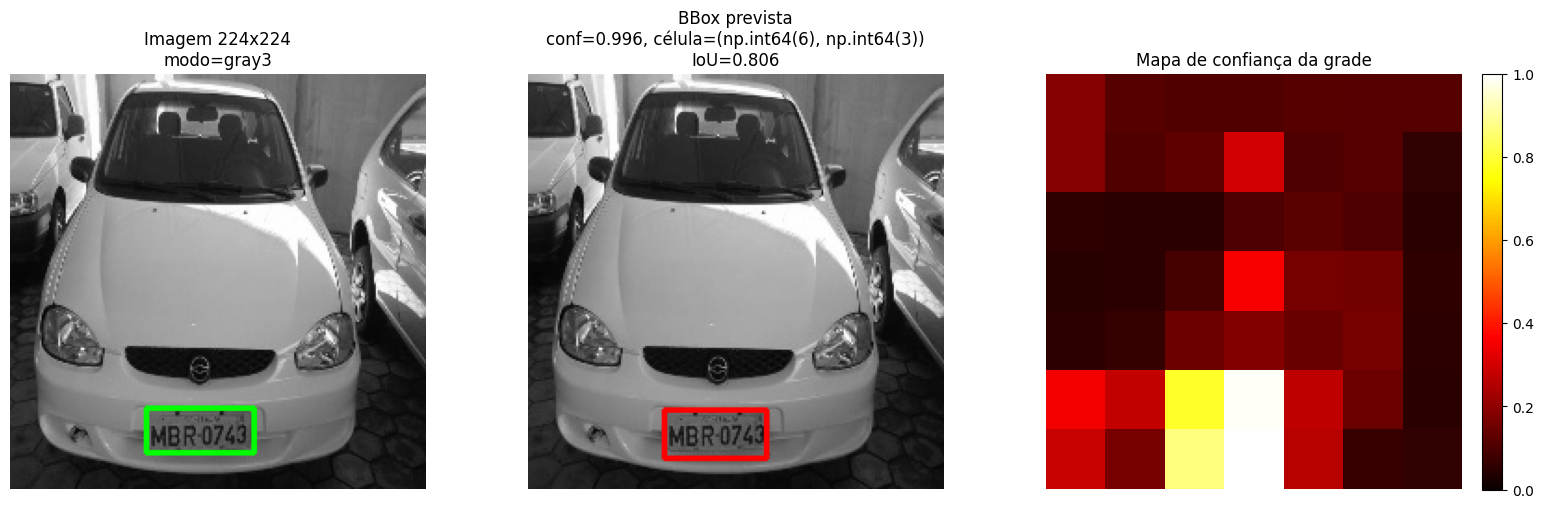

Modo: gray3
Confiança máxima: 0.9962400197982788
Célula escolhida: (np.int64(6), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.45085514 0.8685852  0.24193016 0.11718646]
Teste visual 5/20 | índice = 55


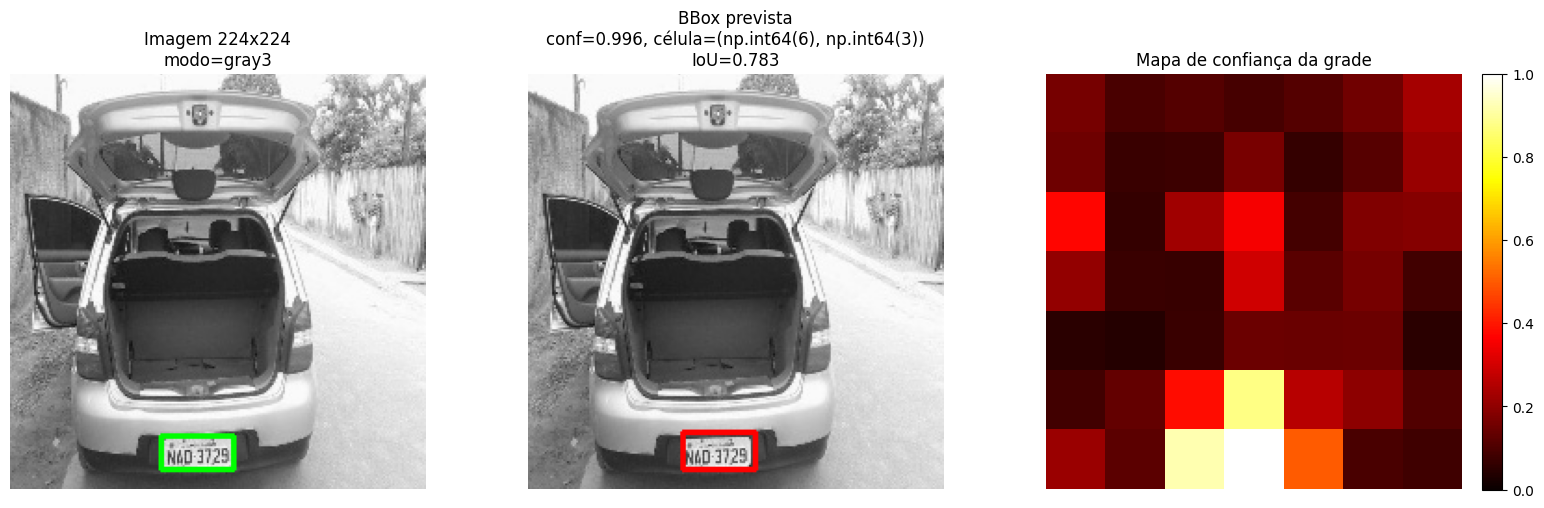

Modo: gray3
Confiança máxima: 0.9962077140808105
Célula escolhida: (np.int64(6), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.45938402 0.9067331  0.17602189 0.08975396]
Teste visual 6/20 | índice = 39


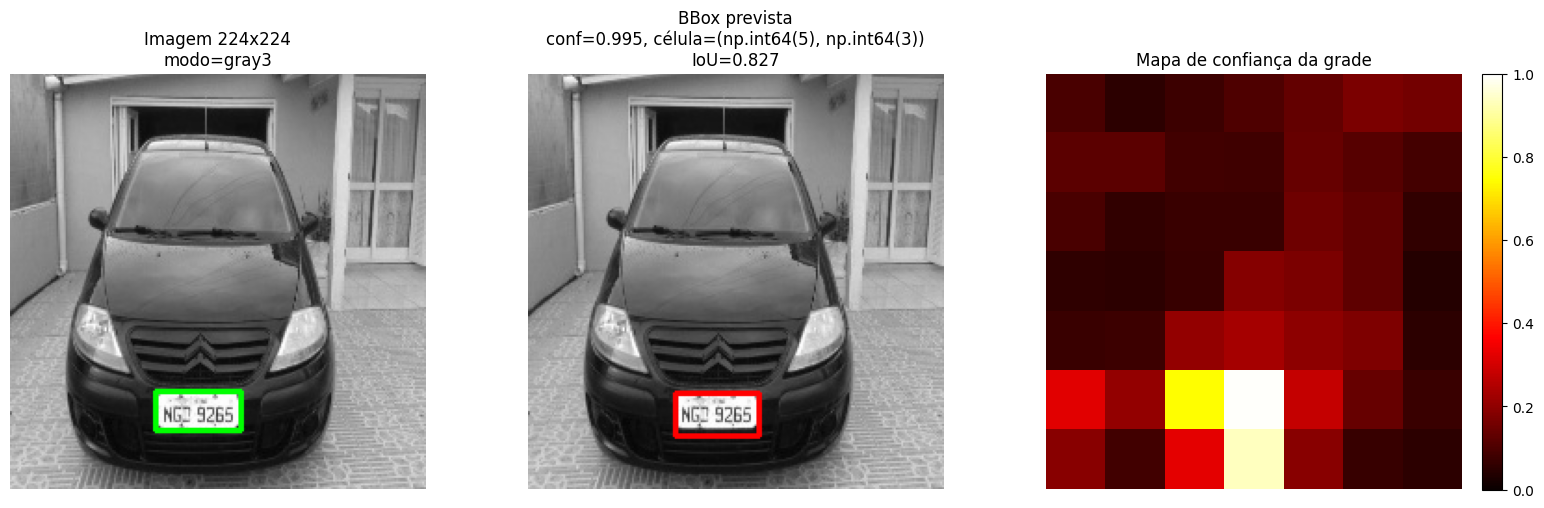

Modo: gray3
Confiança máxima: 0.9951629638671875
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.45472562 0.8200195  0.20165548 0.10122032]
Teste visual 7/20 | índice = 21


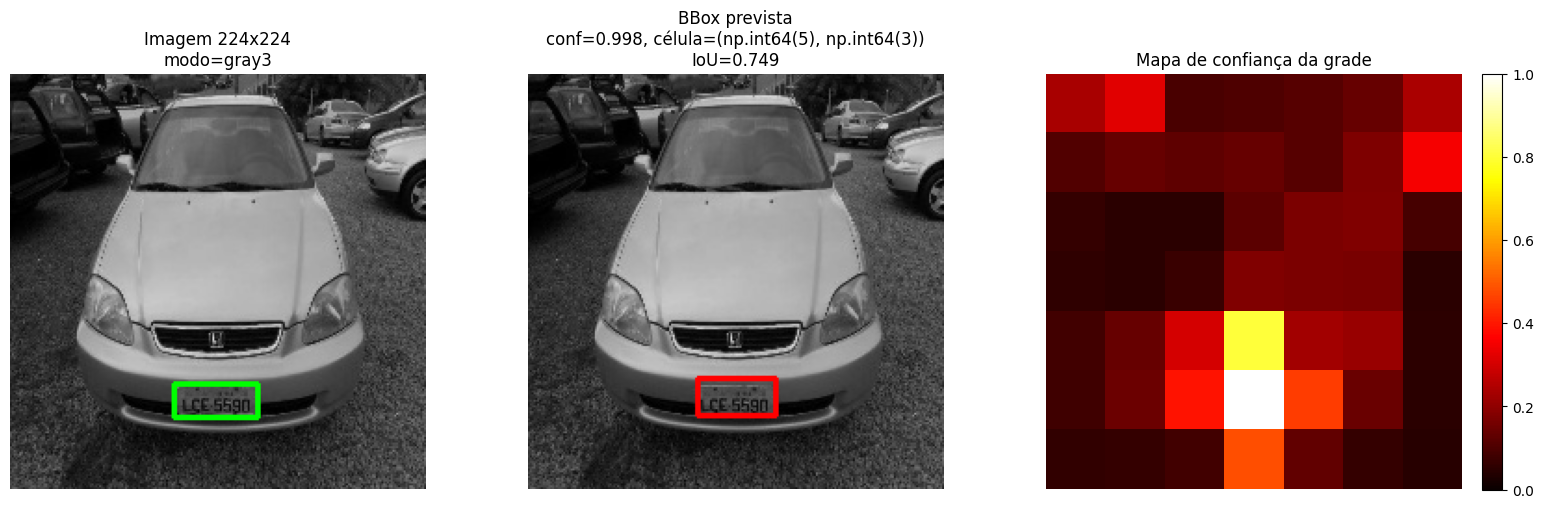

Modo: gray3
Confiança máxima: 0.9976951479911804
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.5032443  0.7782314  0.18665409 0.09214956]
Teste visual 8/20 | índice = 16


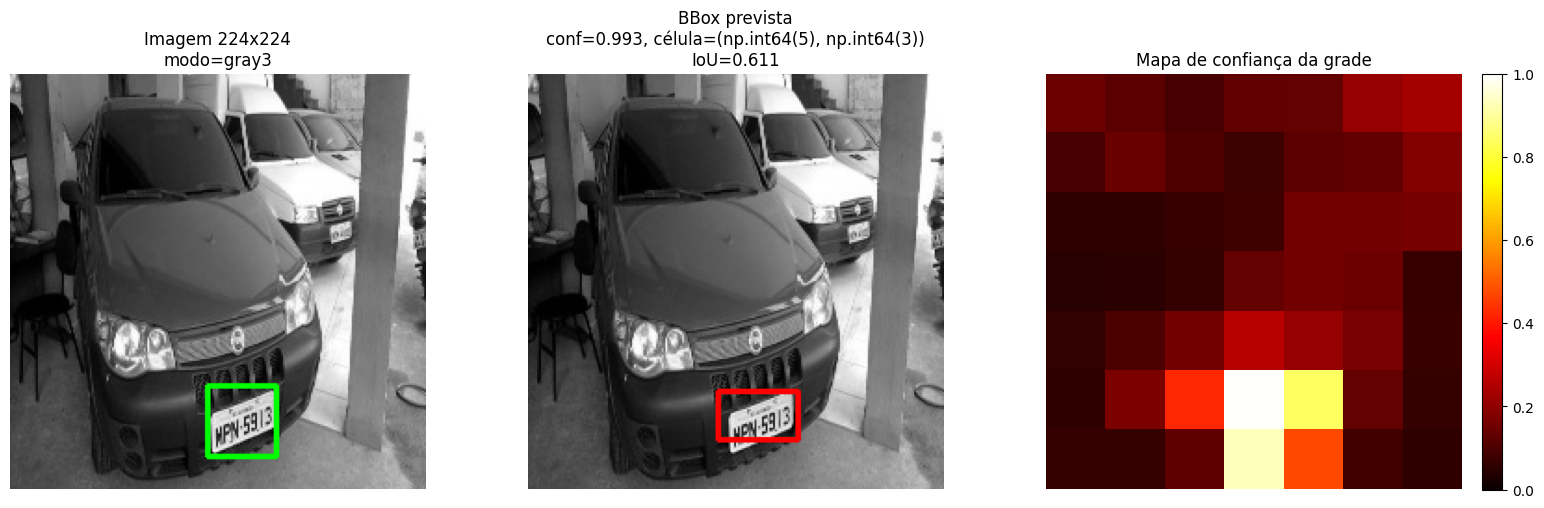

Modo: gray3
Confiança máxima: 0.9931107759475708
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.55177295 0.8228148  0.1919689  0.11359623]
Teste visual 9/20 | índice = 53


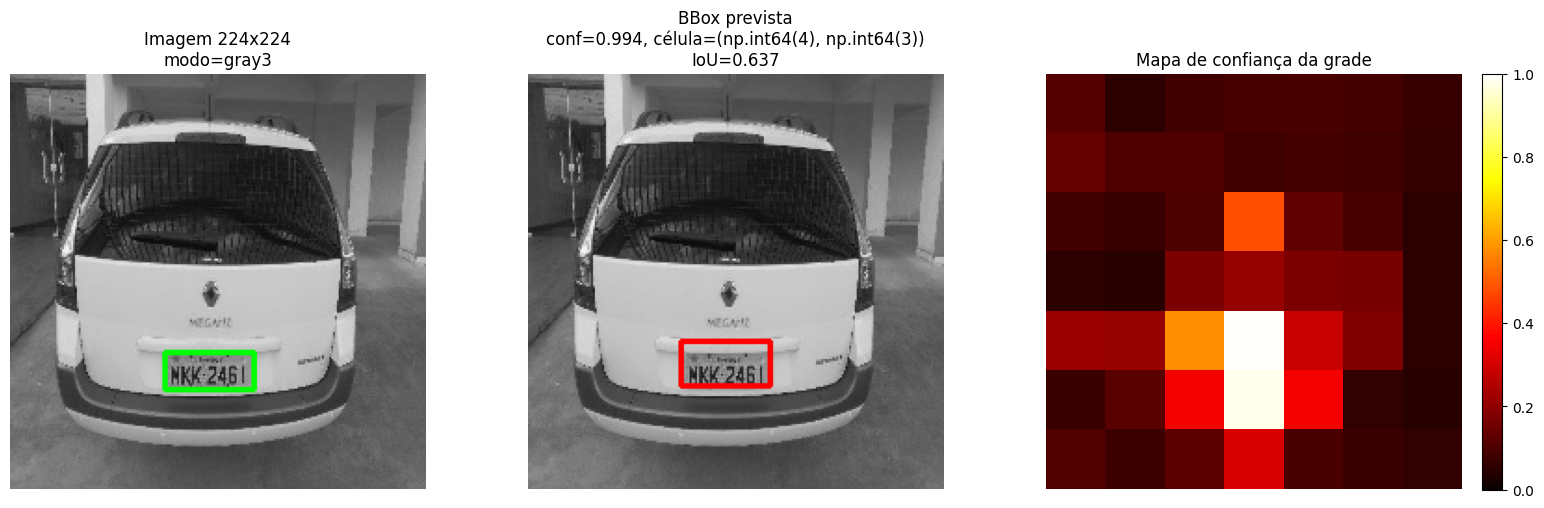

Modo: gray3
Confiança máxima: 0.9943539500236511
Célula escolhida: (np.int64(4), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.47517666 0.69782203 0.21162635 0.10454643]
Teste visual 10/20 | índice = 7


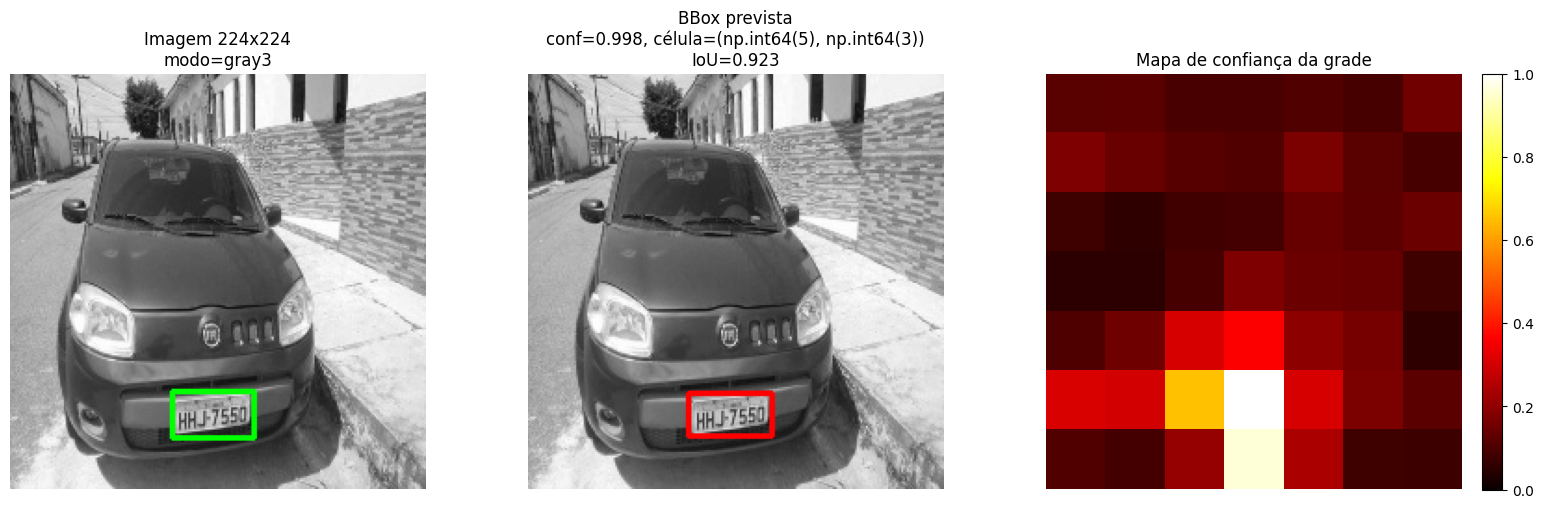

Modo: gray3
Confiança máxima: 0.9984980821609497
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.48631454 0.8203827  0.19788314 0.1030566 ]
Teste visual 11/20 | índice = 43


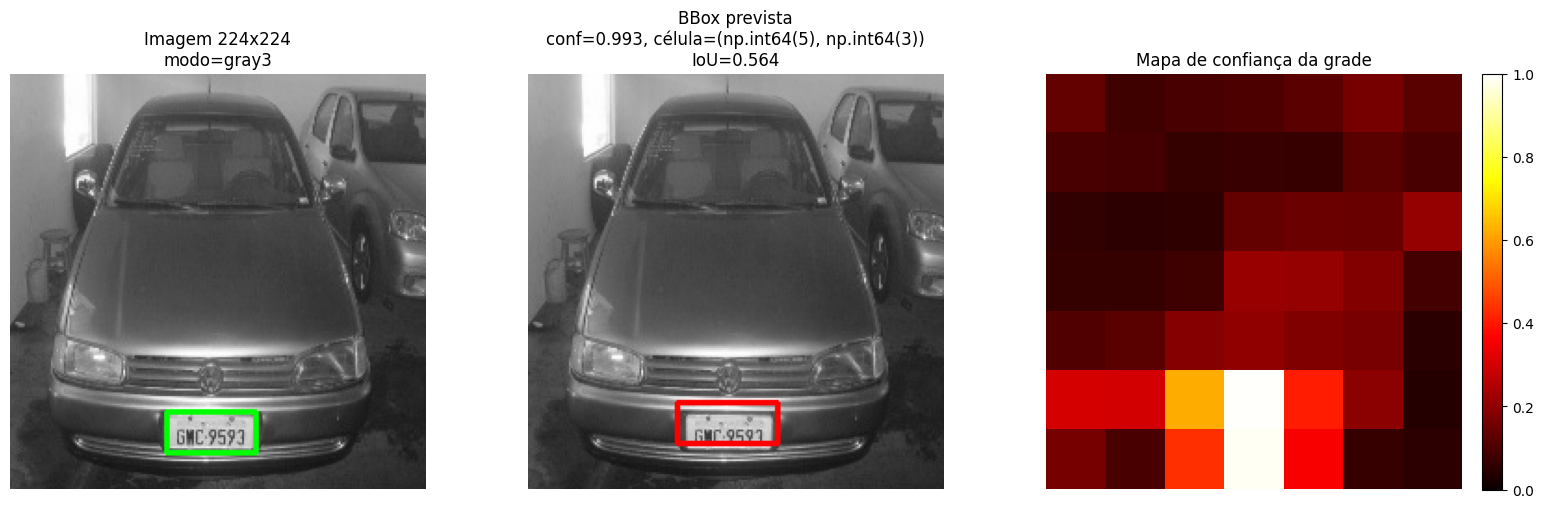

Modo: gray3
Confiança máxima: 0.9929068088531494
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.47794086 0.841405   0.24057703 0.10028131]
Teste visual 12/20 | índice = 57


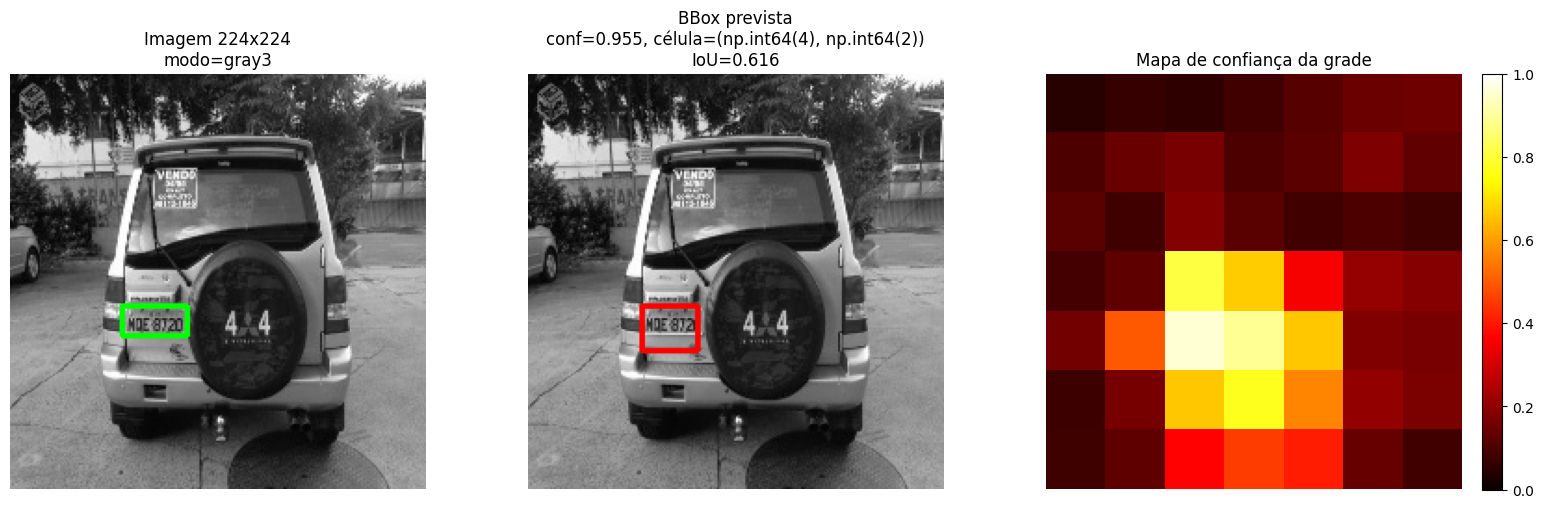

Modo: gray3
Confiança máxima: 0.954705536365509
Célula escolhida: (np.int64(4), np.int64(2))
BBox prevista [cx, cy, w, h]: [0.34010458 0.6121682  0.13316432 0.10734967]
Teste visual 13/20 | índice = 48


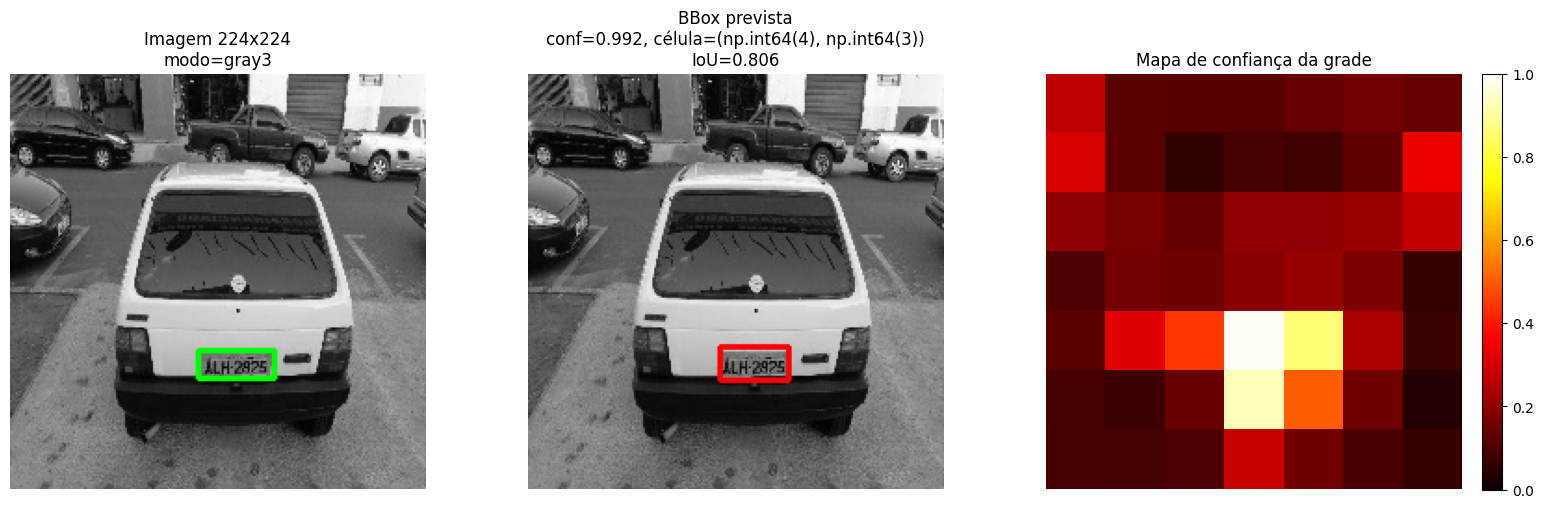

Modo: gray3
Confiança máxima: 0.9916682839393616
Célula escolhida: (np.int64(4), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.5443572  0.697247   0.16650005 0.07925718]
Teste visual 14/20 | índice = 65


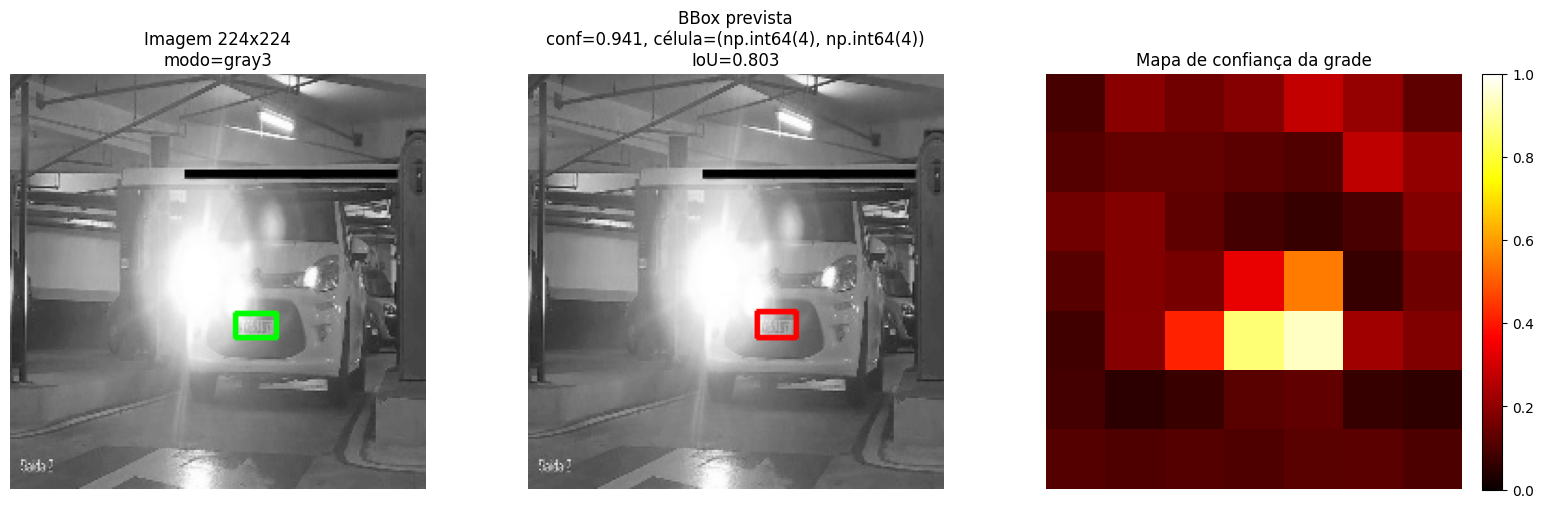

Modo: gray3
Confiança máxima: 0.9412863254547119
Célula escolhida: (np.int64(4), np.int64(4))
BBox prevista [cx, cy, w, h]: [0.5987172  0.6048095  0.0948405  0.05964824]
Teste visual 15/20 | índice = 40


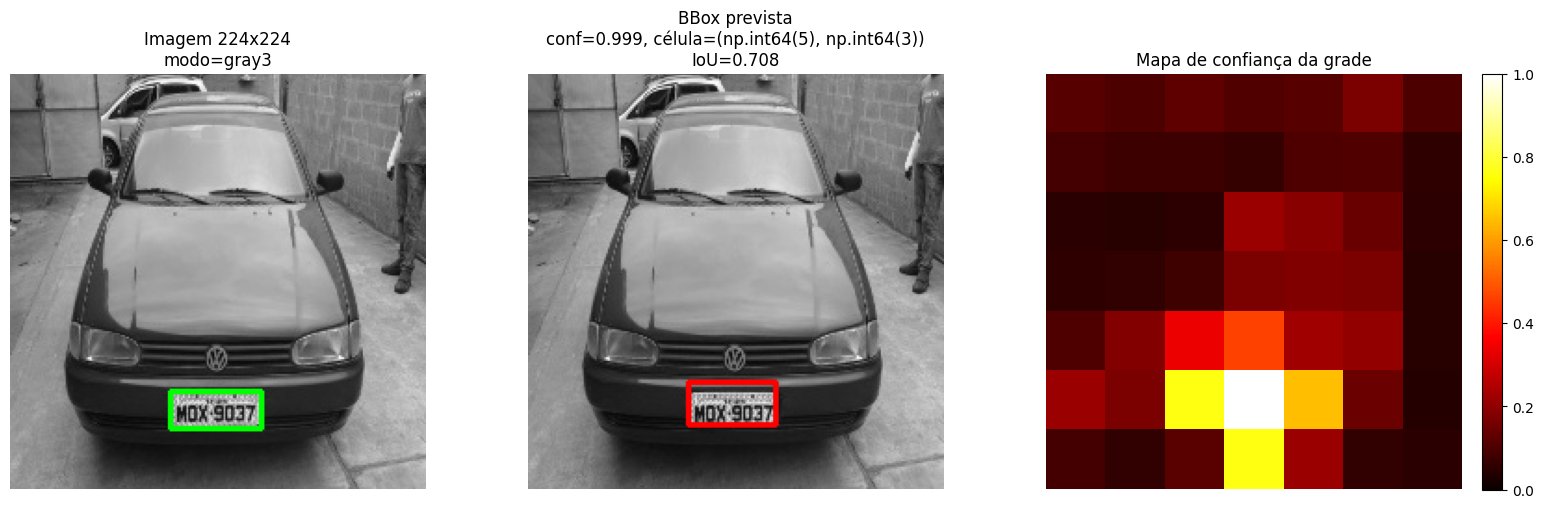

Modo: gray3
Confiança máxima: 0.9987799525260925
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.48969012 0.7954541  0.20816392 0.10187118]
Teste visual 16/20 | índice = 10


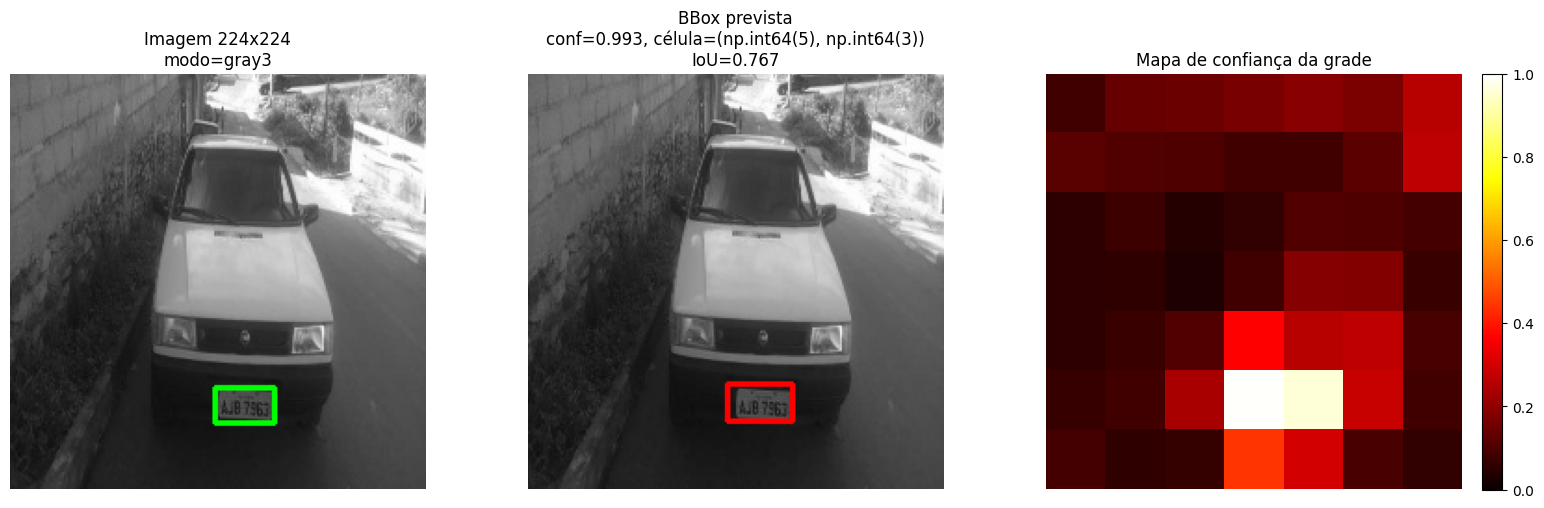

Modo: gray3
Confiança máxima: 0.9927693605422974
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.5583867  0.7920082  0.15713349 0.08731234]
Teste visual 17/20 | índice = 58


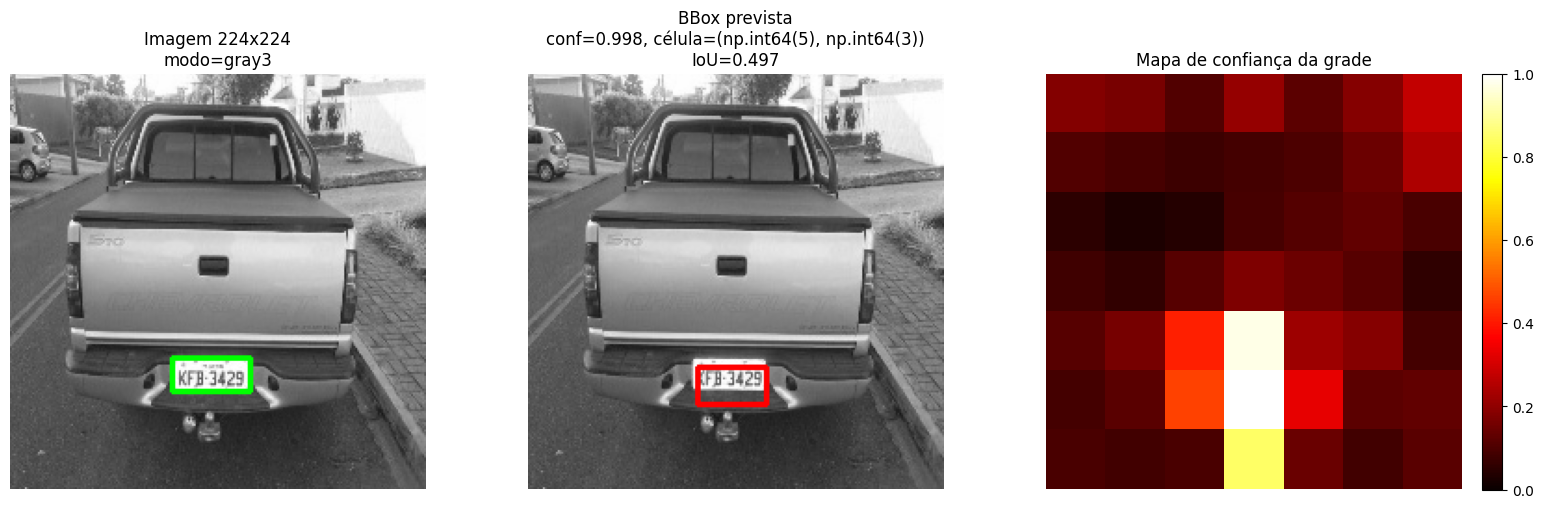

Modo: gray3
Confiança máxima: 0.9980401396751404
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.4915017  0.7515002  0.16858506 0.09122904]
Teste visual 18/20 | índice = 32


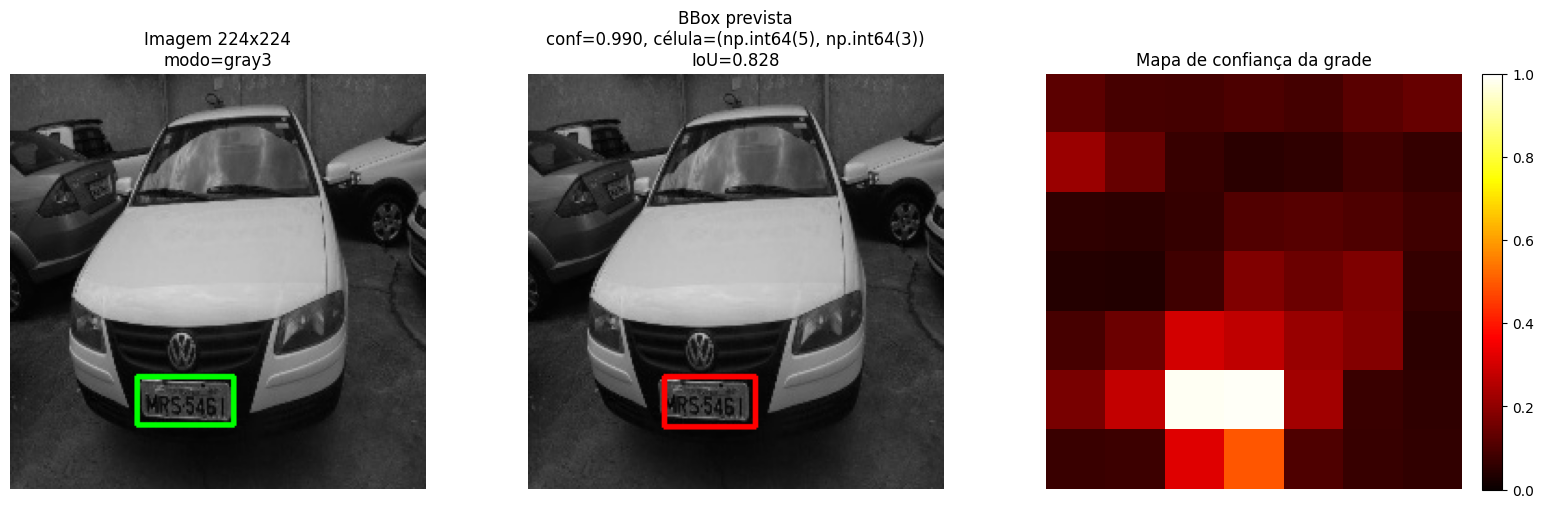

Modo: gray3
Confiança máxima: 0.9903182983398438
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.438984   0.7882775  0.22008969 0.12017576]
Teste visual 19/20 | índice = 30


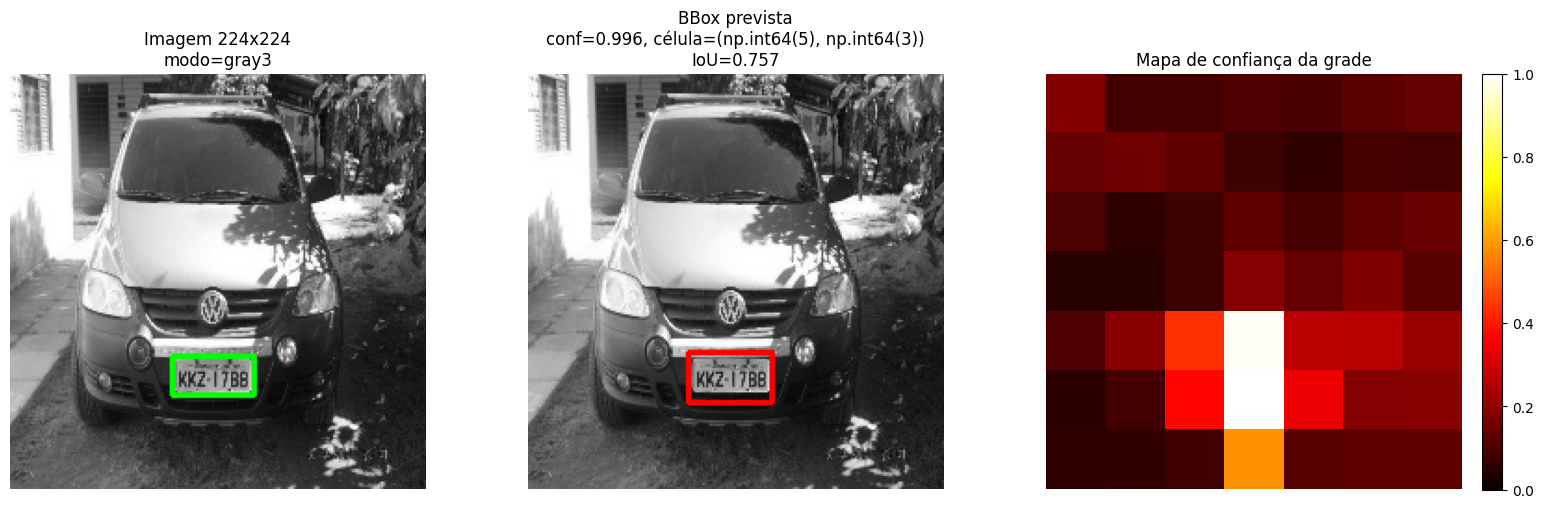

Modo: gray3
Confiança máxima: 0.996426522731781
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.4865693  0.7323188  0.19959627 0.11938616]
Teste visual 20/20 | índice = 18


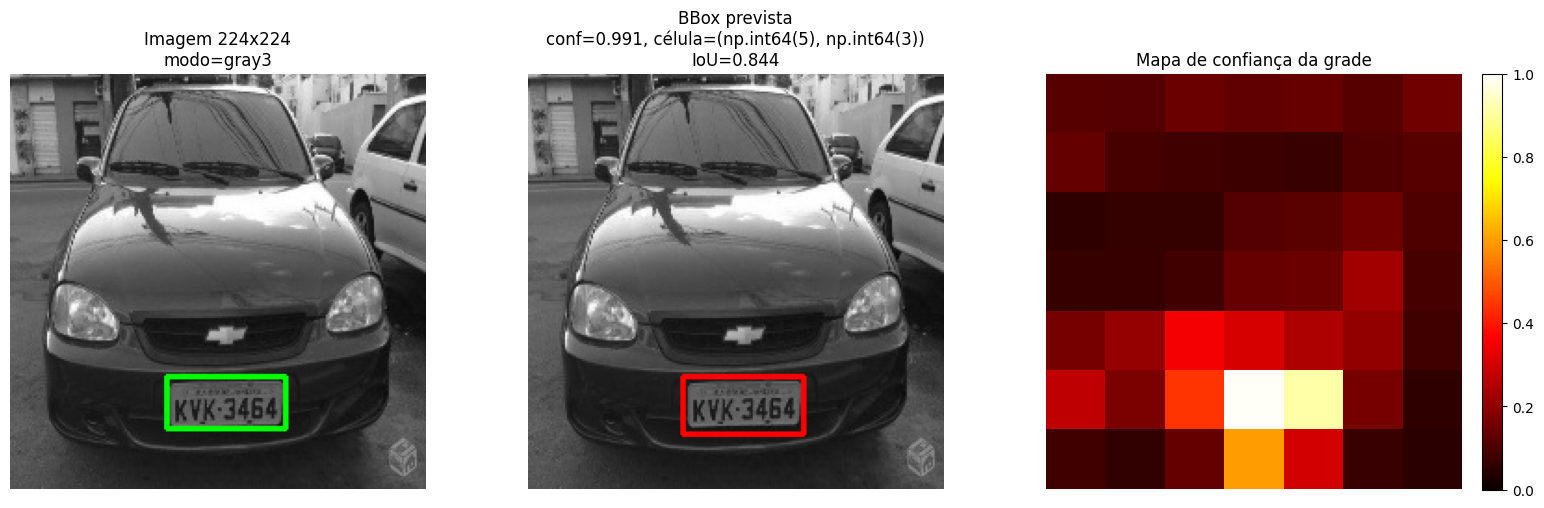

Modo: gray3
Confiança máxima: 0.9912563562393188
Célula escolhida: (np.int64(5), np.int64(3))
BBox prevista [cx, cy, w, h]: [0.5162126  0.79947555 0.2897393  0.14182426]


In [ ]:
### 11. TESTES VISUAIS — AMOSTRAS ALEATÓRIAS


N_TESTES_VISUAIS = 20

indices_teste = np.random.choice(
    len(X_val_mix),
    size=min(N_TESTES_VISUAIS, len(X_val_mix)),
    replace=False
)

for i, idx in enumerate(indices_teste):
    img_uint8 = ((X_val_mix[idx] + 1.0) * 127.5).clip(0, 255).astype(np.uint8)

    temp_path = f"/content/temp_grid_val_{idx}.jpg"
    cv2.imwrite(temp_path, cv2.cvtColor(img_uint8, cv2.COLOR_RGB2BGR))

    print("=" * 60)
    print(f"Teste visual {i + 1}/{len(indices_teste)} | índice = {idx}")

    testar_imagem_grid(
        modelo_grid,
        temp_path,
        bbox_real=y_val_mix[idx],
        modo_cor="gray3"
    )

## 12. Exportação do Modelo para TFLite

Após a seleção do melhor modelo, é realizada a conversão da rede para o formato TensorFlow Lite (TFLite), permitindo sua utilização em dispositivos com recursos computacionais limitados.

Além da versão em ponto flutuante (*Float32*), também podem ser geradas versões quantizadas, reduzindo o tamanho do modelo e o consumo de memória durante a inferência.

O modelo exportado mantém a mesma estrutura de saída utilizada durante o treinamento, produzindo um mapa espacial de detecção em formato:

```text
G × G × 5
```

onde cada célula da grade contém as informações de confiança e localização da placa.

Durante a inferência, a célula com maior confiança é selecionada para reconstrução da bounding box global da placa, permitindo que o detector opere de forma equivalente à versão utilizada no ambiente de treinamento.

A conversão para TFLite constitui a etapa final de preparação do modelo para implantação em sistemas embarcados, como a plataforma ESP32.


In [ ]:

### 12. EXPORTAR GRID DETECTOR PARA TFLITE / ESP32



def representative_dataset_grid():
    qtd = min(100, len(X_train_mix))
    for i in range(qtd):
        yield [X_train_mix[i:i+1].astype(np.float32)]


def salvar_tflite_grid(modelo, caminho_saida, quantizacao="float32"):
    converter = tf.lite.TFLiteConverter.from_keras_model(modelo)

    if quantizacao == "dynamic":
        converter.optimizations = [tf.lite.Optimize.DEFAULT]

    elif quantizacao == "int8":
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_dataset_grid
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = tf.int8

    modelo_tflite = converter.convert()

    with open(caminho_saida, "wb") as f:
        f.write(modelo_tflite)

    tamanho_kb = os.path.getsize(caminho_saida) / 1024
    print(f"Salvo: {caminho_saida} ({tamanho_kb:.1f} KB)")
    return caminho_saida, tamanho_kb


def gerar_header_tflite_grid(tflite_path, header_path, array_name="modelo_grid_tflite"):
    with open(tflite_path, "rb") as f:
        data = f.read()

    with open(header_path, "w") as f:
        f.write("#ifndef MODELO_GRID_PLACAS_H\n")
        f.write("#define MODELO_GRID_PLACAS_H\n\n")
        f.write("#include <cstdint>\n\n")
        f.write(f"alignas(8) const unsigned char {array_name}[] = {{\n")

        for i, byte in enumerate(data):
            if i % 12 == 0:
                f.write("  ")
            f.write(f"0x{byte:02x}")
            if i != len(data) - 1:
                f.write(", ")
            if i % 12 == 11:
                f.write("\n")

        f.write("\n};\n\n")
        f.write(f"const unsigned int {array_name}_len = {len(data)};\n\n")
        f.write("#endif\n")

    print("Header gerado:", header_path)
    print("Tamanho do array:", len(data), "bytes")


# Exporte o melhor modelo grid carregado
caminho_float32 = os.path.join(GRID_ESP32_DIR, f"grid_{IMG_SIZE}_float32.tflite")
caminho_dynamic = os.path.join(GRID_ESP32_DIR, f"grid_{IMG_SIZE}_dynamic.tflite")
caminho_int8 = os.path.join(GRID_ESP32_DIR, f"grid_{IMG_SIZE}_int8.tflite")

salvar_tflite_grid(modelo_grid, caminho_float32, quantizacao="float32")
salvar_tflite_grid(modelo_grid, caminho_dynamic, quantizacao="dynamic")
salvar_tflite_grid(modelo_grid, caminho_int8, quantizacao="int8")

header_path = os.path.join(GRID_ESP32_DIR, f"grid_{IMG_SIZE}_int8.h")
gerar_header_tflite_grid(caminho_int8, header_path, array_name=f"modelo_grid_{IMG_SIZE}_int8_tflite")


Saved artifact at '/tmp/tmpp5usqe00'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='entrada_imagem')
Output Type:
  TensorSpec(shape=(None, 7, 7, 5), dtype=tf.float32, name=None)
Captures:
  137782608872272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183998864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183998672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183998288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183999440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183997712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183999056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183999248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775183998480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775184000400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137775

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Salvo: /content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/grid_224_int8.tflite (2410.7 KB)
Header gerado: /content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/grid_224_int8.h
Tamanho do array: 2468584 bytes


## 13. Comparação entre Modelo Keras e Modelos TFLite

Nesta etapa é realizada a comparação entre o modelo final treinado em Keras e suas versões convertidas para TensorFlow Lite (TFLite).

O objetivo é verificar se a conversão do modelo mantém o desempenho de detecção, além de avaliar o impacto das otimizações no tamanho do arquivo e no tempo médio de inferência.

São comparadas diferentes versões do modelo, incluindo a versão original em Keras e as variantes TFLite geradas durante a exportação, como Float32, Dynamic Range e INT8.

Para cada modelo são calculadas métricas como IoU médio, Recall com IoU maior ou igual a 0,5, número de falhas de detecção, tempo médio de inferência e tamanho do arquivo convertido.

Essa análise é importante porque a versão TFLite, especialmente a quantizada em INT8, é a mais adequada para implantação em sistemas embarcados, como a ESP32, devido ao menor consumo de memória e menor tamanho do modelo.


In [ ]:
# COMPARAÇÃO: MODELO KERAS x MODELOS TFLITE
# Avalia IoU médio, Recall@IoU>=0.5 e tempo de inferência


import os
import glob
import time
import numpy as np
import pandas as pd
import tensorflow as tf

# ------------------------------------------------------------
# 1. Localizar modelos TFLite
# ------------------------------------------------------------

# Usa a pasta já definida no notebook, caso exista
try:
    pasta_tflite = GRID_ESP32_DIR
except NameError:
    pasta_tflite = os.path.join(
        PROJECT_PATH,
        f"esp32_grid_{IMG_SIZE}_alpha_{alpha_token()}"
    )

caminhos_tflite = sorted(
    glob.glob(os.path.join(pasta_tflite, "**", "*.tflite"), recursive=True)
)

print("Pasta TFLite:")
print(pasta_tflite)
print("\nModelos TFLite encontrados:")
for p in caminhos_tflite:
    print("-", os.path.basename(p), f"({os.path.getsize(p)/1024/1024:.2f} MB)")


# ------------------------------------------------------------
# 2. Funções auxiliares para inferência TFLite
# ------------------------------------------------------------

def nome_variante_tflite(caminho):
    nome = os.path.basename(caminho).lower()

    if "int8" in nome:
        return "TFLite INT8"
    elif "dynamic" in nome or "dyn" in nome:
        return "TFLite Dynamic"
    elif "float16" in nome or "fp16" in nome:
        return "TFLite Float16"
    elif "float32" in nome or "fp32" in nome:
        return "TFLite Float32"
    else:
        return "TFLite"


def preparar_entrada_tflite(x, input_detail):
    """
    Prepara uma imagem normalizada [-1, 1] para o tipo esperado pelo TFLite.
    """
    dtype = input_detail["dtype"]
    escala, zero_point = input_detail["quantization"]

    x = x.astype(np.float32)

    if dtype == np.float32:
        return x.astype(np.float32)

    if dtype in [np.int8, np.uint8]:
        if escala == 0:
            raise ValueError("Escala de quantização da entrada é zero.")

        x_q = np.round(x / escala + zero_point)

        if dtype == np.int8:
            x_q = np.clip(x_q, -128, 127)
        else:
            x_q = np.clip(x_q, 0, 255)

        return x_q.astype(dtype)

    return x.astype(dtype)


def recuperar_saida_tflite(y, output_detail):
    """
    Converte a saída quantizada do TFLite para float, quando necessário.
    """
    dtype = output_detail["dtype"]
    escala, zero_point = output_detail["quantization"]

    if dtype in [np.int8, np.uint8]:
        if escala == 0:
            return y.astype(np.float32)
        return (y.astype(np.float32) - zero_point) * escala

    return y.astype(np.float32)


def predizer_tflite_grid(interpreter, input_details, output_details, x):
    """
    Executa inferência em uma imagem usando TFLite.
    x deve vir com shape (1, IMG_SIZE, IMG_SIZE, 3), normalizada em [-1, 1].
    """
    entrada = preparar_entrada_tflite(x, input_details[0])

    interpreter.set_tensor(input_details[0]["index"], entrada)
    interpreter.invoke()

    saida = interpreter.get_tensor(output_details[0]["index"])
    saida = recuperar_saida_tflite(saida, output_details[0])

    return saida[0]


# ------------------------------------------------------------
# 3. Avaliação do modelo Keras
# ------------------------------------------------------------

def avaliar_keras_grid(
    modelo,
    X_val,
    y_val,
    nome_modelo="Keras",
    limiar_conf=0.0,
    limiar_iou=0.5
):
    ious = []
    acertos = 0
    sem_detec = 0
    tempos = []

    for i in range(len(X_val)):
        x = X_val[i:i+1]

        t0 = time.time()
        pred_grid = modelo.predict(x, verbose=0)[0]
        tempos.append(time.time() - t0)

        pred_bbox, conf, celula = grade_para_bbox_global(
            pred_grid,
            limiar_conf=limiar_conf
        )

        if pred_bbox is None:
            ious.append(0.0)
            sem_detec += 1
            continue

        iou = calcular_iou_yolo(y_val[i], pred_bbox)
        ious.append(iou)

        if iou >= limiar_iou:
            acertos += 1

    total = len(X_val)

    return {
        "modelo": nome_modelo,
        "n": total,
        "iou_medio": float(np.mean(ious)),
        "iou_desvio": float(np.std(ious)),
        "recall_iou_05": float(acertos / total),
        "sem_deteccao": sem_detec,
        "tempo_medio_ms": float(np.mean(tempos) * 1000),
        "tamanho_mb": None,
        "caminho": "modelo em memória"
    }


# ------------------------------------------------------------
# 4. Avaliação do modelo TFLite
# ------------------------------------------------------------

def avaliar_tflite_grid(
    caminho_tflite,
    X_val,
    y_val,
    nome_modelo=None,
    limiar_conf=0.0,
    limiar_iou=0.5
):
    if nome_modelo is None:
        nome_modelo = nome_variante_tflite(caminho_tflite)

    interpreter = tf.lite.Interpreter(model_path=caminho_tflite)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    ious = []
    acertos = 0
    sem_detec = 0
    tempos = []

    for i in range(len(X_val)):
        x = X_val[i:i+1].astype(np.float32)

        t0 = time.time()
        pred_grid = predizer_tflite_grid(
            interpreter,
            input_details,
            output_details,
            x
        )
        tempos.append(time.time() - t0)

        pred_bbox, conf, celula = grade_para_bbox_global(
            pred_grid,
            limiar_conf=limiar_conf
        )

        if pred_bbox is None:
            ious.append(0.0)
            sem_detec += 1
            continue

        iou = calcular_iou_yolo(y_val[i], pred_bbox)
        ious.append(iou)

        if iou >= limiar_iou:
            acertos += 1

    total = len(X_val)

    return {
        "modelo": nome_modelo,
        "n": total,
        "iou_medio": float(np.mean(ious)),
        "iou_desvio": float(np.std(ious)),
        "recall_iou_05": float(acertos / total),
        "sem_deteccao": sem_detec,
        "tempo_medio_ms": float(np.mean(tempos) * 1000),
        "tamanho_mb": float(os.path.getsize(caminho_tflite) / 1024 / 1024),
        "caminho": caminho_tflite
    }


# ------------------------------------------------------------
# 5. Rodar comparação
# ------------------------------------------------------------

conjuntos_avaliacao = {
    "Base 1": (X_val_b1, y_val_b1),
    "Base 2": (X_val_b2, y_val_b2),
    "Mix":    (X_val_mix, y_val_mix),
}

resultados = []

for nome_conjunto, (Xv, yv) in conjuntos_avaliacao.items():
    print("=" * 70)
    print(f"Avaliando conjunto: {nome_conjunto}")

    # Modelo Keras final
    met_keras = avaliar_keras_grid(
        modelo_grid,
        Xv,
        yv,
        nome_modelo="Keras final",
        limiar_conf=0.0
    )
    met_keras["conjunto"] = nome_conjunto
    resultados.append(met_keras)

    # Modelos TFLite
    for caminho in caminhos_tflite:
        met_tflite = avaliar_tflite_grid(
            caminho,
            Xv,
            yv,
            nome_modelo=nome_variante_tflite(caminho),
            limiar_conf=0.0
        )
        met_tflite["conjunto"] = nome_conjunto
        resultados.append(met_tflite)

df_comparacao_tflite = pd.DataFrame(resultados)

# Reorganizar colunas
colunas = [
    "conjunto",
    "modelo",
    "n",
    "iou_medio",
    "iou_desvio",
    "recall_iou_05",
    "sem_deteccao",
    "tempo_medio_ms",
    "tamanho_mb",
    "caminho"
]

df_comparacao_tflite = df_comparacao_tflite[colunas]

display(df_comparacao_tflite)


# ------------------------------------------------------------
# 6. Salvar CSV com a comparação
# ------------------------------------------------------------

try:
    caminho_csv_comparacao = os.path.join(
        GRID_RESULTS_DIR,
        f"comparacao_keras_tflite_{IMG_SIZE}_alpha_{alpha_token()}.csv"
    )
except NameError:
    caminho_csv_comparacao = os.path.join(
        PROJECT_PATH,
        f"comparacao_keras_tflite_{IMG_SIZE}_alpha_{alpha_token()}.csv"
    )

df_comparacao_tflite.to_csv(caminho_csv_comparacao, index=False)

print("\nComparação salva em:")
print(caminho_csv_comparacao)

Pasta TFLite:
/content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5

Modelos TFLite encontrados:
- grid_224_dynamic.tflite (2.29 MB)
- grid_224_float32.tflite (8.75 MB)
- grid_224_int8.tflite (2.35 MB)
Avaliando conjunto: Base 1


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Avaliando conjunto: Base 2
Avaliando conjunto: Mix


,conjunto,modelo,n,iou_medio,iou_desvio,recall_iou_05,sem_deteccao,tempo_medio_ms,tamanho_mb,caminho
0,Base 1,Keras final,60,0.766513,0.114743,0.983333,0,100.620659,NaN,modelo em memória
1,Base 1,TFLite Dynamic,60,0.767230,0.117298,0.983333,0,6.936757,2.293594,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...
2,Base 1,TFLite Float32,60,0.766513,0.114743,0.983333,0,6.366626,8.750900,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...
3,Base 1,TFLite INT8,60,0.762928,0.116389,0.966667,0,6.706707,2.354225,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...
4,Base 2,Keras final,12,0.584684,0.242561,0.750000,0,82.022349,NaN,modelo em memória
5,Base 2,TFLite Dynamic,12,0.579125,0.250201,0.750000,0,6.943683,2.293594,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...
6,Base 2,TFLite Float32,12,0.584685,0.242561,0.750000,0,6.905297,8.750900,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...
7,Base 2,TFLite INT8,12,0.577799,0.243461,0.666667,0,7.294854,2.354225,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...
8,Mix,Keras final,72,0.736208,0.159278,0.944444,0,96.900258,NaN,modelo em memória
9,Mix,TFLite Dynamic,72,0.735879,0.163748,0.944444,0,7.060667,2.293594,/content/drive/MyDrive/PDI_Embarcados/esp32_gr...



Comparação salva em:
/content/drive/MyDrive/PDI_Embarcados/resultados_grid_224_alpha_0p5/comparacao_keras_tflite_224_alpha_0p5.csv


In [ ]:
# ============================================================
# 14. CARREGAR IMAGENS NEGATIVAS — SEM PLACA
# ============================================================

import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Pasta no Drive onde você deve colocar imagens SEM placa
NEGATIVE_DIR = os.path.join(PROJECT_PATH, "negativas_sem_placa")

os.makedirs(NEGATIVE_DIR, exist_ok=True)

print("Pasta de imagens negativas:")
print(NEGATIVE_DIR)

def carregar_imagens_negativas(
    pasta,
    img_size=IMG_SIZE,
    modo_cor="gray3",
    limite=None
):
    """
    Carrega imagens negativas, isto é, imagens sem placa.

    As imagens são redimensionadas para IMG_SIZE x IMG_SIZE
    e normalizadas para [-1, 1], igual ao treinamento.
    """

    extensoes = ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"]

    caminhos = []
    for ext in extensoes:
        caminhos.extend(glob.glob(os.path.join(pasta, ext)))

    caminhos = sorted(caminhos)

    if limite is not None:
        caminhos = caminhos[:limite]

    imagens = []
    caminhos_validos = []

    for caminho in caminhos:
        img_bgr = cv2.imread(caminho)

        if img_bgr is None:
            print("Imagem ignorada:", caminho)
            continue

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        if modo_cor == "gray3":
            img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
            img_rgb = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)

        elif modo_cor == "rgb":
            pass

        else:
            raise ValueError("modo_cor deve ser 'rgb' ou 'gray3'.")

        img_rgb = cv2.resize(img_rgb, (img_size, img_size))
        img_norm = (img_rgb.astype(np.float32) / 127.5) - 1.0

        imagens.append(img_norm)
        caminhos_validos.append(caminho)

    X_neg = np.array(imagens, dtype=np.float32)

    print("Imagens negativas carregadas:", len(X_neg))
    print("Shape:", X_neg.shape)

    return X_neg, caminhos_validos


# Recomendo gray3 porque foi o modo mais compatível com o embarcado
X_neg_all, caminhos_neg_all = carregar_imagens_negativas(
    NEGATIVE_DIR,
    img_size=IMG_SIZE,
    modo_cor="gray3"
)

assert len(X_neg_all) > 0, "Nenhuma imagem negativa encontrada. Coloque imagens em NEGATIVE_DIR."

X_neg_train_all, X_neg_val, caminhos_neg_train, caminhos_neg_val = train_test_split(
    X_neg_all,
    caminhos_neg_all,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("Negativas treino:", X_neg_train_all.shape)
print("Negativas validação:", X_neg_val.shape)

Pasta de imagens negativas:
/content/drive/MyDrive/PDI_Embarcados/negativas_sem_placa
Imagens negativas carregadas: 16
Shape: (16, 224, 224, 3)
Negativas treino: (12, 224, 224, 3)
Negativas validação: (4, 224, 224, 3)


In [ ]:
# ============================================================
# 15. DATASET POSITIVO + NEGATIVO EM FORMATO DE GRADE
# ============================================================

GRID_REAL = modelo_grid.output_shape[1]

print("Grid real do modelo:", GRID_REAL)

# ------------------------------------------------------------
# 1. Converter labels positivos para grade
# ------------------------------------------------------------

Y_train_pos_grade = converter_yolo_para_grade(
    y_train_mix,
    GRID_REAL
)

Y_val_pos_grade = converter_yolo_para_grade(
    y_val_mix,
    GRID_REAL
)

print("Positivos treino:", X_train_mix.shape, Y_train_pos_grade.shape)
print("Positivos validação:", X_val_mix.shape, Y_val_pos_grade.shape)

# ------------------------------------------------------------
# 2. Selecionar quantidade de negativas
# ------------------------------------------------------------

# Comece com 25%. Depois pode testar 0.15, 0.20, 0.30.
NEG_RATIO = 0.25

n_neg_train = min(
    len(X_neg_train_all),
    int(len(X_train_mix) * NEG_RATIO)
)

rng = np.random.default_rng(42)

idx_neg = rng.choice(
    len(X_neg_train_all),
    size=n_neg_train,
    replace=False
)

X_neg_train = X_neg_train_all[idx_neg]

print("Negativas usadas no treino:", X_neg_train.shape)

# ------------------------------------------------------------
# 3. Criar labels negativos: grade toda zerada
# ------------------------------------------------------------

Y_neg_train_grade = np.zeros(
    (len(X_neg_train), GRID_REAL, GRID_REAL, 5),
    dtype=np.float32
)

Y_neg_val_grade = np.zeros(
    (len(X_neg_val), GRID_REAL, GRID_REAL, 5),
    dtype=np.float32
)

# ------------------------------------------------------------
# 4. Combinar positivos e negativos
# ------------------------------------------------------------

X_train_com_neg = np.concatenate(
    [X_train_mix, X_neg_train],
    axis=0
)

Y_train_com_neg = np.concatenate(
    [Y_train_pos_grade, Y_neg_train_grade],
    axis=0
)

X_val_com_neg = np.concatenate(
    [X_val_mix, X_neg_val],
    axis=0
)

Y_val_com_neg = np.concatenate(
    [Y_val_pos_grade, Y_neg_val_grade],
    axis=0
)

# ------------------------------------------------------------
# 5. Embaralhar treino
# ------------------------------------------------------------

indices = rng.permutation(len(X_train_com_neg))

X_train_com_neg = X_train_com_neg[indices]
Y_train_com_neg = Y_train_com_neg[indices]

print("\nDataset final de treino:")
print("X_train_com_neg:", X_train_com_neg.shape)
print("Y_train_com_neg:", Y_train_com_neg.shape)

print("\nDataset final de validação:")
print("X_val_com_neg:", X_val_com_neg.shape)
print("Y_val_com_neg:", Y_val_com_neg.shape)

print("\nProporção de negativas no treino:")
print(f"{len(X_neg_train) / len(X_train_com_neg):.2%}")

print("\nProporção de negativas na validação:")
print(f"{len(X_neg_val) / len(X_val_com_neg):.2%}")

NameError: name 'modelo_grid' is not defined

Camadas treináveis no fine-tuning:
 - grid_head_conv1
 - grid_head_bn1
 - grid_head_drop1
 - grid_head_conv2
 - grid_head_bn2
 - grid_output
Epoch 1/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 32s 121ms/step - loss: 0.8903 - val_loss: 1.1945 - learning_rate: 1.0000e-05
Epoch 2/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.8450 - val_loss: 1.1993 - learning_rate: 1.0000e-05
Epoch 3/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.8246 - val_loss: 1.1931 - learning_rate: 1.0000e-05
Epoch 4/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.7948 - val_loss: 1.1948 - learning_rate: 1.0000e-05
Epoch 5/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.7562 - val_loss: 1.2010 - learning_rate: 1.0000e-05
Epoch 6/20
122/123 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.7714
Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.7633 - val_loss: 1.2006 - learning_rate: 1.0000e-05
Epoch 7/20
123/123 ━━━━━━━━━━━━━━━━

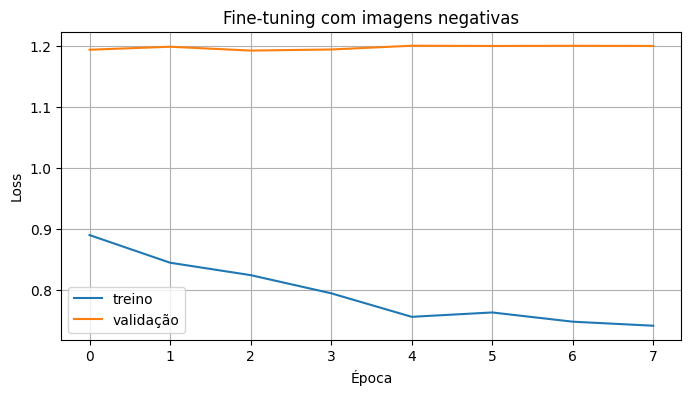

In [ ]:
# ============================================================
# 16. FINE-TUNING COM IMAGENS NEGATIVAS
# ============================================================

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ------------------------------------------------------------
# 1. Criar uma cópia do modelo atual
# ------------------------------------------------------------

modelo_grid_neg = tf.keras.models.clone_model(modelo_grid)
modelo_grid_neg.set_weights(modelo_grid.get_weights())

# ------------------------------------------------------------
# 2. Congelar backbone e treinar apenas o head detector
# ------------------------------------------------------------

for layer in modelo_grid_neg.layers:
    if (
        "grid_head" in layer.name or
        "grid_output" in layer.name or
        "head" in layer.name
    ):
        layer.trainable = True
    else:
        layer.trainable = False

print("Camadas treináveis no fine-tuning:")

for layer in modelo_grid_neg.layers:
    if layer.trainable:
        print(" -", layer.name)

# ------------------------------------------------------------
# 3. Compilar com learning rate baixo
# ------------------------------------------------------------

modelo_grid_neg.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=grid_detector_loss
)

callbacks_neg = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# ------------------------------------------------------------
# 4. Treinar
# ------------------------------------------------------------

history_neg = modelo_grid_neg.fit(
    X_train_com_neg,
    Y_train_com_neg,
    validation_data=(X_val_com_neg, Y_val_com_neg),
    epochs=20,
    batch_size=8,
    callbacks=callbacks_neg,
    verbose=1
)

# ------------------------------------------------------------
# 5. Curva de loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))
plt.plot(history_neg.history["loss"], label="treino")
plt.plot(history_neg.history["val_loss"], label="validação")
plt.title("Fine-tuning com imagens negativas")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# 17. AVALIAR FALSOS POSITIVOS EM IMAGENS NEGATIVAS
# ============================================================

def obter_confs_negativas_grid(modelo, X_neg):
    """
    Para cada imagem negativa, calcula a maior confiança da grade.
    """
    confs_max = []
    celulas = []
    conf_maps = []

    for i in range(len(X_neg)):
        pred_grid = modelo.predict(X_neg[i:i+1], verbose=0)[0]

        conf_map = pred_grid[..., 0]
        row, col = np.unravel_index(
            np.argmax(conf_map),
            conf_map.shape
        )

        confs_max.append(float(conf_map[row, col]))
        celulas.append((row, col))
        conf_maps.append(conf_map)

    return np.array(confs_max), celulas, conf_maps


def avaliar_negativos_grid(
    modelo,
    X_neg,
    nome_modelo="modelo",
    limiares=(0.50, 0.90, 0.95, 0.98)
):
    """
    Avalia falso positivo em imagens sem placa.
    Como não existe bbox real, a métrica principal é:
    quantas imagens negativas passaram do limiar de confiança.
    """

    confs_max, celulas, _ = obter_confs_negativas_grid(modelo, X_neg)

    resultados = []

    for limiar in limiares:
        falsos_positivos = int(np.sum(confs_max >= limiar))
        taxa_fp = falsos_positivos / len(confs_max)

        resultados.append({
            "modelo": nome_modelo,
            "limiar": limiar,
            "n_negativas": len(confs_max),
            "falsos_positivos": falsos_positivos,
            "taxa_falso_positivo": float(taxa_fp),
            "conf_media": float(np.mean(confs_max)),
            "conf_mediana": float(np.median(confs_max)),
            "conf_max": float(np.max(confs_max)),
            "conf_min": float(np.min(confs_max))
        })

    return pd.DataFrame(resultados)


df_neg_antes = avaliar_negativos_grid(
    modelo_grid,
    X_neg_val,
    nome_modelo="Antes do fine-tuning"
)

df_neg_depois = avaliar_negativos_grid(
    modelo_grid_neg,
    X_neg_val,
    nome_modelo="Depois do fine-tuning"
)

df_neg_comparacao = pd.concat(
    [df_neg_antes, df_neg_depois],
    ignore_index=True
)

display(df_neg_comparacao)

# Salvar resultado
CAMINHO_NEG_CSV = os.path.join(
    GRID_RESULTS_DIR,
    f"comparacao_falsos_positivos_negativas_{IMG_SIZE}_alpha_{alpha_token()}.csv"
)

df_neg_comparacao.to_csv(CAMINHO_NEG_CSV, index=False)

print("Resultado salvo em:")
print(CAMINHO_NEG_CSV)

,modelo,limiar,n_negativas,falsos_positivos,taxa_falso_positivo,conf_media,conf_mediana,conf_max,conf_min
0,Antes do fine-tuning,0.50,4,4,1.00,0.769135,0.790086,0.903268,0.593101
1,Antes do fine-tuning,0.90,4,1,0.25,0.769135,0.790086,0.903268,0.593101
2,Antes do fine-tuning,0.95,4,0,0.00,0.769135,0.790086,0.903268,0.593101
3,Antes do fine-tuning,0.98,4,0,0.00,0.769135,0.790086,0.903268,0.593101
4,Depois do fine-tuning,0.50,4,4,1.00,0.838637,0.830267,0.902122,0.791893
5,Depois do fine-tuning,0.90,4,1,0.25,0.838637,0.830267,0.902122,0.791893
6,Depois do fine-tuning,0.95,4,0,0.00,0.838637,0.830267,0.902122,0.791893
7,Depois do fine-tuning,0.98,4,0,0.00,0.838637,0.830267,0.902122,0.791893


Resultado salvo em:
/content/drive/MyDrive/PDI_Embarcados/resultados_grid_224_alpha_0p5/comparacao_falsos_positivos_negativas_224_alpha_0p5.csv


In [ ]:
# ============================================================
# 18. AVALIAR MODELO ORIGINAL x MODELO COM NEGATIVAS
# EM IMAGENS COM PLACA
# ============================================================

print("=" * 70)
print("MODELO ORIGINAL — Base Mix")
print("=" * 70)

metricas_original_mix = avaliar_modelo_grid(
    modelo_grid,
    X_val_mix,
    y_val_mix,
    nome_modelo="original_mix",
    limiar_conf=0.0
)

print("=" * 70)
print("MODELO COM NEGATIVAS — Base Mix")
print("=" * 70)

metricas_neg_mix = avaliar_modelo_grid(
    modelo_grid_neg,
    X_val_mix,
    y_val_mix,
    nome_modelo="com_negativas_mix",
    limiar_conf=0.0
)

print("=" * 70)
print("MODELO ORIGINAL — Base 1")
print("=" * 70)

metricas_original_b1 = avaliar_modelo_grid(
    modelo_grid,
    X_val_b1,
    y_val_b1,
    nome_modelo="original_base1",
    limiar_conf=0.0
)

print("=" * 70)
print("MODELO COM NEGATIVAS — Base 1")
print("=" * 70)

metricas_neg_b1 = avaliar_modelo_grid(
    modelo_grid_neg,
    X_val_b1,
    y_val_b1,
    nome_modelo="com_negativas_base1",
    limiar_conf=0.0
)

print("=" * 70)
print("MODELO ORIGINAL — Base 2")
print("=" * 70)

metricas_original_b2 = avaliar_modelo_grid(
    modelo_grid,
    X_val_b2,
    y_val_b2,
    nome_modelo="original_base2",
    limiar_conf=0.0
)

print("=" * 70)
print("MODELO COM NEGATIVAS — Base 2")
print("=" * 70)

metricas_neg_b2 = avaliar_modelo_grid(
    modelo_grid_neg,
    X_val_b2,
    y_val_b2,
    nome_modelo="com_negativas_base2",
    limiar_conf=0.0
)

df_comp_positivos = pd.DataFrame([
    metricas_original_b1,
    metricas_neg_b1,
    metricas_original_b2,
    metricas_neg_b2,
    metricas_original_mix,
    metricas_neg_mix,
])

display(df_comp_positivos)

CAMINHO_COMP_POS_CSV = os.path.join(
    GRID_RESULTS_DIR,
    f"comparacao_positivos_original_vs_negativas_{IMG_SIZE}_alpha_{alpha_token()}.csv"
)

df_comp_positivos.to_csv(CAMINHO_COMP_POS_CSV, index=False)

print("Comparação salva em:")
print(CAMINHO_COMP_POS_CSV)

MODELO ORIGINAL — Base Mix
MODELO COM NEGATIVAS — Base Mix
MODELO ORIGINAL — Base 1
MODELO COM NEGATIVAS — Base 1
MODELO ORIGINAL — Base 2
MODELO COM NEGATIVAS — Base 2


,modelo,n_validacao,iou_medio,iou_desvio,acuracia_iou_05,recall_05,f1_05,sem_deteccao,conf_media,tempo_inferencia_ms
0,original_base1,60,0.766513,0.114743,0.983333,0.983333,0.983333,0,0.993057,90.631839
1,com_negativas_base1,60,0.771674,0.116896,0.983333,0.983333,0.983333,0,0.994852,83.835200
2,original_base2,12,0.584685,0.242562,0.750000,0.750000,0.750000,0,0.991594,82.066258
3,com_negativas_base2,12,0.577323,0.251996,0.750000,0.750000,0.750000,0,0.993040,79.134266
4,original_mix,72,0.736209,0.159278,0.944444,0.944444,0.944444,0,0.992813,70.668694
5,com_negativas_mix,72,0.739282,0.164976,0.944444,0.944444,0.944444,0,0.994550,74.825688


Comparação salva em:
/content/drive/MyDrive/PDI_Embarcados/resultados_grid_224_alpha_0p5/comparacao_positivos_original_vs_negativas_224_alpha_0p5.csv


Piores negativos — modelo original:


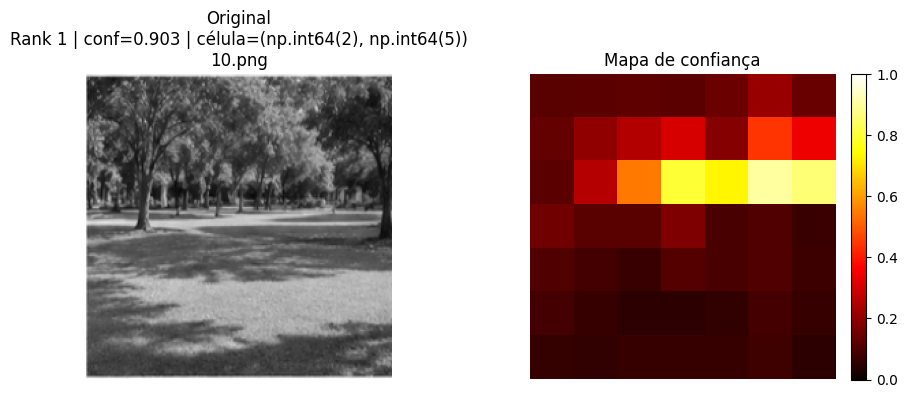

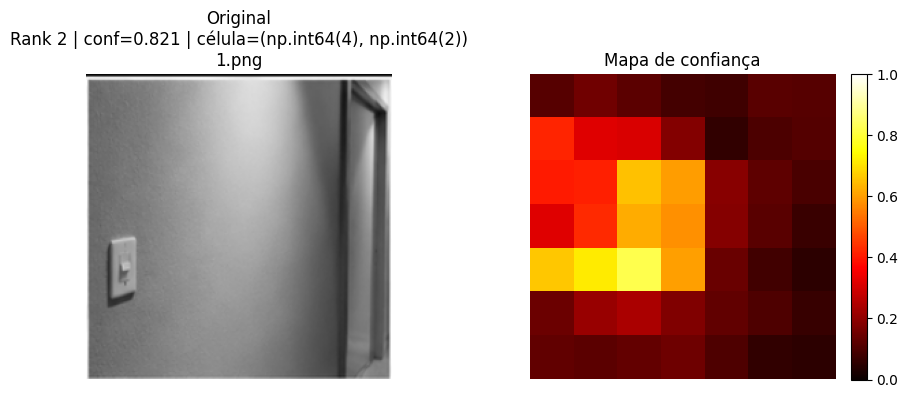

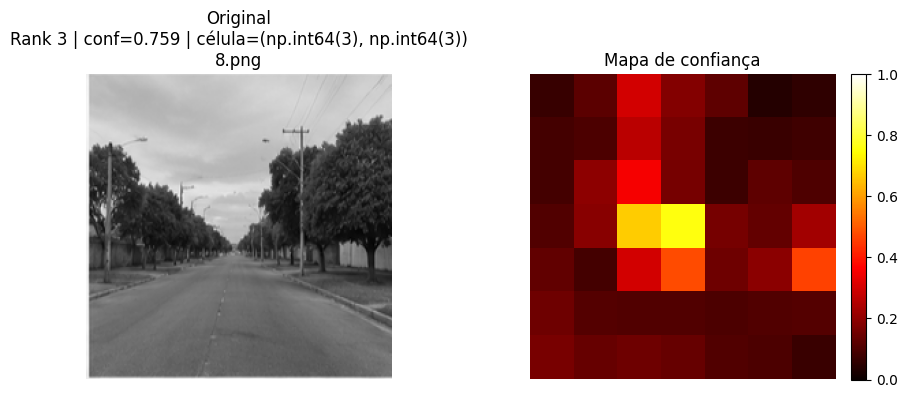

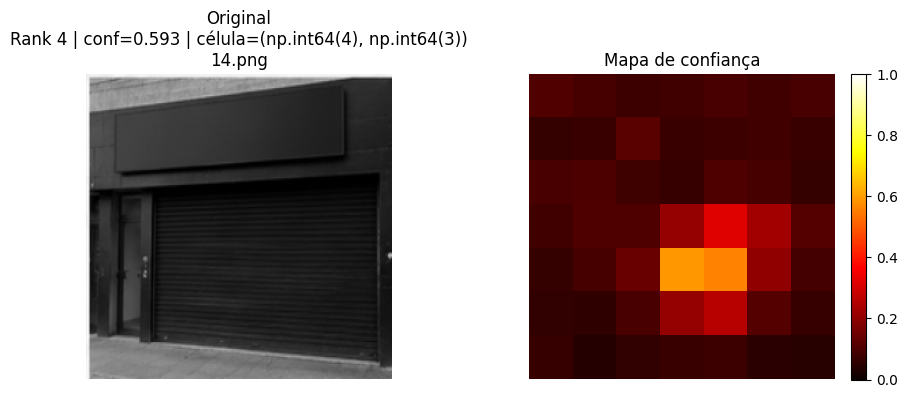

Piores negativos — modelo com negativas:


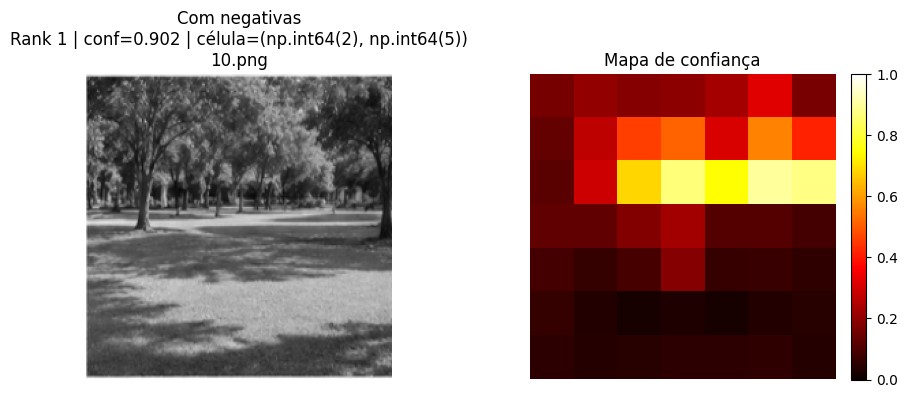

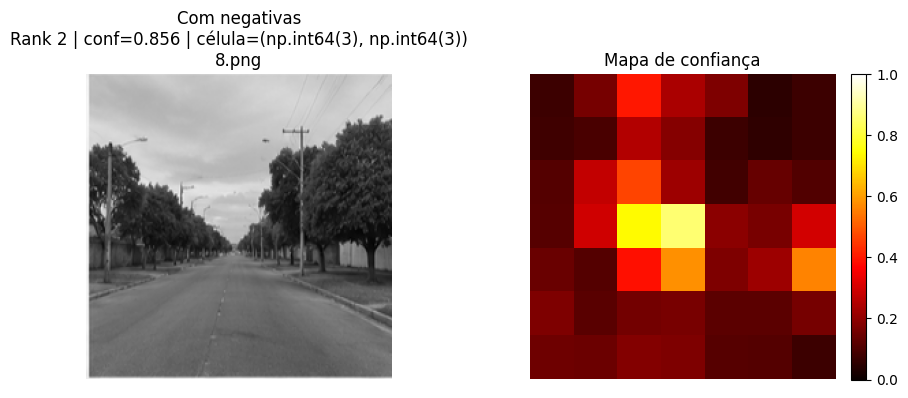

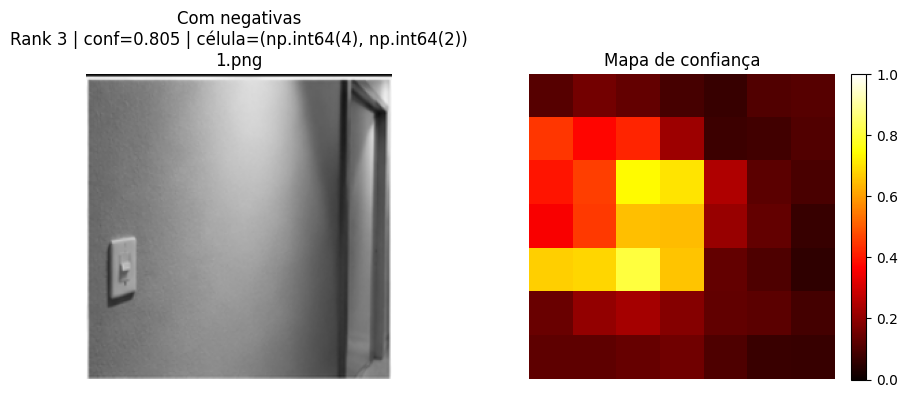

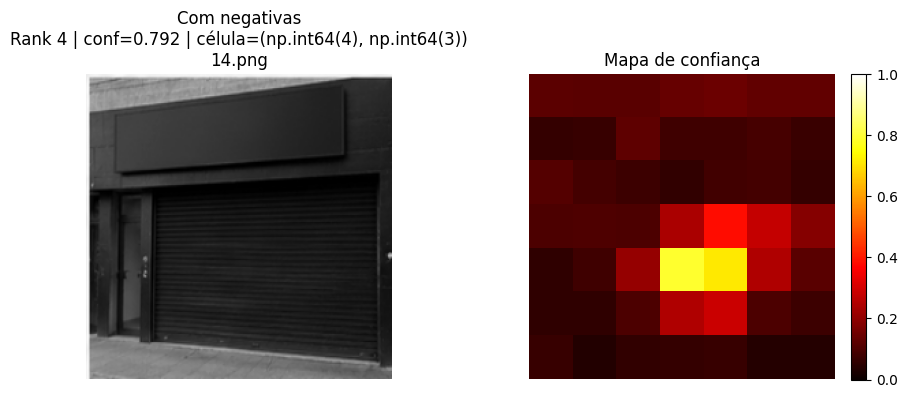

In [ ]:
# ============================================================
# 19. VISUALIZAR PIORES FALSOS POSITIVOS
# ============================================================

def visualizar_piores_negativos(
    modelo,
    X_neg,
    caminhos_neg=None,
    nome_modelo="modelo",
    top_k=8
):
    """
    Mostra as imagens negativas com maior confiança.
    """

    confs_max, celulas, conf_maps = obter_confs_negativas_grid(
        modelo,
        X_neg
    )

    indices = np.argsort(confs_max)[::-1][:top_k]

    for rank, idx in enumerate(indices, start=1):
        img = ((X_neg[idx] + 1.0) * 127.5).clip(0, 255).astype(np.uint8)

        conf = confs_max[idx]
        celula = celulas[idx]
        conf_map = conf_maps[idx]

        plt.figure(figsize=(9, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(img)
        titulo = f"{nome_modelo}\nRank {rank} | conf={conf:.3f} | célula={celula}"
        if caminhos_neg is not None:
            titulo += "\n" + os.path.basename(caminhos_neg[idx])
        plt.title(titulo)
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(conf_map, cmap="hot", vmin=0, vmax=1)
        plt.title("Mapa de confiança")
        plt.axis("off")
        plt.colorbar(fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()


print("Piores negativos — modelo original:")
visualizar_piores_negativos(
    modelo_grid,
    X_neg_val,
    caminhos_neg=caminhos_neg_val,
    nome_modelo="Original",
    top_k=8
)

print("Piores negativos — modelo com negativas:")
visualizar_piores_negativos(
    modelo_grid_neg,
    X_neg_val,
    caminhos_neg=caminhos_neg_val,
    nome_modelo="Com negativas",
    top_k=8
)

In [ ]:
# ============================================================
# 20. SALVAR MODELO AJUSTADO COM NEGATIVAS
# ============================================================

CAMINHO_MODELO_COM_NEGATIVAS = os.path.join(
    PROJECT_PATH,
    f"modelo_final_grid_{IMG_SIZE}_alpha_{alpha_token()}_com_negativas.keras"
)

modelo_grid_neg.save(CAMINHO_MODELO_COM_NEGATIVAS)

print("Modelo com negativas salvo em:")
print(CAMINHO_MODELO_COM_NEGATIVAS)

Modelo com negativas salvo em:
/content/drive/MyDrive/PDI_Embarcados/modelo_final_grid_224_alpha_0p5_com_negativas.keras


In [ ]:
# ============================================================
# FUNÇÕES PARA EXPORTAR O MODELO GRID PARA TFLITE
# ============================================================

GRID_ESP32_DIR = os.path.join(
    PROJECT_PATH,
    f"esp32_grid_{IMG_SIZE}_alpha_{alpha_token()}"
)
os.makedirs(GRID_ESP32_DIR, exist_ok=True)


def representative_dataset_grid(X_ref, n_amostras=100):
    """
    Gera amostras representativas para quantização INT8.
    """
    n = min(n_amostras, len(X_ref))
    indices = np.linspace(0, len(X_ref) - 1, n, dtype=int)

    for idx in indices:
        x = X_ref[idx:idx+1].astype(np.float32)
        yield [x]


def salvar_tflite_bytes(converter, caminho_saida):
    """
    Converte e salva modelo TFLite.
    """
    tflite_model = converter.convert()

    with open(caminho_saida, "wb") as f:
        f.write(tflite_model)

    tamanho_bytes = os.path.getsize(caminho_saida)
    tamanho_mb = tamanho_bytes / (1024 * 1024)

    print(f"Modelo salvo em: {caminho_saida}")
    print(f"Tamanho: {tamanho_mb:.4f} MB")

    return tamanho_bytes, tamanho_mb


def salvar_grid_tflite(modelo_grid, X_ref):
    """
    Exporta o detector por grade para 3 versões TFLite:
    - float32
    - dynamic range
    - int8

    Retorna um DataFrame resumo.
    """
    resumo = []

    # --------------------------------------------------------
    # 1. FLOAT32
    # --------------------------------------------------------
    caminho_float32 = os.path.join(
        GRID_ESP32_DIR,
        f"modelo_grid_{IMG_SIZE}_alpha_{alpha_token()}_float32.tflite"
    )

    converter = tf.lite.TFLiteConverter.from_keras_model(modelo_grid)
    tamanho_bytes, tamanho_mb = salvar_tflite_bytes(converter, caminho_float32)

    resumo.append({
        "modelo": "TFLite Float32",
        "caminho": caminho_float32,
        "tamanho_bytes": tamanho_bytes,
        "tamanho_mb": tamanho_mb
    })

    # --------------------------------------------------------
    # 2. DYNAMIC RANGE
    # --------------------------------------------------------
    caminho_dynamic = os.path.join(
        GRID_ESP32_DIR,
        f"modelo_grid_{IMG_SIZE}_alpha_{alpha_token()}_dynamic.tflite"
    )

    converter = tf.lite.TFLiteConverter.from_keras_model(modelo_grid)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]

    tamanho_bytes, tamanho_mb = salvar_tflite_bytes(converter, caminho_dynamic)

    resumo.append({
        "modelo": "TFLite Dynamic",
        "caminho": caminho_dynamic,
        "tamanho_bytes": tamanho_bytes,
        "tamanho_mb": tamanho_mb
    })

    # --------------------------------------------------------
    # 3. INT8
    # --------------------------------------------------------
    caminho_int8 = os.path.join(
        GRID_ESP32_DIR,
        f"modelo_grid_{IMG_SIZE}_alpha_{alpha_token()}_int8.tflite"
    )

    converter = tf.lite.TFLiteConverter.from_keras_model(modelo_grid)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = lambda: representative_dataset_grid(X_ref)

    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    try:
        tamanho_bytes, tamanho_mb = salvar_tflite_bytes(converter, caminho_int8)
    except Exception as e:
        print("Falha na conversão INT8 completa.")
        print("Erro:", e)
        print("Tentando salvar INT8 parcial...")

        converter = tf.lite.TFLiteConverter.from_keras_model(modelo_grid)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = lambda: representative_dataset_grid(X_ref)

        tamanho_bytes, tamanho_mb = salvar_tflite_bytes(converter, caminho_int8)

    resumo.append({
        "modelo": "TFLite INT8",
        "caminho": caminho_int8,
        "tamanho_bytes": tamanho_bytes,
        "tamanho_mb": tamanho_mb
    })

    df_resumo = pd.DataFrame(resumo)

    caminho_csv = os.path.join(
        GRID_ESP32_DIR,
        f"resumo_tflite_grid_{IMG_SIZE}_alpha_{alpha_token()}.csv"
    )
    df_resumo.to_csv(caminho_csv, index=False)

    print("\nResumo salvo em:")
    print(caminho_csv)

    return df_resumo

In [ ]:
# ============================================================
# 21. EXPORTAR MODELO COM NEGATIVAS PARA TFLITE
# ============================================================

resumo_tflite_neg = salvar_grid_tflite(
    modelo_grid_neg,
    X_ref=np.concatenate([X_val_mix, X_neg_val], axis=0)
)

print("Exportação TFLite do modelo com negativas concluída.")

Saved artifact at '/tmp/tmp5ndiofhp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='entrada_imagem')
Output Type:
  TensorSpec(shape=(None, 7, 7, 5), dtype=tf.float32, name=None)
Captures:
  137774525912400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525912592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525913552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525913168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525913360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525913936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525914128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525912784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525913744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774525914704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137774

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Modelo salvo em: /content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/modelo_grid_224_alpha_0p5_int8.tflite
Tamanho: 2.3542 MB

Resumo salvo em:
/content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/resumo_tflite_grid_224_alpha_0p5.csv
Exportação TFLite do modelo com negativas concluída.


In [ ]:
# ============================================================
# 22. GERAR HEADER .H DO MODELO INT8 COM NEGATIVAS
# ============================================================

def gerar_header_tflite(
    tflite_path,
    header_path,
    array_name="modelo_placas_grid_int8"
):
    """
    Gera um arquivo .h equivalente ao xxd -i.
    """

    with open(tflite_path, "rb") as f:
        data = f.read()

    with open(header_path, "w") as f:
        f.write("#ifndef MODELO_PLACAS_GRID_H\n")
        f.write("#define MODELO_PLACAS_GRID_H\n\n")
        f.write("#include <cstdint>\n\n")

        f.write(f"alignas(8) const unsigned char {array_name}[] = {{\n")

        for i, byte in enumerate(data):
            if i % 12 == 0:
                f.write("  ")

            f.write(f"0x{byte:02x}")

            if i != len(data) - 1:
                f.write(", ")

            if i % 12 == 11:
                f.write("\n")

        f.write("\n};\n\n")
        f.write(f"const unsigned int {array_name}_len = {len(data)};\n\n")
        f.write("#endif\n")

    print("Header gerado:")
    print(header_path)
    print("Tamanho:", len(data), "bytes")


# Localiza automaticamente o TFLite INT8 mais recente na pasta do grid
candidatos_int8 = sorted(
    glob.glob(os.path.join(GRID_ESP32_DIR, "**", "*int8*.tflite"), recursive=True)
)

print("Modelos INT8 encontrados:")
for c in candidatos_int8:
    print("-", c)

assert len(candidatos_int8) > 0, "Nenhum modelo INT8 encontrado."

CAMINHO_TFLITE_INT8_NEG = candidatos_int8[-1]

CAMINHO_HEADER_INT8_NEG = os.path.join(
    GRID_ESP32_DIR,
    f"modelo_grid_{IMG_SIZE}_alpha_{alpha_token()}_com_negativas_int8.h"
)

gerar_header_tflite(
    CAMINHO_TFLITE_INT8_NEG,
    CAMINHO_HEADER_INT8_NEG,
    array_name="modelo_placas_grid_int8"
)

Modelos INT8 encontrados:
- /content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/grid_224_int8.tflite
- /content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/modelo_grid_224_alpha_0p5_int8.tflite
Header gerado:
/content/drive/MyDrive/PDI_Embarcados/esp32_grid_224_alpha_0p5/modelo_grid_224_alpha_0p5_com_negativas_int8.h
Tamanho: 2468584 bytes


## 22. Considerações sobre as Arquiteturas Avaliadas

Durante o desenvolvimento do projeto foram avaliadas duas abordagens para a detecção de placas veiculares.

A primeira abordagem utilizou a MobileNet V1 seguida por uma camada totalmente conectada responsável por prever diretamente as coordenadas da bounding box no formato:

```text
[cx, cy, w, h]
```

Embora tenha apresentado resultados satisfatórios nos conjuntos de validação, observou-se uma redução de desempenho em algumas imagens externas, especialmente em cenários com posicionamentos e enquadramentos diferentes daqueles predominantes nas bases de treinamento.

Como alternativa, foi desenvolvida uma segunda arquitetura baseada em um detector por grade. Nessa abordagem, a MobileNet V1 mantém a informação espacial extraída pelas camadas convolucionais e produz uma saída estruturada em células de detecção.

Cada célula da grade prevê a presença da placa e seus parâmetros geométricos locais, permitindo que o modelo associe simultaneamente a localização da placa e suas dimensões.

Os resultados experimentais indicaram que a representação espacial por grade apresentou melhor capacidade de generalização para imagens externas, reduzindo erros de localização observados na abordagem baseada em regressão direta.

Dessa forma, o detector por grade foi adotado como arquitetura final do projeto, sendo utilizado nas etapas de avaliação, segmentação e conversão para execução embarcada.
